# Omnichannel Retail Cold-Start Recommender with VQ-VAE & RQ-VAE Semantic IDs

End-to-end, **self-contained** notebook (no `src` imports, no API code): synthetic omnichannel data with strict warm / item-cold / user-cold /
system-cold splits -> VQ-VAE and RQ-VAE tokenizers (EMA codebooks, dead-code reset, K-Means++ init) -> four cold-start recommenders built on the
discrete **Semantic IDs** (c1, c2, c3, c4) -> benchmark -> publication-grade charts. All artifacts are written to `./outputs/`
(`models/`, `logs/`, `visualizations/`).

| Section | Contents |
|---|---|
| 1 | Configuration, seeds, device (CUDA + AMP with CPU fallback) |
| 2 | Synthetic omnichannel dataset & splits |
| 3 | `VQVAE` and `RQVAE` models |
| 4 | Recommender base classes, the **four approaches** (trie, generative seq2ID, codebook bridge, hybrid) and baselines |
| 5 | Metrics, trainer (early stopping, JSON/CSV logs), artifact I/O, training orchestration, plotting suite |
| 6 | **Run**: data -> train -> reload -> evaluate -> visualize |
| 7 | Cold-start scenario demos (item / user / system / compare / inspect) as plain Python functions |

## 1. Configuration

In [1]:
"""Central configuration: seeds, paths, device, hyper-parameters."""

import os
import random
from dataclasses import dataclass, field
from pathlib import Path

import numpy as np
import torch

ROOT = Path.cwd()
OUT = ROOT / "outputs"
MODELS_DIR = OUT / "models"
LOGS_DIR = OUT / "logs"
VIZ_DIR = OUT / "visualizations"
SHOT_DIR = OUT / "api_screenshots"

for _d in (MODELS_DIR, LOGS_DIR, VIZ_DIR, SHOT_DIR):
    _d.mkdir(parents=True, exist_ok=True)

SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"  # torch.cuda.amp with automatic CPU fallback


def seed_everything(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


@dataclass
class DataConfig:
    n_users: int = 5000
    n_items: int = 2000
    n_interactions: int = 50000
    item_cold_frac: float = 0.10
    user_cold_frac: float = 0.10
    text_dim: int = 32
    img_dim: int = 32
    latent_dim: int = 16


@dataclass
class QuantConfig:
    latent_dim: int = 64          # D
    hidden_dim: int = 256
    n_res_blocks: int = 2
    codebook_size: int = 256      # K
    n_levels: int = 4             # M (RQ-VAE)
    beta: float = 0.25            # commitment weight
    ema_decay: float = 0.97
    dead_code_threshold: float = 0.3
    batch_size: int = 256
    lr: float = 2e-3
    weight_decay: float = 1e-5
    epochs: int = 200
    patience: int = 30
    dropout: float = 0.05


@dataclass
class GenConfig:
    d_model: int = 128
    n_layers: int = 3
    n_heads: int = 4
    max_hist: int = 8
    batch_size: int = 256
    lr: float = 1e-3
    epochs: int = 25
    beam_width: int = 64
    dropout: float = 0.1
    ctx_dropout: float = 0.2


@dataclass
class BridgeConfig:
    emb_dim: int = 32
    hidden: int = 256
    batch_size: int = 512
    lr: float = 2e-3
    epochs: int = 40
    temperature: float = 0.07
    hist_dropout: float = 0.5
    click_dropout: float = 0.3
    aux_weight: float = 0.3


@dataclass
class Config:
    data: DataConfig = field(default_factory=DataConfig)
    quant: QuantConfig = field(default_factory=QuantConfig)
    gen: GenConfig = field(default_factory=GenConfig)
    bridge: BridgeConfig = field(default_factory=BridgeConfig)
    eval_k: tuple = (10, 20)
    eval_max_users: int = 800

    def quick(self) -> "Config":
        """Small settings for smoke tests."""
        self.quant.epochs = 12
        self.quant.patience = 6
        self.gen.epochs = 2
        self.bridge.epochs = 3
        self.eval_max_users = 150
        return self


def get_config(quick: bool = False) -> Config:
    cfg = Config()
    if quick or os.environ.get("PIPELINE_QUICK") == "1":
        cfg.quick()
    return cfg


## 2. Synthetic omnichannel retail dataset
Taxonomy of 8 categories x 4 sub-categories, brands, price tiers, margin, TF-IDF+SVD text embeddings and a simulated image embedding. Splits: warm (temporal train/val/test), item cold-start (10% of items never seen in training interactions), user cold-start (10% of users, 0-2 history interactions + context), system Day-0 (no logs).

In [2]:
"""Synthetic omnichannel retail dataset with strict warm / cold-start splits.

Splits
------
* warm items + warm users: temporal train / val / test interactions
* item cold-start: 10% of items never appear in training interactions (only content features)
* user cold-start: 10% of users never appear in training; keep 0-2 history interactions + context
* system cold-start (Day-0): evaluated with *no* interaction logs (landing category only)
"""

import pickle
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, List, Optional

import numpy as np
import pandas as pd
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer


# --------------------------------------------------------------------------- taxonomy
TAXONOMY: Dict[str, Dict[str, List[str]]] = {
    "Apparel": {
        "Jeans": ["denim", "slim", "straight", "indigo", "stretch"],
        "Jackets": ["bomber", "parka", "windproof", "zip", "outerwear"],
        "TShirts": ["tee", "crewneck", "graphic", "jersey", "tshirt"],
        "Dresses": ["maxi", "floral", "evening", "wrap", "dress"],
    },
    "Footwear": {
        "Sneakers": ["sneaker", "lowtop", "cushioned", "trainer", "laces"],
        "Boots": ["boot", "chelsea", "waterproof", "ankle", "hiking"],
        "Sandals": ["sandal", "strappy", "slides", "flipflop", "summer"],
        "Loafers": ["loafer", "slipon", "formal", "moccasin", "dress-shoe"],
    },
    "Electronics": {
        "Headphones": ["headphones", "wireless", "noise-cancelling", "earbuds", "bass"],
        "Smartphones": ["smartphone", "5g", "oled", "camera", "unlocked"],
        "Laptops": ["laptop", "ultrabook", "ssd", "gaming-laptop", "processor"],
        "Smartwatches": ["smartwatch", "fitness-tracker", "heartrate", "amoled", "wearable"],
    },
    "HomeKitchen": {
        "Cookware": ["skillet", "nonstick", "saucepan", "cast-iron", "wok"],
        "Cutlery": ["knife", "chef", "serrated", "flatware", "cleaver"],
        "Appliances": ["blender", "airfryer", "toaster", "espresso", "kettle"],
        "Storage": ["container", "organizer", "airtight", "shelf", "basket"],
    },
    "Beauty": {
        "Skincare": ["serum", "moisturizer", "retinol", "sunscreen", "hydrating"],
        "Makeup": ["lipstick", "mascara", "foundation", "eyeshadow", "blush"],
        "Haircare": ["shampoo", "conditioner", "keratin", "hairmask", "curl"],
        "Fragrance": ["perfume", "eau-de-parfum", "cologne", "musk", "floral-scent"],
    },
    "Sports": {
        "Yoga": ["yoga", "mat", "pilates", "stretch-band", "meditation"],
        "Running": ["running", "marathon", "hydration-vest", "reflective", "pace"],
        "Cycling": ["bike", "helmet", "cycling", "pedal", "derailleur"],
        "Camping": ["tent", "sleeping-bag", "camping", "lantern", "backpacking"],
    },
    "Grocery": {
        "Snacks": ["chips", "crackers", "granola-bar", "popcorn", "trailmix"],
        "Beverages": ["juice", "sparkling", "cold-brew", "soda", "kombucha"],
        "Organic": ["organic", "non-gmo", "farm", "vegan", "plant-based"],
        "Bakery": ["sourdough", "croissant", "bagel", "pastry", "baguette"],
    },
    "Toys": {
        "Puzzles": ["puzzle", "jigsaw", "brainteaser", "cube", "riddle"],
        "BoardGames": ["boardgame", "strategy", "dice", "cards", "tabletop"],
        "Dolls": ["doll", "plush", "dollhouse", "figurine", "teddy"],
        "BuildingSets": ["bricks", "construction", "robotics-kit", "blocks", "stem-kit"],
    },
}
CATEGORIES = list(TAXONOMY)
SUBCATS = [(c, s) for c in CATEGORIES for s in TAXONOMY[c]]  # global sub index = position
SUB_NAMES = [s for _, s in SUBCATS]
SUB_TO_CAT = np.array([CATEGORIES.index(c) for c, _ in SUBCATS])
CAT_MATERIALS = {
    "Apparel": ["cotton", "leather"], "Footwear": ["leather", "plastic"],
    "Electronics": ["metal", "plastic", "glass"], "HomeKitchen": ["metal", "ceramic", "wood", "glass"],
    "Beauty": ["glass", "plastic"], "Sports": ["plastic", "metal", "cotton"],
    "Grocery": ["paper", "plastic", "glass"], "Toys": ["wood", "plastic", "paper"],
}
BRANDS = ["Nova", "Aster", "Brio", "Cedar", "Delta", "Ember", "Flux", "Gaia", "Helio", "Ionic",
          "Juno", "Kite", "Lumen", "Mosaic", "Nimbus", "Onyx", "Pulse", "Quill", "Raven", "Solis",
          "Terra", "Umbra", "Vertex", "Willow", "Xenon", "Yonder", "Zephyr", "Atlas", "Bloom", "Crest"]
COLORS = ["black", "white", "navy", "red", "green", "beige", "grey", "blue", "pink", "brown"]
MATERIALS = ["cotton", "leather", "metal", "plastic", "wood", "glass", "ceramic", "paper"]
GENERIC = ["premium", "new", "classic", "everyday", "durable", "lightweight", "modern", "eco",
           "value", "signature", "essential", "pro"]
CHANNELS = ["web", "mobile_app", "in_store"]
DEVICES = ["desktop", "mobile_web", "ios", "android", "pos_terminal"]
CHANNEL_DEVICES = {"web": ["desktop", "mobile_web"], "mobile_app": ["ios", "android"], "in_store": ["pos_terminal"]}
REGIONS = ["north_america", "europe", "apac", "latam", "mea", "oceania"]
AGE_BANDS = ["18-24", "25-34", "35-44", "45-54", "55+"]
PRICE_TIERS = ["budget", "mid", "premium", "luxury"]

META_VOCAB = {
    "channel": CHANNELS, "device": DEVICES, "region": REGIONS, "age_band": AGE_BANDS,
    "intent_cat": CATEGORIES, "intent_sub": SUB_NAMES,
}


# --------------------------------------------------------------------------- featurizer
@dataclass
class ItemFeaturizer:
    """Turns raw item attributes into the multimodal feature vector. Pickled with the dataset so the
    API can encode brand-new SKUs on the fly."""
    tfidf: TfidfVectorizer
    svd: TruncatedSVD
    W_img: np.ndarray
    num_mean: np.ndarray
    num_std: np.ndarray
    txt_mean: np.ndarray
    txt_std: np.ndarray
    img_mean: np.ndarray
    img_std: np.ndarray
    price_edges: np.ndarray
    cat_margin: Dict[str, float]

    # layout: cat(8) sub(32) brand(30) tier(4) color(10) material(8) | num(2) | text | img
    @property
    def dim(self) -> int:
        return len(CATEGORIES) + len(SUB_NAMES) + len(BRANDS) + 4 + len(COLORS) + len(MATERIALS) + 2 + \
            self.svd.n_components + self.W_img.shape[0]

    def price_tier(self, price: float) -> int:
        return int(np.searchsorted(self.price_edges, price))

    def infer_sub_probs(self, category: str, description: str) -> np.ndarray:
        """Soft sub-category distribution from description keywords (uniform within category if none)."""
        p = np.zeros(len(SUB_NAMES), dtype=np.float32)
        subs = TAXONOMY[category]
        text = (description or "").lower()
        scores = {s: sum(kw in text for kw in kws) for s, kws in subs.items()}
        tot = sum(scores.values())
        for s in subs:
            idx = SUB_NAMES.index(s)
            p[idx] = scores[s] / tot if tot > 0 else 1.0 / len(subs)
        return p

    def transform_records(self, recs: List[dict]) -> np.ndarray:
        n = len(recs)
        X_cat = np.zeros((n, len(CATEGORIES)), np.float32)
        X_sub = np.zeros((n, len(SUB_NAMES)), np.float32)
        X_brand = np.zeros((n, len(BRANDS)), np.float32)
        X_tier = np.zeros((n, 4), np.float32)
        X_col = np.zeros((n, len(COLORS)), np.float32)
        X_mat = np.zeros((n, len(MATERIALS)), np.float32)
        num = np.zeros((n, 2), np.float32)
        img_in = np.zeros((n, self.W_img.shape[1]), np.float32)
        for i, r in enumerate(recs):
            cat = r["category"]
            X_cat[i, CATEGORIES.index(cat)] = 1
            if r.get("subcategory"):
                X_sub[i, SUB_NAMES.index(r["subcategory"])] = 1
            else:
                X_sub[i] = self.infer_sub_probs(cat, r.get("description", ""))
            if r.get("brand") in BRANDS:
                X_brand[i, BRANDS.index(r["brand"])] = 1
            X_tier[i, self.price_tier(float(r["price"]))] = 1
            if r.get("color") in COLORS:
                X_col[i, COLORS.index(r["color"])] = 1
            if r.get("material") in MATERIALS:
                X_mat[i, MATERIALS.index(r["material"])] = 1
            margin = r.get("margin")
            if margin is None:
                margin = self.cat_margin.get(cat, 0.3)
            num[i] = [np.log1p(float(r["price"])), float(margin)]
            img_in[i, :len(SUB_NAMES)] = X_sub[i]
            img_in[i, len(SUB_NAMES):len(SUB_NAMES) + len(COLORS)] = X_col[i]
            img_in[i, len(SUB_NAMES) + len(COLORS):] = X_mat[i]
        txt = self.svd.transform(self.tfidf.transform([r.get("description", "") for r in recs]))
        img = img_in @ self.W_img.T
        num = (num - self.num_mean) / self.num_std
        txt = (txt - self.txt_mean) / self.txt_std
        img = (img - self.img_mean) / self.img_std
        return np.concatenate([X_cat, X_sub, X_brand, X_tier, X_col, X_mat, num, txt, img], 1).astype(np.float32)


def _build_description(rng, brand, color, material, sub_kws, cat) -> str:
    kws = list(rng.choice(sub_kws, size=3, replace=False))
    gen = list(rng.choice(GENERIC, size=2, replace=False))
    words = [brand.lower(), color, material] + kws + gen
    rng.shuffle(words)
    return " ".join(words)


# --------------------------------------------------------------------------- main generator
def generate_dataset(cfg: Optional[DataConfig] = None, seed: int = SEED) -> dict:
    cfg = cfg or DataConfig()
    rng = np.random.default_rng(seed)
    N, U = cfg.n_items, cfg.n_users
    n_sub, n_cat = len(SUB_NAMES), len(CATEGORIES)

    # ---------------- items
    sub_w = rng.dirichlet(np.full(n_sub, 2.0))            # category skew
    sub_w = 0.5 * sub_w + 0.5 / n_sub
    sub_idx = rng.choice(n_sub, size=N, p=sub_w)
    cat_idx = SUB_TO_CAT[sub_idx]
    # brands: each category has 8 'home' brands
    cat_brands = {c: rng.choice(len(BRANDS), size=8, replace=False) for c in range(n_cat)}
    brand_idx = np.array([rng.choice(cat_brands[c]) if rng.random() < 0.75 else rng.integers(len(BRANDS)) for c in cat_idx])
    sub_base_price = np.exp(rng.normal(3.6, 0.8, size=n_sub))
    brand_prem = np.exp(rng.normal(0, 0.25, size=len(BRANDS)))
    price = np.round(sub_base_price[sub_idx] * brand_prem[brand_idx] * np.exp(rng.normal(0, 0.35, N)), 2) + 0.99
    price_edges = np.quantile(price, [0.25, 0.6, 0.9])
    tier_idx = np.searchsorted(price_edges, price)
    color_pref = rng.dirichlet(np.full(len(COLORS), 1.0), size=n_sub)
    color_idx = np.array([rng.choice(len(COLORS), p=color_pref[s]) for s in sub_idx])
    mat_idx = np.array([MATERIALS.index(rng.choice(CAT_MATERIALS[CATEGORIES[c]])) if rng.random() < 0.85
                        else rng.integers(len(MATERIALS)) for c in cat_idx])
    cat_margin_base = rng.uniform(0.15, 0.45, size=n_cat)
    margin = np.clip(cat_margin_base[cat_idx] + 0.04 * tier_idx + rng.normal(0, 0.04, N), 0.05, 0.65).round(3)
    pop_w = np.exp(rng.normal(0, 0.9, size=N))

    desc, title = [], []
    for i in range(N):
        cat = CATEGORIES[cat_idx[i]]
        sub = SUB_NAMES[sub_idx[i]]
        desc.append(_build_description(rng, BRANDS[brand_idx[i]], COLORS[color_idx[i]], MATERIALS[mat_idx[i]],
                                       TAXONOMY[cat][sub], cat))
        title.append(f"{BRANDS[brand_idx[i]]} {COLORS[color_idx[i]].title()} {sub}")

    items = pd.DataFrame({
        "item_id": np.arange(N), "title": title, "category": [CATEGORIES[c] for c in cat_idx],
        "subcategory": [SUB_NAMES[s] for s in sub_idx], "cat_idx": cat_idx, "sub_idx": sub_idx,
        "brand": [BRANDS[b] for b in brand_idx], "price": price, "price_tier": [PRICE_TIERS[t] for t in tier_idx],
        "color": [COLORS[c] for c in color_idx], "material": [MATERIALS[m] for m in mat_idx],
        "margin": margin, "description": desc,
    })
    cold_items = rng.choice(N, size=int(cfg.item_cold_frac * N), replace=False)
    items["is_cold"] = False
    items.loc[cold_items, "is_cold"] = True
    warm_item_mask = ~items["is_cold"].values

    # ---------------- text / image encoders (fit on warm items only) + feature matrix
    tfidf = TfidfVectorizer(min_df=2, token_pattern=r"[A-Za-z0-9\-]+")
    tf = tfidf.fit_transform(items.loc[warm_item_mask, "description"])
    svd = TruncatedSVD(cfg.text_dim, random_state=seed).fit(tf)
    W_img = rng.normal(0, 1 / np.sqrt(8), size=(cfg.img_dim, n_sub + len(COLORS) + len(MATERIALS))).astype(np.float32)

    # first pass with identity scalers to compute statistics on warm items
    ident = ItemFeaturizer(tfidf, svd, W_img, np.zeros(2), np.ones(2), np.zeros(cfg.text_dim), np.ones(cfg.text_dim),
                           np.zeros(cfg.img_dim), np.ones(cfg.img_dim), price_edges, {})
    recs = items.to_dict("records")
    raw = ident.transform_records(recs)
    o = n_cat + n_sub + len(BRANDS) + 4 + len(COLORS) + len(MATERIALS)
    num, txt, img = raw[:, o:o + 2], raw[:, o + 2:o + 2 + cfg.text_dim], raw[:, o + 2 + cfg.text_dim:]
    w = warm_item_mask
    feat = ItemFeaturizer(
        tfidf, svd, W_img,
        num[w].mean(0), num[w].std(0) + 1e-6, txt[w].mean(0), txt[w].std(0) + 1e-6,
        img[w].mean(0), img[w].std(0) + 1e-6, price_edges,
        {CATEGORIES[c]: float(margin[cat_idx == c].mean()) for c in range(n_cat)},
    )
    item_feats = feat.transform_records(recs)

    # ---------------- users
    cold_users = rng.choice(U, size=int(cfg.user_cold_frac * U), replace=False)
    channel = rng.choice(CHANNELS, size=U, p=[0.45, 0.35, 0.20])
    device = np.array([rng.choice(CHANNEL_DEVICES[c]) for c in channel])
    region = rng.choice(REGIONS, size=U, p=[0.3, 0.25, 0.2, 0.1, 0.07, 0.08])
    age = rng.choice(AGE_BANDS, size=U, p=[0.2, 0.3, 0.22, 0.16, 0.12])
    Rg = rng.normal(0, 0.9, size=(len(REGIONS), n_sub))
    Ag = rng.normal(0, 0.9, size=(len(AGE_BANDS), n_sub))
    Ch = rng.normal(0, 0.4, size=(len(CHANNELS), n_sub))
    style_dim = 8
    st_brand, st_color, st_mat = (rng.normal(0, 1, size=(k, style_dim)) for k in (len(BRANDS), len(COLORS), len(MATERIALS)))
    item_style = 0.8 * st_brand[brand_idx] + 0.6 * st_color[color_idx] + 0.5 * st_mat[mat_idx] + 0.2 * rng.normal(size=(N, style_dim))
    item_style /= np.linalg.norm(item_style, axis=1, keepdims=True)

    sub_pref = np.zeros((U, n_sub))
    for u in range(U):
        logits = (Rg[REGIONS.index(region[u])] + Ag[AGE_BANDS.index(age[u])] + Ch[CHANNELS.index(channel[u])]
                  + rng.normal(0, 1.2, n_sub))
        p = np.exp(logits - logits.max()); p /= p.sum()
        prim = rng.choice(n_sub, size=2, replace=False, p=p)
        sub_pref[u] = 0.2 / n_sub
        sub_pref[u, prim[0]] += 0.55
        sub_pref[u, prim[1]] += 0.25
    user_style = rng.normal(size=(U, style_dim)); user_style /= np.linalg.norm(user_style, axis=1, keepdims=True)

    # interaction counts (mean ~ n_interactions/U)
    raw_n = np.exp(rng.normal(0, 0.55, size=U))
    n_u = np.maximum(np.round(raw_n / raw_n.sum() * cfg.n_interactions).astype(int), 4)
    n_u[cold_users] = np.maximum(n_u[cold_users], 7)

    rows = []
    click_item = np.zeros(U, int)
    warm_ids = np.where(warm_item_mask)[0]
    for u in range(U):
        score = sub_pref[u, sub_idx] * pop_w ** 0.6 * np.exp(2.0 * item_style @ user_style[u])
        p = score / score.sum()
        # initial click (warm items only): 65% from user's taste, else random
        pw = p[warm_ids] / p[warm_ids].sum()
        click_item[u] = rng.choice(warm_ids, p=pw) if rng.random() < 0.65 else rng.choice(warm_ids)
        items_u = rng.choice(N, size=min(n_u[u], N), replace=False, p=p)
        ts = np.sort(rng.uniform(0, 90, size=len(items_u)))
        ch = np.where(rng.random(len(items_u)) < 0.6, channel[u], rng.choice(CHANNELS, size=len(items_u)))
        for it, t, c in zip(items_u, ts, ch):
            rows.append((u, int(it), float(t), c))
    inter = pd.DataFrame(rows, columns=["user_id", "item_id", "ts", "channel"])
    inter["split"] = ""
    is_cold_item = items["is_cold"].values
    is_cold_user = np.zeros(U, bool)
    is_cold_user[cold_users] = True
    inter["item_cold"] = is_cold_item[inter["item_id"].values]
    inter["user_cold"] = is_cold_user[inter["user_id"].values]

    # both cold -> dropped; warm user x cold item -> item_cold_test
    inter = inter[~(inter["item_cold"] & inter["user_cold"])].copy()
    inter.loc[inter["item_cold"], "split"] = "item_cold_test"

    # cold users: first 0-2 interactions are context history, the rest is test
    cu_mask = inter["user_cold"] & ~inter["item_cold"]
    for u, g in inter[cu_mask].groupby("user_id"):
        g = g.sort_values("ts")
        n_hist = int(rng.integers(0, 3))
        inter.loc[g.index[:n_hist], "split"] = "user_cold_history"
        inter.loc[g.index[n_hist:], "split"] = "user_cold_test"

    # warm x warm: temporal split per user
    ww = inter[(~inter["item_cold"]) & (~inter["user_cold"])]
    for u, g in ww.groupby("user_id"):
        g = g.sort_values("ts")
        n = len(g)
        n_te = max(1, int(round(0.1 * n)))
        n_va = max(1, int(round(0.1 * n))) if n >= 5 else 0
        n_tr = n - n_te - n_va
        inter.loc[g.index[:n_tr], "split"] = "train"
        if n_va:
            inter.loc[g.index[n_tr:n_tr + n_va], "split"] = "val"
        inter.loc[g.index[n_tr + n_va:], "split"] = "test"
    inter = inter.drop(columns=["item_cold", "user_cold"]).reset_index(drop=True)

    users = pd.DataFrame({
        "user_id": np.arange(U), "channel": channel, "device": device, "region": region, "age_band": age,
        "click_item": click_item, "intent_cat": items["category"].values[click_item],
        "intent_sub": items["subcategory"].values[click_item], "is_cold": is_cold_user,
    })

    ds = {
        "items": items, "users": users, "interactions": inter, "item_feats": item_feats, "featurizer": feat,
        "meta_vocab": META_VOCAB, "categories": CATEGORIES, "sub_names": SUB_NAMES, "sub_to_cat": SUB_TO_CAT,
        "taxonomy": TAXONOMY, "brands": BRANDS, "colors": COLORS, "materials": MATERIALS,
        "feature_blocks": {
            "category": (0, n_cat), "subcategory": (n_cat, n_cat + n_sub),
            "brand": (n_cat + n_sub, n_cat + n_sub + len(BRANDS)),
            "numeric": (o, o + 2), "text": (o + 2, o + 2 + cfg.text_dim), "image": (o + 2 + cfg.text_dim, item_feats.shape[1]),
        },
    }
    return ds


def summarize(ds: dict) -> dict:
    inter, users, items = ds["interactions"], ds["users"], ds["items"]
    return {
        "n_users": int(len(users)), "n_items": int(len(items)), "n_interactions": int(len(inter)),
        "n_cold_items": int(items["is_cold"].sum()), "n_cold_users": int(users["is_cold"].sum()),
        "feature_dim": int(ds["item_feats"].shape[1]),
        "split_counts": {k: int(v) for k, v in inter["split"].value_counts().items()},
    }


def save_dataset(ds: dict, path: Path = MODELS_DIR / "dataset.pkl") -> Path:
    with open(path, "wb") as f:
        pickle.dump(ds, f)
    return path


def load_dataset(path: Path = MODELS_DIR / "dataset.pkl") -> dict:
    with open(path, "rb") as f:
        return pickle.load(f)


**Pickle compatibility.** Classes defined in a notebook live in `__main__`; the cell below registers `ItemFeaturizer` under its canonical module path so the saved `dataset.pkl` can also be loaded by a separate process (e.g. a serving process) that imports `src.data.generate_data`.

In [3]:
import sys, types
_shim = types.ModuleType("src.data.generate_data")
_shim.ItemFeaturizer = ItemFeaturizer
sys.modules["src.data.generate_data"] = _shim
ItemFeaturizer.__module__ = "src.data.generate_data"

## 3. Discrete representation learning
### 3.1 VQ-VAE (single-stage EMA quantizer, straight-through estimator, commitment loss, dead-code expiration)

In [4]:
"""VQ-VAE with EMA codebook updates, straight-through estimator and dead-code resetting."""

from typing import Dict

import torch
import torch.nn as nn
import torch.nn.functional as F


class ResBlock(nn.Module):
    def __init__(self, dim: int, dropout: float = 0.0):
        super().__init__()
        self.net = nn.Sequential(nn.LayerNorm(dim), nn.Linear(dim, dim), nn.GELU(), nn.Dropout(dropout), nn.Linear(dim, dim))

    def forward(self, x):
        return x + self.net(x)


def make_mlp(in_dim: int, hidden: int, out_dim: int, n_blocks: int, dropout: float) -> nn.Sequential:
    layers = [nn.Linear(in_dim, hidden)]
    layers += [ResBlock(hidden, dropout) for _ in range(n_blocks)]
    layers += [nn.LayerNorm(hidden), nn.GELU(), nn.Linear(hidden, out_dim)]
    return nn.Sequential(*layers)


class EMAVectorQuantizer(nn.Module):
    """Codebook E in R^{K x D}, updated with exponential moving averages (no gradient on E)."""

    def __init__(self, num_codes: int, dim: int, beta: float = 0.25, decay: float = 0.99, eps: float = 1e-5,
                 dead_threshold: float = 0.1):
        super().__init__()
        self.K, self.D, self.beta, self.decay, self.eps, self.dead_threshold = num_codes, dim, beta, decay, eps, dead_threshold
        self.register_buffer("embedding", torch.randn(num_codes, dim) * 0.1)
        self.register_buffer("cluster_size", torch.ones(num_codes))
        self.register_buffer("embed_avg", self.embedding.clone())
        self.register_buffer("initted", torch.tensor(False))
        self.register_buffer("n_resets", torch.tensor(0, dtype=torch.long))

    @torch.no_grad()
    def init_codebook(self, codes: torch.Tensor) -> None:
        self.embedding.copy_(codes)
        self.embed_avg.copy_(codes)
        self.cluster_size.fill_(1.0)
        self.initted.fill_(True)

    @torch.no_grad()
    def random_init(self, x: torch.Tensor) -> None:
        idx = torch.randint(0, x.shape[0], (self.K,), device=x.device)
        self.init_codebook(x[idx] + 0.01 * torch.randn(self.K, self.D, device=x.device))

    def lookup(self, idx: torch.Tensor) -> torch.Tensor:
        return F.embedding(idx, self.embedding)

    def nearest(self, x: torch.Tensor) -> torch.Tensor:
        d = x.pow(2).sum(1, keepdim=True) - 2 * x @ self.embedding.t() + self.embedding.pow(2).sum(1)[None]
        return d.argmin(1)

    @torch.no_grad()
    def _ema_update(self, x: torch.Tensor, idx: torch.Tensor) -> None:
        onehot = F.one_hot(idx, self.K).type(x.dtype)
        counts = onehot.sum(0)
        self.cluster_size.mul_(self.decay).add_(counts, alpha=1 - self.decay)
        self.embed_avg.mul_(self.decay).add_(onehot.t() @ x, alpha=1 - self.decay)
        n = self.cluster_size.sum()
        smoothed = (self.cluster_size + self.eps) / (n + self.K * self.eps) * n  # Laplace smoothing
        self.embedding.copy_(self.embed_avg / smoothed.unsqueeze(1))

    @torch.no_grad()
    def _reset_dead_codes(self, x: torch.Tensor) -> int:
        dead = self.cluster_size < self.dead_threshold
        n_dead = int(dead.sum())
        if n_dead > 0:
            pick = x[torch.randint(0, x.shape[0], (n_dead,), device=x.device)]
            pick = pick + 0.01 * torch.randn_like(pick)
            self.embedding[dead] = pick
            self.embed_avg[dead] = pick
            self.cluster_size[dead] = 1.0
            self.n_resets += n_dead
        return n_dead

    def forward(self, x: torch.Tensor) -> Dict[str, torch.Tensor]:
        with torch.autocast(device_type=x.device.type, enabled=False):   # quantizer always in fp32
            x = x.float()
            if self.training and not bool(self.initted):
                self.random_init(x.detach())
            idx = self.nearest(x.detach())
            q = self.lookup(idx)
            if self.training:
                self._ema_update(x.detach(), idx)
                self._reset_dead_codes(x.detach())
            commit = self.beta * F.mse_loss(x, q.detach())
            q_st = x + (q - x).detach()                           # straight-through estimator
            onehot_mean = F.one_hot(idx, self.K).float().mean(0)
            perplexity = torch.exp(-(onehot_mean * torch.log(onehot_mean + 1e-10)).sum())
        return {"q": q_st, "q_raw": q, "idx": idx, "commit": commit, "perplexity": perplexity}


class VQVAE(nn.Module):
    """Encoder -> single-stage EMA quantizer -> decoder."""

    def __init__(self, in_dim: int, latent_dim: int = 64, hidden: int = 256, n_blocks: int = 2, num_codes: int = 256,
                 beta: float = 0.25, decay: float = 0.99, dead_threshold: float = 0.1, dropout: float = 0.0):
        super().__init__()
        self.in_dim, self.latent_dim, self.num_codes = in_dim, latent_dim, num_codes
        self.n_levels = 1
        self.encoder = make_mlp(in_dim, hidden, latent_dim, n_blocks, dropout)
        self.decoder = make_mlp(latent_dim, hidden, in_dim, n_blocks, dropout)
        self.quantizer = EMAVectorQuantizer(num_codes, latent_dim, beta, decay, dead_threshold=dead_threshold)

    def encode(self, x: torch.Tensor) -> torch.Tensor:
        return self.encoder(x)

    @torch.no_grad()
    def encode_to_codes(self, x: torch.Tensor) -> torch.Tensor:
        """(B, F) -> (B, 1) code indices."""
        return self.quantizer.nearest(self.encoder(x).float())[:, None]

    @torch.no_grad()
    def codes_to_embedding(self, codes: torch.Tensor, upto: int | None = None) -> torch.Tensor:
        return self.quantizer.lookup(codes[:, 0])

    def forward(self, x: torch.Tensor) -> Dict[str, torch.Tensor]:
        z_e = self.encoder(x)
        qo = self.quantizer(z_e)
        recon = self.decoder(qo["q"])
        recon_loss = F.mse_loss(recon.float(), x.float())
        return {
            "recon": recon, "z_e": z_e, "z_q": qo["q_raw"], "codes": qo["idx"][:, None],
            "recon_loss": recon_loss, "commit_loss": qo["commit"], "loss": recon_loss + qo["commit"],
            "perplexity": qo["perplexity"], "level_perplexity": qo["perplexity"][None],
        }


### 3.2 RQ-VAE (M hierarchical residual quantizers, K-Means++ init on first batch, hierarchical Semantic IDs)

In [5]:
"""Residual-quantized VAE producing hierarchical Semantic IDs (c1, ..., cM)."""

from typing import Dict

import torch
import torch.nn as nn
import torch.nn.functional as F



@torch.no_grad()
def kmeans_pp_init(x: torch.Tensor, k: int, n_iter: int = 10) -> torch.Tensor:
    """K-Means++ seeding followed by a few Lloyd iterations. x: (N, D) -> centroids (K, D)."""
    n = x.shape[0]
    if n <= k:  # fewer or equal points than centroids: pad with jittered copies
        reps = x[torch.randint(0, n, (k - n,), device=x.device)] + 0.01 * torch.randn(k - n, x.shape[1], device=x.device)
        return torch.cat([x, reps])
    centers = [x[int(torch.randint(0, n, (1,)).item())]]
    d2 = ((x - centers[0]) ** 2).sum(1)
    for _ in range(1, k):
        tot = d2.sum()
        if not torch.isfinite(tot) or tot <= 1e-12:      # all remaining points coincide with a centre
            nxt = int(torch.randint(0, n, (1,)).item())
        else:
            nxt = int(torch.multinomial(d2 / tot, 1).item())
        centers.append(x[nxt])
        d2 = torch.minimum(d2, ((x - x[nxt]) ** 2).sum(1))
    c = torch.stack(centers)
    for _ in range(n_iter):
        assign = torch.cdist(x, c).argmin(1)
        onehot = F.one_hot(assign, k).float()
        counts = onehot.sum(0)
        new_c = (onehot.t() @ x) / counts.clamp_min(1).unsqueeze(1)
        c = torch.where(counts.unsqueeze(1) > 0, new_c, c)
    return c


class RQVAE(nn.Module):
    """M-level residual quantizer. Level l quantizes the residual left over by levels < l, so
    coarse levels capture category-like structure and finer levels capture style / fine attributes."""

    def __init__(self, in_dim: int, latent_dim: int = 64, hidden: int = 256, n_blocks: int = 2, num_codes: int = 256,
                 n_levels: int = 4, beta: float = 0.25, decay: float = 0.99, dead_threshold: float = 0.1,
                 dropout: float = 0.0):
        super().__init__()
        self.in_dim, self.latent_dim, self.num_codes, self.n_levels = in_dim, latent_dim, num_codes, n_levels
        self.encoder = make_mlp(in_dim, hidden, latent_dim, n_blocks, dropout)
        self.decoder = make_mlp(latent_dim, hidden, in_dim, n_blocks, dropout)
        self.quantizers = nn.ModuleList(
            [EMAVectorQuantizer(num_codes, latent_dim, beta, decay, dead_threshold=dead_threshold) for _ in range(n_levels)])

    def encode(self, x: torch.Tensor) -> torch.Tensor:
        return self.encoder(x)

    def _quantize(self, z_e: torch.Tensor):
        residual = z_e.float()
        total = torch.zeros_like(residual)
        codes, commits, perps = [], [], []
        for qz in self.quantizers:
            if self.training and not bool(qz.initted):          # K-Means++ init on first-batch residuals
                qz.init_codebook(kmeans_pp_init(residual.detach(), qz.K))
            out = qz(residual)
            total = total + out["q_raw"]
            residual = residual - out["q_raw"].detach()
            codes.append(out["idx"])
            commits.append(out["commit"])
            perps.append(out["perplexity"])
        z_q_st = z_e.float() + (total - z_e.float()).detach()     # STE over the summed quantization
        return z_q_st, total, torch.stack(codes, 1), torch.stack(commits), torch.stack(perps)

    @torch.no_grad()
    def encode_to_codes(self, x: torch.Tensor) -> torch.Tensor:
        """(B, F) -> (B, M) hierarchical Semantic IDs."""
        residual = self.encoder(x).float()
        codes = []
        for qz in self.quantizers:
            idx = qz.nearest(residual)
            codes.append(idx)
            residual = residual - qz.lookup(idx)
        return torch.stack(codes, 1)

    @torch.no_grad()
    def codes_to_embedding(self, codes: torch.Tensor, upto: int | None = None) -> torch.Tensor:
        """Sum of codebook vectors of the first `upto` levels (default all)."""
        upto = upto or self.n_levels
        return sum(self.quantizers[l].lookup(codes[:, l]) for l in range(upto))

    def forward(self, x: torch.Tensor) -> Dict[str, torch.Tensor]:
        z_e = self.encoder(x)
        z_q_st, z_q, codes, commits, perps = self._quantize(z_e)
        recon = self.decoder(z_q_st)
        recon_loss = F.mse_loss(recon.float(), x.float())
        commit = commits.sum()
        return {
            "recon": recon, "z_e": z_e, "z_q": z_q, "codes": codes, "recon_loss": recon_loss,
            "commit_loss": commit, "level_commit": commits, "loss": recon_loss + commit,
            "perplexity": perps.mean(), "level_perplexity": perps,
        }


## 4. Cold-start recommenders
### 4.1 Shared building blocks: `UserContext`, `Catalog` (items + Semantic IDs + z_q), recommender interface

In [6]:
"""Shared building blocks: user context, tokenized item catalog and recommender interface."""

from dataclasses import dataclass, field
from typing import Dict, List, Optional, Sequence, Tuple

import numpy as np
import pandas as pd
import torch


META_FIELDS = ["channel", "device", "region", "age_band", "intent_cat", "intent_sub"]


@dataclass
class UserContext:
    """Everything known about the requester. Any field may be missing (cold-start)."""
    history: List[int] = field(default_factory=list)       # interacted item ids (oldest -> newest)
    click_item: Optional[int] = None                         # first item clicked in the session
    channel: Optional[str] = None
    device: Optional[str] = None
    region: Optional[str] = None
    age_band: Optional[str] = None
    intent_cat: Optional[str] = None                         # landing / intent category name
    intent_sub: Optional[str] = None                         # intent sub-category name
    regime: Optional[str] = None                             # 'warm' | 'user_cold' | 'system_cold' (auto if None)

    def has_meta(self) -> bool:
        return any(getattr(self, f) for f in ("channel", "device", "region", "age_band"))

    def auto_regime(self) -> str:
        if self.regime:
            return self.regime
        if len(self.history) >= 3:
            return "warm"
        if self.history or self.click_item is not None or self.has_meta():
            return "user_cold"
        return "system_cold"


class Catalog:
    """Items + their discrete (Semantic ID) and dense (z_q) representations from one tokenizer."""

    def __init__(self, name: str, dataset: dict, model, codes: np.ndarray, z_q: np.ndarray, z_e: np.ndarray,
                 pop: np.ndarray, num_codes: int):
        self.name, self.model, self.dataset = name, model, dataset
        self.items: pd.DataFrame = dataset["items"]
        self.N = len(self.items)
        self.codes = codes.astype(np.int64)
        self.M = codes.shape[1]
        self.K = num_codes
        self.zq = z_q.astype(np.float32)
        self.ze = z_e.astype(np.float32)
        self.zq_n = self.zq / (np.linalg.norm(self.zq, axis=1, keepdims=True) + 1e-9)
        self.pop = pop.astype(np.float32)
        self.cat_idx = self.items["cat_idx"].values
        self.sub_idx = self.items["sub_idx"].values
        self.margin = self.items["margin"].values.astype(np.float32)
        self.is_cold = self.items["is_cold"].values
        self.cold_ids = np.where(self.is_cold)[0]
        self.warm_ids = np.where(~self.is_cold)[0]
        # prefix ids per depth (hash of the first d codes) used by the trie / overlap logic
        self.prefix_ids: List[np.ndarray] = []
        for d in range(1, self.M + 1):
            _, inv = np.unique(self.codes[:, :d], axis=0, return_inverse=True)
            self.prefix_ids.append(inv.reshape(-1))
        # disambiguation index for items colliding on the full ID
        self.dedup = np.zeros(self.N, dtype=np.int64)
        seen: Dict[tuple, int] = {}
        for i in range(self.N):
            key = tuple(self.codes[i])
            self.dedup[i] = seen.get(key, 0)
            seen[key] = seen.get(key, 0) + 1
        self.n_dup = {k: v for k, v in seen.items() if v > 1}
        # node popularity at depth min(2, M): used as cold-friendly tie-break
        d2 = self.prefix_ids[min(2, self.M) - 1]
        node_pop = np.bincount(d2, weights=self.pop, minlength=d2.max() + 1)
        self.node_pop = node_pop[d2]
        self._proto_cache: Dict[tuple, np.ndarray] = {}

    # ---- identifiers
    def semantic_id(self, i: int) -> List[int]:
        return [int(c) for c in self.codes[i]]

    def semantic_id_str(self, i: int) -> str:
        s = "-".join(str(int(c)) for c in self.codes[i])
        return s if tuple(self.codes[i]) not in self.n_dup else f"{s}#{int(self.dedup[i])}"

    def id_map(self) -> dict:
        return {int(i): {"codes": self.semantic_id(i), "dedup_index": int(self.dedup[i]), "id": self.semantic_id_str(i),
                         "is_cold": bool(self.is_cold[i])} for i in range(self.N)}

    # ---- inductive encoding for unseen items (API)
    @torch.no_grad()
    def encode_features(self, X: np.ndarray) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
        self.model.eval()
        x = torch.tensor(X, dtype=torch.float32, device=DEVICE)
        codes = self.model.encode_to_codes(x)
        zq = self.model.codes_to_embedding(codes)
        ze = self.model.encode(x)
        return codes.cpu().numpy(), zq.cpu().numpy(), ze.cpu().numpy()

    # ---- context handling
    def prototypes(self, cat: Optional[str] = None, sub: Optional[str] = None, n: int = 5) -> np.ndarray:
        """Most central items of a category / sub-category (content only -> usable on Day-0)."""
        key = (cat, sub, n)
        if key in self._proto_cache:
            return self._proto_cache[key]
        mask = np.ones(self.N, bool)
        if sub:
            mask &= (self.items["subcategory"].values == sub)
        elif cat:
            mask &= (self.items["category"].values == cat)
        ids = np.where(mask)[0]
        if len(ids) == 0:
            ids = np.arange(self.N)
        centroid = self.zq_n[ids].mean(0)
        centroid /= (np.linalg.norm(centroid) + 1e-9)
        order = np.argsort(-(self.zq_n[ids] @ centroid))[:n]
        out = ids[order]
        self._proto_cache[key] = out
        return out

    def seed_items(self, ctx: UserContext, n_proto: int = 5) -> Tuple[List[int], List[float]]:
        """Items that represent the user's taste: history (recency weighted) + click + intent prototypes."""
        seeds, weights = [], []
        hist = list(ctx.history)[-8:]
        for age, it in enumerate(reversed(hist)):
            seeds.append(int(it)); weights.append(0.9 ** age)
        if ctx.click_item is not None:
            seeds.append(int(ctx.click_item)); weights.append(1.3)
        if not seeds:
            if ctx.intent_sub:
                protos = self.prototypes(sub=ctx.intent_sub, n=n_proto)
            elif ctx.intent_cat:
                protos = self.prototypes(cat=ctx.intent_cat, n=n_proto)
            else:
                protos = []
            for p in protos:
                seeds.append(int(p)); weights.append(1.0)
        return seeds, weights


class ColdStartRecommender:
    """Common interface. Subclasses implement `score_all` (N,) or override `recommend`."""
    name = "base"

    def __init__(self, catalog: Catalog):
        self.cat = catalog

    def score_all(self, ctx: UserContext) -> np.ndarray:  # pragma: no cover - interface
        raise NotImplementedError

    def recommend(self, ctx: UserContext, k: int = 10, candidates: Optional[Sequence[int]] = None,
                  exclude: Optional[set] = None) -> List[Tuple[int, float]]:
        scores = self.score_all(ctx).astype(np.float64)
        return self._top_k(scores, k, candidates, exclude if exclude is not None else set(ctx.history))

    def _top_k(self, scores: np.ndarray, k: int, candidates, exclude) -> List[Tuple[int, float]]:
        scores = scores.copy()
        if candidates is not None:
            mask = np.full(self.cat.N, True)
            mask[np.asarray(candidates, dtype=np.int64)] = False
            scores[mask] = -np.inf
        if exclude:
            scores[np.fromiter(exclude, dtype=np.int64)] = -np.inf
        k = min(k, int(np.isfinite(scores).sum()))
        if k <= 0:
            return []
        top = np.argpartition(-scores, k - 1)[:k]
        top = top[np.argsort(-scores[top])]
        return [(int(i), float(scores[i])) for i in top]


### 4.2 Approach 1 - Semantic-ID trie / prefix-tree matching (coarse-prefix fallback)

In [7]:
"""Approach 1: Semantic-ID trie / prefix-tree matching.

Items are stored in a prefix tree keyed by their hierarchical Semantic ID (c1, c2, c3, c4). A user is represented by
the Semantic IDs of the seed items (history / click / intent prototypes). Candidates are retrieved from the deepest
shared prefix first and fall back to coarser prefixes (c1,c2,c3) -> (c1,c2) -> (c1).
"""

from typing import Dict, List, Optional, Sequence, Tuple

import numpy as np



class SemanticTrie:
    """Prefix tree: node (tuple of codes) -> item ids below it, plus children lookup."""

    def __init__(self, codes: np.ndarray, item_ids: Optional[Sequence[int]] = None):
        self.M = codes.shape[1]
        ids = np.arange(len(codes)) if item_ids is None else np.asarray(item_ids, dtype=np.int64)
        self.items: Dict[tuple, List[int]] = {}
        self.children: Dict[tuple, set] = {(): set()}
        for i in ids:
            path = tuple(int(c) for c in codes[i])
            for d in range(1, self.M + 1):
                node = path[:d]
                self.items.setdefault(node, []).append(int(i))
                self.children.setdefault(node[:-1], set()).add(node[-1])
                self.children.setdefault(node, set())

    def items_under(self, prefix: tuple) -> List[int]:
        return self.items.get(tuple(prefix), [])

    def child_codes(self, prefix: tuple) -> List[int]:
        return sorted(self.children.get(tuple(prefix), ()))

    def longest_prefix(self, path: tuple) -> int:
        """Depth of the longest prefix of `path` present in the trie."""
        d = 0
        for d in range(1, len(path) + 1):
            if tuple(path[:d]) not in self.items:
                return d - 1
        return len(path)


class SemanticTrieRecommender(ColdStartRecommender):
    name = "semantic_trie"

    def __init__(self, catalog: Catalog, tiebreak_weight: float = 5e-4):
        super().__init__(catalog)
        self.trie = SemanticTrie(catalog.codes)
        self.depth_w = np.array([2.0 ** d for d in range(catalog.M)], dtype=np.float64)   # deeper match dominates
        self.depth_w /= self.depth_w.sum()
        npop = np.log1p(catalog.node_pop)
        self.node_pop_n = npop / (npop.max() + 1e-9)
        self.tiebreak_weight = tiebreak_weight

    def profile_scores(self, seeds: List[int], weights: List[float]) -> np.ndarray:
        """score_i = sum_d w_d * (weighted fraction of seeds sharing item i's depth-d prefix)."""
        c = self.cat
        score = np.zeros(c.N)
        if not seeds:
            return score
        w = np.asarray(weights, dtype=np.float64)
        w = w / w.sum()
        for d in range(c.M):
            pid = c.prefix_ids[d]
            cnt = np.bincount(pid[np.asarray(seeds)], weights=w, minlength=pid.max() + 1)
            score += self.depth_w[d] * cnt[pid]
        return score

    def score_all(self, ctx: UserContext) -> np.ndarray:
        seeds, weights = self.cat.seed_items(ctx)
        return self.profile_scores(seeds, weights) + self.tiebreak_weight * self.node_pop_n

    # ---- explicit prefix-fallback retrieval (used by the API / explanations)
    def retrieve(self, ctx: UserContext, k: int = 10, candidates: Optional[Sequence[int]] = None,
                 exclude: Optional[set] = None) -> List[Tuple[int, int]]:
        """Return (item, matched_prefix_depth) pairs gathered from the deepest prefix down to the coarsest."""
        exclude = exclude if exclude is not None else set(ctx.history)
        allowed = None if candidates is None else set(int(x) for x in candidates)
        seeds, weights = self.cat.seed_items(ctx)
        out, seen = [], set()
        order = np.argsort(-np.asarray(weights)) if seeds else []
        for depth in range(self.cat.M, 0, -1):
            for si in order:
                path = tuple(int(c) for c in self.cat.codes[seeds[si]][:depth])
                for it in self.trie.items_under(path):
                    if it in seen or it in exclude or (allowed is not None and it not in allowed):
                        continue
                    seen.add(it)
                    out.append((it, depth))
                    if len(out) >= k:
                        return out
        return out

    def match_depth(self, item: int, ctx: UserContext) -> Tuple[Optional[int], int]:
        """(best matching seed item, shared prefix depth) for explanation strings."""
        seeds, _ = self.cat.seed_items(ctx)
        best, best_d = None, 0
        for s in seeds:
            d = 0
            while d < self.cat.M and self.cat.codes[s, d] == self.cat.codes[item, d]:
                d += 1
            if d > best_d:
                best, best_d = s, d
        return best, best_d


### 4.3 Approach 2 - Generative sequence-to-Semantic-ID retrieval (causal Transformer + trie-constrained beam search)

In [8]:
"""Approach 2: generative sequence-to-Semantic-ID retrieval (TIGER-style).

A small causal Transformer reads  [BOS, user-context tokens, Semantic-ID tokens of history items ...]  and predicts
the next item's tokens (c1..cM). Inference uses beam search constrained to valid catalog Semantic IDs (trie).
"""

import time
from typing import Dict, List, Optional, Sequence, Tuple

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F


CTX_FIELDS = ["channel", "device", "region", "age_band", "intent_cat"]
PAD, BOS = 0, 1


class TokenSpace:
    """Vocabulary layout: [PAD, BOS] + context tokens (0 = unknown per field) + M*K code tokens."""

    def __init__(self, meta_vocab: Dict[str, list], M: int, K: int):
        self.M, self.K = M, K
        self.field_off, off = {}, 2
        self.field_vals = {}
        for f in CTX_FIELDS:
            vals = list(meta_vocab[f])
            self.field_vals[f] = vals
            self.field_off[f] = off
            off += len(vals) + 1
        self.code_off = off
        self.vocab = off + M * K

    def ctx_tokens(self, ctx: UserContext, drop: Optional[np.ndarray] = None) -> List[int]:
        toks = []
        for j, f in enumerate(CTX_FIELDS):
            v = getattr(ctx, f)
            idx = self.field_vals[f].index(v) + 1 if (v in self.field_vals[f]) else 0
            if drop is not None and drop[j]:
                idx = 0
            toks.append(self.field_off[f] + idx)
        return toks

    def item_tokens(self, codes_row: np.ndarray) -> List[int]:
        return [self.code_off + l * self.K + int(c) for l, c in enumerate(codes_row)]


class SeqTransformer(nn.Module):
    def __init__(self, vocab: int, d_model: int, n_layers: int, n_heads: int, max_len: int, dropout: float):
        super().__init__()
        self.tok = nn.Embedding(vocab, d_model, padding_idx=PAD)
        self.pos = nn.Embedding(max_len, d_model)
        layer = nn.TransformerEncoderLayer(d_model, n_heads, 4 * d_model, dropout, batch_first=True, norm_first=True,
                                           activation="gelu")
        self.enc = nn.TransformerEncoder(layer, n_layers, enable_nested_tensor=False)
        self.ln = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab)

    def forward(self, ids: torch.Tensor) -> torch.Tensor:
        B, L = ids.shape
        x = self.tok(ids) + self.pos(torch.arange(L, device=ids.device))[None]
        causal = torch.triu(torch.ones(L, L, device=ids.device, dtype=torch.bool), 1)
        x = self.enc(x, mask=causal, src_key_padding_mask=(ids == PAD))
        return self.head(self.ln(x))


class GenerativeSeqRecommender(ColdStartRecommender):
    name = "generative_seq"

    def __init__(self, catalog: Catalog, cfg: Optional[GenConfig] = None):
        super().__init__(catalog)
        self.cfg = cfg or GenConfig()
        self.ts = TokenSpace(catalog.dataset["meta_vocab"], catalog.M, catalog.K)
        self.max_len = 1 + len(CTX_FIELDS) + (self.cfg.max_hist + 1) * catalog.M + catalog.M
        self.model = SeqTransformer(self.ts.vocab, self.cfg.d_model, self.cfg.n_layers, self.cfg.n_heads,
                                    self.max_len + 2, self.cfg.dropout).to(DEVICE)
        self._trie_cache: Dict[bytes, SemanticTrie] = {}
        self._item_tokens = [self.ts.item_tokens(catalog.codes[i]) for i in range(catalog.N)]
        # level masks for constrained logits
        self._level_ranges = [(self.ts.code_off + l * catalog.K, self.ts.code_off + (l + 1) * catalog.K) for l in range(catalog.M)]

    # ------------------------------------------------------------------ training data
    def _build_prefix(self, ctx_tokens: List[int], click: Optional[int], hist: Sequence[int]) -> List[int]:
        seq = [BOS] + ctx_tokens
        items = ([click] if click is not None else []) + list(hist)[-self.cfg.max_hist:]
        for it in items:
            seq += self._item_tokens[int(it)]
        return seq

    def build_training_set(self, dataset: dict, rng: np.random.Generator):
        inter = dataset["interactions"]
        users = dataset["users"].set_index("user_id")
        click_of = users["click_item"].to_dict()
        tr = inter[inter["split"] == "train"].sort_values(["user_id", "ts"])
        samples = []
        for u, g in tr.groupby("user_id"):
            items = g["item_id"].tolist()
            for t, tgt in enumerate(items):
                samples.append((int(u), items[max(0, t - self.cfg.max_hist):t], tgt, int(click_of[u])))
        return samples, users

    def _make_ctx(self, urow, drop: Optional[np.ndarray] = None) -> List[int]:
        """urow: precomputed (5,) token array for the user; `drop` replaces fields by their <unknown> token."""
        toks = urow.copy()
        if drop is not None:
            toks[drop] = self._ctx_unk[drop]
        return toks.tolist()

    def fit(self, dataset: dict, seed: int = 0, verbose: bool = True) -> List[dict]:
        rng = np.random.default_rng(seed)
        samples, users = self.build_training_set(dataset, rng)
        self._ctx_unk = np.array([self.ts.field_off[f] for f in CTX_FIELDS])
        users = {int(u): np.array(self.ts.ctx_tokens(UserContext(channel=r.channel, device=r.device, region=r.region,
                                                                   age_band=r.age_band, intent_cat=r.intent_cat)))
                 for u, r in dataset["users"].set_index("user_id").iterrows()}
        n_val = max(500, len(samples) // 20)
        order = rng.permutation(len(samples))
        val_idx, tr_idx = order[:n_val], order[n_val:]
        opt = torch.optim.AdamW(self.model.parameters(), lr=self.cfg.lr, weight_decay=0.01)
        steps = self.cfg.epochs * int(np.ceil(len(tr_idx) / self.cfg.batch_size))
        sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=self.cfg.lr, total_steps=steps, pct_start=0.1)
        scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
        M = self.cat.M
        logs = []
        best_val, best_state = float('inf'), None

        def batchify(idx, train: bool):
            seqs, masks = [], []
            for si in idx:
                u, hist, tgt, click = samples[si]
                urow = users[u]
                drop = rng.random(len(CTX_FIELDS)) < self.cfg.ctx_dropout if train else None
                h = hist
                if train and rng.random() < 0.3:                     # simulate cold users with truncated history
                    n_keep = int(rng.integers(0, 3))
                    h = hist[len(hist) - n_keep:] if n_keep > 0 else []
                use_click = (not train) or rng.random() > 0.2
                prefix = self._build_prefix(self._make_ctx(urow, drop), click if use_click else None, h)
                seq = prefix + self._item_tokens[tgt]
                mask = [0] * len(prefix) + [1] * M
                seqs.append(seq); masks.append(mask)
            L = max(len(s) for s in seqs)
            ids = np.zeros((len(seqs), L), np.int64)
            msk = np.zeros((len(seqs), L), np.bool_)
            for j, (s, m) in enumerate(zip(seqs, masks)):
                ids[j, :len(s)] = s; msk[j, :len(m)] = m
            return torch.tensor(ids, device=DEVICE), torch.tensor(msk, device=DEVICE)

        def loss_fn(ids, msk):
            logits = self.model(ids[:, :-1]).float()
            tgt, m = ids[:, 1:], msk[:, 1:]
            # restrict each target position to its own level's token range
            lvl_mask = torch.zeros_like(logits)
            pos_level = (m.cumsum(1) - 1).clamp(min=0)               # level index of each target token
            lvl_mask[m] = -1e9
            for l, (a, b) in enumerate(self._level_ranges):
                sel = m & (pos_level == l)
                if sel.any():
                    lvl_mask[sel, a:b] = 0.0
            lp = F.log_softmax(logits + lvl_mask, -1)
            nll = -lp.gather(-1, tgt.unsqueeze(-1)).squeeze(-1)
            return (nll * m).sum() / m.sum()

        for ep in range(1, self.cfg.epochs + 1):
            self.model.train()
            perm = rng.permutation(tr_idx)
            tot, nb = 0.0, 0
            for i in range(0, len(perm), self.cfg.batch_size):
                ids, msk = batchify(perm[i:i + self.cfg.batch_size], True)
                with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                    loss = loss_fn(ids, msk)
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(self.model.parameters(), 1.0)
                scaler.step(opt); scaler.update(); sched.step()
                tot += float(loss.detach()); nb += 1
            self.model.eval()
            with torch.no_grad():
                vl = np.mean([float(loss_fn(*batchify(val_idx[j:j + 512], False))) for j in range(0, len(val_idx), 512)])
            logs.append({"epoch": ep, "train_loss": tot / nb, "val_loss": float(vl)})
            if vl < best_val:
                best_val, best_state = float(vl), {k: v.detach().clone() for k, v in self.model.state_dict().items()}
            if verbose and (ep % 5 == 0 or ep == 1):
                print(f"[generative] ep {ep:2d} train nll {tot / nb:.3f} val nll {vl:.3f}")
        if best_state is not None:
            self.model.load_state_dict(best_state)
        self.model.eval()
        return logs

    # ------------------------------------------------------------------ constrained beam search
    def _trie_for(self, candidates: Optional[Sequence[int]]) -> SemanticTrie:
        if candidates is None:
            key = b"all"
        else:
            arr = np.unique(np.asarray(candidates, dtype=np.int64))
            key = arr.tobytes()
        if key not in self._trie_cache:
            ids = None if candidates is None else np.unique(np.asarray(candidates, dtype=np.int64))
            if len(self._trie_cache) > 16:
                self._trie_cache.clear()
            self._trie_cache[key] = SemanticTrie(self.cat.codes, ids)
        return self._trie_cache[key]

    @torch.no_grad()
    def beam_search(self, prefix: List[int], trie: SemanticTrie, beam_width: int) -> List[Tuple[tuple, float]]:
        """Beam search over valid Semantic IDs only. Returns [(codes_tuple, logprob)] best first."""
        self.model.eval()
        K, M = self.cat.K, self.cat.M
        beams: List[Tuple[tuple, float]] = [((), 0.0)]
        for level in range(M):
            seqs = torch.tensor([prefix + [self.ts.code_off + l * K + c for l, c in enumerate(path)] for path, _ in beams],
                                device=DEVICE)
            with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                logits = self.model(seqs)[:, -1].float()
            a, _ = self._level_ranges[level]
            cand: List[Tuple[tuple, float]] = []
            for b, (path, score) in enumerate(beams):
                children = trie.child_codes(path)
                if not children:
                    continue
                idx = torch.tensor(children, device=DEVICE) + a
                lp = F.log_softmax(logits[b, idx], -1).cpu().numpy()      # distribution over *valid* children
                cand.extend((path + (c,), score + float(l)) for c, l in zip(children, lp))
            cand.sort(key=lambda x: -x[1])
            beams = cand[:beam_width]
        return beams

    def recommend(self, ctx: UserContext, k: int = 10, candidates: Optional[Sequence[int]] = None,
                  exclude: Optional[set] = None) -> List[Tuple[int, float]]:
        exclude = exclude if exclude is not None else set(ctx.history)
        trie = self._trie_for(candidates)
        prefix = self._build_prefix(self.ts.ctx_tokens(ctx), ctx.click_item, ctx.history)
        if ctx.click_item is None and not ctx.history and ctx.intent_sub is None and ctx.intent_cat:
            # Day-0 style request: seed the sequence with content prototypes of the landing category
            for p in self.cat.prototypes(cat=ctx.intent_cat, n=2):
                prefix += self._item_tokens[int(p)]
        beams = self.beam_search(prefix, trie, max(self.cfg.beam_width, k + len(exclude) + 8))
        out, seen = [], set()
        for path, score in beams:
            leaf = [i for i in trie.items_under(path) if i not in exclude and i not in seen]
            leaf.sort(key=lambda i: -self.cat.pop[i])
            for i in leaf:
                seen.add(i)
                out.append((i, score))
                if len(out) >= k:
                    return out
        return out

    def score_all(self, ctx: UserContext) -> np.ndarray:
        res = self.recommend(ctx, k=self.cat.N)
        s = np.full(self.cat.N, -1e9)
        for i, sc in res:
            s[i] = sc
        return s

    def save(self, path) -> None:
        torch.save({"state": self.model.state_dict(), "cfg": self.cfg.__dict__}, path)

    def load(self, path) -> None:
        ck = torch.load(path, map_location=DEVICE, weights_only=False)
        self.model.load_state_dict(ck["state"])
        self.model.eval()


### 4.4 Approach 3 - Codebook-bridged two-tower / cross-modal alignment (InfoNCE, dot-product + codebook-overlap retrieval)

In [9]:
"""Approach 3: codebook-bridged two-tower / cross-modal alignment.

A user tower maps *metadata + session context* (channel, device, region, age band, intent, initial click, optional
history) into the item latent space spanned by the VQ-/RQ-VAE quantized embeddings. It is trained with InfoNCE and an
auxiliary per-level code-prediction loss, which enables
  * zero-shot dot-product retrieval against item z_q vectors (works for brand-new items), and
  * codebook-overlap (Hamming-style) retrieval from the predicted code distributions p_l(c_l | user).
"""

from typing import Dict, List, Optional, Sequence, Tuple

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F



class UserTower(nn.Module):
    def __init__(self, vocab_sizes: List[int], latent_dim: int, cfg: BridgeConfig, n_levels: int, num_codes: int):
        super().__init__()
        self.embs = nn.ModuleList([nn.Embedding(v + 1, cfg.emb_dim) for v in vocab_sizes])   # 0 = unknown
        in_dim = cfg.emb_dim * len(vocab_sizes) + 2 * latent_dim + 2
        self.mlp = nn.Sequential(nn.Linear(in_dim, cfg.hidden), nn.GELU(), nn.Dropout(0.1),
                                 nn.Linear(cfg.hidden, cfg.hidden), nn.GELU())
        self.out = nn.Linear(cfg.hidden, latent_dim)
        self.code_heads = nn.ModuleList([nn.Linear(cfg.hidden, num_codes) for _ in range(n_levels)])

    def forward(self, meta: torch.Tensor, hist_vec: torch.Tensor, hist_flag: torch.Tensor, click_vec: torch.Tensor,
                click_flag: torch.Tensor):
        e = [emb(meta[:, j]) for j, emb in enumerate(self.embs)]
        h = self.mlp(torch.cat(e + [hist_vec, click_vec, hist_flag[:, None], click_flag[:, None]], -1))
        return F.normalize(self.out(h), dim=-1), [head(h) for head in self.code_heads]


class ItemTower(nn.Module):
    """Light residual head on top of the frozen quantized embedding z_q."""

    def __init__(self, dim: int):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(dim, dim), nn.GELU(), nn.Linear(dim, dim))

    def forward(self, z):
        return F.normalize(z + self.net(z), dim=-1)


class CodebookBridgeRecommender(ColdStartRecommender):
    name = "codebook_bridge"

    def __init__(self, catalog: Catalog, cfg: Optional[BridgeConfig] = None, mode: str = "fused"):
        super().__init__(catalog)
        self.cfg, self.mode = cfg or BridgeConfig(), mode
        mv = catalog.dataset["meta_vocab"]
        self.vocab = {f: list(mv[f]) for f in META_FIELDS}
        D = catalog.zq.shape[1]
        self.D = D
        self.user_tower = UserTower([len(self.vocab[f]) for f in META_FIELDS], D, self.cfg, catalog.M, catalog.K).to(DEVICE)
        self.item_tower = ItemTower(D).to(DEVICE)
        zq = catalog.zq
        self.zq_scale = float(np.linalg.norm(zq, axis=1).mean() + 1e-9)
        self.zq_t = torch.tensor(zq / self.zq_scale, device=DEVICE)
        self._z_np = (zq / self.zq_scale).astype(np.float32)
        self.codes_t = torch.tensor(catalog.codes, device=DEVICE)
        self.level_w = np.array([1.0 / 2 ** l for l in range(catalog.M)])
        self._item_emb: Optional[torch.Tensor] = None

    # ------------------------------------------------------------------ feature encoding
    def meta_index(self, ctx: UserContext) -> List[int]:
        out = []
        for f in META_FIELDS:
            v = getattr(ctx, f)
            out.append(self.vocab[f].index(v) + 1 if v in self.vocab[f] else 0)
        return out

    def _ctx_tensors(self, ctxs: List[UserContext]):
        meta = torch.tensor([self.meta_index(c) for c in ctxs], device=DEVICE)
        hv = np.zeros((len(ctxs), self.D), np.float32); hf = np.zeros(len(ctxs), np.float32)
        cv = np.zeros((len(ctxs), self.D), np.float32); cf = np.zeros(len(ctxs), np.float32)
        z = self._z_np
        for j, c in enumerate(ctxs):
            if c.history:
                hv[j] = z[np.asarray(c.history[-8:])].mean(0); hf[j] = 1
            if c.click_item is not None:
                cv[j] = z[c.click_item]; cf[j] = 1
        t = lambda a: torch.tensor(a, device=DEVICE)
        return meta, t(hv), t(hf), t(cv), t(cf)

    # ------------------------------------------------------------------ training
    def fit(self, dataset: dict, seed: int = 0, verbose: bool = True) -> List[dict]:
        rng = np.random.default_rng(seed)
        inter = dataset["interactions"]
        users = dataset["users"].set_index("user_id")
        tr = inter[inter["split"] == "train"].sort_values(["user_id", "ts"])
        z = self.zq_t.cpu().numpy()
        meta_rows, hist_vec, hist_flag, click_vec, click_flag, targets = [], [], [], [], [], []
        for u, g in tr.groupby("user_id"):
            r = users.loc[u]
            ctx = UserContext(channel=r.channel, device=r.device, region=r.region, age_band=r.age_band,
                              intent_cat=r.intent_cat, intent_sub=r.intent_sub)
            m = self.meta_index(ctx)
            items = g["item_id"].tolist()
            for t, tgt in enumerate(items):
                hist = items[max(0, t - 8):t]
                meta_rows.append(m)
                if hist:
                    hist_vec.append(z[hist].mean(0)); hist_flag.append(1.0)
                else:
                    hist_vec.append(np.zeros(self.D, np.float32)); hist_flag.append(0.0)
                click_vec.append(z[int(r.click_item)]); click_flag.append(1.0)
                targets.append(tgt)
        T = lambda a, dt=torch.float32: torch.tensor(np.asarray(a), dtype=dt, device=DEVICE)
        meta, hv, hf, cv, cf = T(meta_rows, torch.long), T(hist_vec), T(hist_flag), T(click_vec), T(click_flag)
        tgt = T(targets, torch.long)
        n = len(tgt)
        perm0 = rng.permutation(n)
        n_val = max(500, n // 20)
        va_idx, tr_idx = torch.tensor(perm0[:n_val], device=DEVICE), torch.tensor(perm0[n_val:], device=DEVICE)

        params = list(self.user_tower.parameters()) + list(self.item_tower.parameters())
        opt = torch.optim.AdamW(params, lr=self.cfg.lr, weight_decay=1e-4)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, self.cfg.epochs)
        logs = []
        best_val, best_state = float('inf'), None
        ncodes = self.cat.M

        def step(idx, train: bool):
            m = meta[idx].clone()
            h, hfl, c, cfl = hv[idx], hf[idx], cv[idx], cf[idx]
            if train:
                B = len(idx)
                keep_h = (torch.rand(B, device=DEVICE) > self.cfg.hist_dropout).float()      # simulate cold users
                keep_c = (torch.rand(B, device=DEVICE) > self.cfg.click_dropout).float()
                h, hfl = h * keep_h[:, None], hfl * keep_h
                c, cfl = c * keep_c[:, None], cfl * keep_c
                drop = torch.rand(m.shape, device=DEVICE) < 0.1                             # metadata dropout
                m = torch.where(drop, torch.zeros_like(m), m)
            u, code_logits = self.user_tower(m, h, hfl, c, cfl)
            tgt_b = tgt[idx]
            v = self.item_tower(self.zq_t[tgt_b])
            logits = (u @ v.t()) / self.cfg.temperature
            same = tgt_b[:, None] == tgt_b[None, :]
            eye = torch.eye(len(idx), dtype=torch.bool, device=DEVICE)
            logits = logits.masked_fill(same & ~eye, float("-inf"))          # same item is not a negative
            labels = torch.arange(len(idx), device=DEVICE)
            nce = F.cross_entropy(logits, labels)
            aux = sum(float(self.level_w[l]) * F.cross_entropy(code_logits[l].float(), self.codes_t[tgt_b, l])
                      for l in range(ncodes)) / self.level_w.sum()
            return nce, aux

        for ep in range(1, self.cfg.epochs + 1):
            self.user_tower.train(); self.item_tower.train()
            p = tr_idx[torch.randperm(len(tr_idx), device=DEVICE)]
            tot_n = tot_a = 0.0; nb = 0
            for i in range(0, len(p), self.cfg.batch_size):
                idx = p[i:i + self.cfg.batch_size]
                if len(idx) < 16:
                    continue
                nce, aux = step(idx, True)
                loss = nce + self.cfg.aux_weight * aux
                opt.zero_grad(set_to_none=True); loss.backward()
                torch.nn.utils.clip_grad_norm_(params, 1.0); opt.step()
                tot_n += float(nce.detach()); tot_a += float(aux.detach()); nb += 1
            sched.step()
            self.user_tower.eval(); self.item_tower.eval()
            with torch.no_grad():
                vn, va = step(va_idx[:512], False)
            logs.append({"epoch": ep, "train_infonce": tot_n / nb, "train_code_ce": tot_a / nb,
                         "val_infonce": float(vn), "val_code_ce": float(va)})
            if float(vn) < best_val:
                best_val = float(vn)
                best_state = ({k: v.detach().clone() for k, v in self.user_tower.state_dict().items()},
                              {k: v.detach().clone() for k, v in self.item_tower.state_dict().items()})
            if verbose and (ep % 10 == 0 or ep == 1):
                print(f"[bridge] ep {ep:2d} infonce {tot_n / nb:.3f} code_ce {tot_a / nb:.3f} | val infonce {float(vn):.3f}")
        if best_state is not None:
            self.user_tower.load_state_dict(best_state[0]); self.item_tower.load_state_dict(best_state[1])
        self.user_tower.eval(); self.item_tower.eval()
        self._item_emb = None
        return logs

    # ------------------------------------------------------------------ inference
    @torch.no_grad()
    def item_embeddings(self) -> torch.Tensor:
        if self._item_emb is None:
            self.item_tower.eval()
            self._item_emb = self.item_tower(self.zq_t)
        return self._item_emb

    @torch.no_grad()
    def user_forward(self, ctxs: List[UserContext]):
        self.user_tower.eval()
        u, code_logits = self.user_tower(*self._ctx_tensors(ctxs))
        return u, [F.log_softmax(l.float(), -1) for l in code_logits]

    @torch.no_grad()
    def embed_new_items(self, zq: np.ndarray) -> torch.Tensor:
        """Embed items that are not in the catalog (e.g. a brand-new SKU) with the item tower."""
        self.item_tower.eval()
        return self.item_tower(torch.tensor(zq / self.zq_scale, dtype=torch.float32, device=DEVICE))

    @staticmethod
    def _zn(x: np.ndarray) -> np.ndarray:
        return (x - x.mean()) / (x.std() + 1e-9)

    def score_components(self, ctx: UserContext) -> Tuple[np.ndarray, np.ndarray]:
        u, lps = self.user_forward([ctx])
        dot = (self.item_embeddings() @ u[0]).cpu().numpy()
        overlap = np.zeros(self.cat.N)
        for l in range(self.cat.M):
            overlap += self.level_w[l] * lps[l][0].cpu().numpy()[self.cat.codes[:, l]]
        return dot, overlap

    def score_all(self, ctx: UserContext) -> np.ndarray:
        dot, overlap = self.score_components(ctx)
        if self.mode == "dot":
            return dot
        if self.mode == "overlap":
            return overlap
        return self._zn(dot) + 0.5 * self._zn(overlap)

    def predicted_codes(self, ctx: UserContext, topn: int = 3) -> List[List[Tuple[int, float]]]:
        """Top predicted codes per level for explanations."""
        _, lps = self.user_forward([ctx])
        out = []
        for l in range(self.cat.M):
            p = lps[l][0].exp().cpu().numpy()
            idx = np.argsort(-p)[:topn]
            out.append([(int(i), float(p[i])) for i in idx])
        return out

    def with_mode(self, mode: str) -> "CodebookBridgeRecommender":
        clone = object.__new__(CodebookBridgeRecommender)
        clone.__dict__.update(self.__dict__)
        clone.mode = mode
        return clone

    def save(self, path) -> None:
        torch.save({"user": self.user_tower.state_dict(), "item": self.item_tower.state_dict(), "cfg": self.cfg.__dict__}, path)

    def load(self, path) -> None:
        ck = torch.load(path, map_location=DEVICE, weights_only=False)
        self.user_tower.load_state_dict(ck["user"]); self.item_tower.load_state_dict(ck["item"])
        self.user_tower.eval(); self.item_tower.eval(); self._item_emb = None


### 4.5 Approach 4 - Hybrid semantic-content graph with collaborative smoothing and business re-ranking (FAISS)

In [10]:
"""Approach 4: hybrid semantic-content graph with collaborative smoothing and business-rule re-ranking.

* Dense reconstructed embeddings z_q (RQ-VAE) -> FAISS inner-product index -> content k-NN graph.
* Collaborative smoothing: item CF vectors (SVD of train interactions) and popularity of cold / rarely seen items are
  borrowed from their semantic neighbours, shrunk by evidence n/(n+m).
* One ranker for three regimes (warm / user cold / item cold via candidates / system cold) that re-weights content,
  collaborative, popularity, demographic-segment prior and margin signals; system-cold adds MMR diversification.
"""

from typing import Dict, List, Optional, Sequence, Tuple

import faiss
import numpy as np
import scipy.sparse as sp
from sklearn.decomposition import TruncatedSVD


REGIME_WEIGHTS = {
    #               content  cf    pop   segment margin central
    "warm":        dict(content=0.40, cf=0.35, pop=0.15, seg=0.00, margin=0.05, central=0.05),
    "user_cold":   dict(content=0.35, cf=0.15, pop=0.15, seg=0.25, margin=0.05, central=0.05),
    "system_cold": dict(content=0.30, cf=0.00, pop=0.00, seg=0.00, margin=0.40, central=0.30),
}


def _mm(x: np.ndarray) -> np.ndarray:
    lo, hi = np.min(x), np.max(x)
    return (x - lo) / (hi - lo + 1e-9)


class HybridColdStartRecommender(ColdStartRecommender):
    name = "hybrid"

    def __init__(self, catalog: Catalog, dataset: dict, n_neighbors: int = 15, cf_dim: int = 32, shrink_m: float = 5.0,
                 mmr_lambda: float = 0.6, max_per_cluster: int = 2):
        super().__init__(catalog)
        c = catalog
        self.n_neighbors, self.mmr_lambda, self.max_per_cluster = n_neighbors, mmr_lambda, max_per_cluster
        self.index = faiss.IndexFlatIP(c.zq_n.shape[1])
        self.index.add(np.ascontiguousarray(c.zq_n))
        self._sub_idx_cache: Dict[bytes, Tuple[faiss.Index, np.ndarray]] = {}

        # ---- collaborative signals from training interactions only
        inter = dataset["interactions"]
        tr = inter[inter["split"] == "train"]
        U = dataset["users"]["user_id"].max() + 1
        R = sp.csr_matrix((np.ones(len(tr), np.float32), (tr["user_id"].values, tr["item_id"].values)), shape=(U, c.N))
        svd = TruncatedSVD(cf_dim, random_state=0).fit(R)
        cf = svd.components_.T * np.sqrt(svd.singular_values_)[None]
        cf = cf / (np.linalg.norm(cf, axis=1, keepdims=True) + 1e-9)
        cf[c.is_cold] = 0.0                                             # cold items have no collaborative evidence
        counts = np.asarray(R.sum(0)).ravel()
        self.counts = counts

        # ---- semantic neighbour graph over *warm* items (collaborative smoothing)
        warm_idx = faiss.IndexFlatIP(c.zq_n.shape[1])
        warm_idx.add(np.ascontiguousarray(c.zq_n[c.warm_ids]))
        sims, nb = warm_idx.search(np.ascontiguousarray(c.zq_n), n_neighbors + 1)
        nb = c.warm_ids[nb]
        w = np.exp((sims - sims.max(1, keepdims=True)) / 0.1)
        w[nb == np.arange(c.N)[:, None]] = 0.0                          # do not self-smooth
        w /= w.sum(1, keepdims=True) + 1e-9
        cf_nb = np.einsum("nk,nkd->nd", w, cf[nb])
        pop_nb = np.einsum("nk,nk->n", w, np.log1p(counts)[nb])
        alpha = counts / (counts + shrink_m)                            # evidence weight
        self.cf = alpha[:, None] * cf + (1 - alpha[:, None]) * cf_nb
        self.cf /= (np.linalg.norm(self.cf, axis=1, keepdims=True) + 1e-9)
        self.pop = _mm(alpha * np.log1p(counts) + (1 - alpha) * pop_nb)
        self.neighbors, self.neighbor_w = nb, w

        # ---- business / structure priors
        self.margin_n = _mm(c.margin)
        cat_cent = np.stack([c.zq_n[c.cat_idx == k].mean(0) for k in range(c.cat_idx.max() + 1)])
        cat_cent /= (np.linalg.norm(cat_cent, axis=1, keepdims=True) + 1e-9)
        self.central = _mm(np.einsum("nd,nd->n", c.zq_n, cat_cent[c.cat_idx]))
        self._build_segment_prior(dataset, tr)

    # ------------------------------------------------------------------ demographic segment prior
    def _build_segment_prior(self, dataset: dict, tr) -> None:
        n_sub = len(dataset["sub_names"])
        users = dataset["users"].set_index("user_id")
        sub_of_item = self.cat.sub_idx
        df = tr[["user_id", "item_id"]].copy()
        df["sub"] = sub_of_item[df["item_id"].values]
        for f in ("region", "age_band", "channel"):
            df[f] = users.loc[df["user_id"].values, f].values
        base = np.bincount(df["sub"], minlength=n_sub) + 1.0
        base = base / base.sum()
        self.seg_tables: Dict[str, Dict[str, np.ndarray]] = {}
        for f in ("region", "age_band", "channel"):
            tab = {}
            for v, g in df.groupby(f):
                p = np.bincount(g["sub"], minlength=n_sub) + 1.0
                tab[v] = (p / p.sum()) / base                               # lift of sub-category given segment value
            self.seg_tables[f] = tab

    def segment_prior(self, ctx: UserContext) -> Optional[np.ndarray]:
        lift = np.ones(len(self.seg_tables["region"][next(iter(self.seg_tables["region"]))]))
        used = False
        for f in ("region", "age_band", "channel"):
            v = getattr(ctx, f)
            if v in self.seg_tables[f]:
                lift = lift * self.seg_tables[f][v]
                used = True
        if not used:
            return None
        return _mm(lift)[self.cat.sub_idx]

    # ------------------------------------------------------------------ similarity helpers
    def _sub_index(self, candidates: np.ndarray):
        key = np.unique(candidates).tobytes()
        if key not in self._sub_idx_cache:
            ids = np.unique(candidates)
            idx = faiss.IndexFlatIP(self.cat.zq_n.shape[1])
            idx.add(np.ascontiguousarray(self.cat.zq_n[ids]))
            if len(self._sub_idx_cache) > 16:
                self._sub_idx_cache.clear()
            self._sub_idx_cache[key] = (idx, ids)
        return self._sub_idx_cache[key]

    def content_scores(self, vec: np.ndarray, candidates: Optional[np.ndarray], top: int = 400) -> np.ndarray:
        """k-NN content similarity via FAISS (scores outside the retrieved neighbourhood are 0)."""
        out = np.zeros(self.cat.N, np.float32)
        q = np.ascontiguousarray(vec[None].astype(np.float32))
        if candidates is None:
            sims, ids = self.index.search(q, min(top, self.cat.N))
            out[ids[0]] = sims[0]
        else:
            idx, cand_ids = self._sub_index(candidates)
            sims, ids = idx.search(q, min(top, len(cand_ids)))
            out[cand_ids[ids[0]]] = sims[0]
        return out

    def similar_items(self, item_vec: np.ndarray, k: int = 10, exclude: Optional[set] = None,
                      candidates: Optional[np.ndarray] = None) -> List[Tuple[int, float]]:
        v = item_vec / (np.linalg.norm(item_vec) + 1e-9)
        s = self.content_scores(v, candidates, top=k + 1 + len(exclude or ()))
        s[s == 0] = -np.inf
        for e in (exclude or ()):
            s[e] = -np.inf
        top = np.argsort(-s)[:k]
        return [(int(i), float(s[i])) for i in top if np.isfinite(s[i])]

    # ------------------------------------------------------------------ ranking
    def user_vectors(self, ctx: UserContext) -> Tuple[Optional[np.ndarray], Optional[np.ndarray]]:
        seeds, weights = self.cat.seed_items(ctx)
        if not seeds:
            return None, None
        w = np.asarray(weights)[:, None]
        zv = (self.cat.zq_n[seeds] * w).sum(0)
        cv = (self.cf[seeds] * w).sum(0)
        return zv / (np.linalg.norm(zv) + 1e-9), cv / (np.linalg.norm(cv) + 1e-9)

    def component_scores(self, ctx: UserContext, candidates: Optional[np.ndarray] = None) -> Dict[str, np.ndarray]:
        zv, cv = self.user_vectors(ctx)
        N = self.cat.N
        comp = {k: np.zeros(N) for k in ("content", "cf", "pop", "seg", "margin", "central")}
        if zv is not None:
            comp["content"] = self.content_scores(zv, candidates)
            comp["cf"] = np.clip(self.cf @ cv, 0, None)
        comp["pop"] = self.pop
        seg = self.segment_prior(ctx)
        comp["seg"] = seg if seg is not None else np.zeros(N)
        comp["margin"] = self.margin_n
        comp["central"] = self.central
        return comp

    def weights_for(self, ctx: UserContext) -> Tuple[str, Dict[str, float]]:
        regime = ctx.auto_regime()
        w = dict(REGIME_WEIGHTS[regime])
        if regime == "user_cold" and not ctx.has_meta():
            w["seg"] = 0.0
        if self.cat.dataset is not None and not ctx.history and ctx.click_item is None and not ctx.intent_cat \
                and not ctx.intent_sub:
            w["content"] = 0.0                                         # nothing to match: popularity/margin/centrality only
            if regime == "user_cold":
                w["seg"] += 0.1
        return regime, w

    def score_all(self, ctx: UserContext, candidates: Optional[np.ndarray] = None) -> np.ndarray:
        _, w = self.weights_for(ctx)
        comp = self.component_scores(ctx, candidates)
        if candidates is not None:
            base = np.zeros(self.cat.N, bool); base[candidates] = True
        else:
            base = np.ones(self.cat.N, bool)
        s = np.zeros(self.cat.N)
        for k, wt in w.items():
            if wt > 0:
                x = comp[k]
                s += wt * ((x - x[base].min()) / (x[base].max() - x[base].min() + 1e-9))
        return s

    def recommend(self, ctx: UserContext, k: int = 10, candidates: Optional[Sequence[int]] = None,
                  exclude: Optional[set] = None) -> List[Tuple[int, float]]:
        exclude = exclude if exclude is not None else set(ctx.history)
        cand = None if candidates is None else np.unique(np.asarray(candidates, dtype=np.int64))
        scores = self.score_all(ctx, cand)
        regime = ctx.auto_regime()
        if regime == "system_cold":
            return self._mmr(scores, k, cand, exclude)
        return self._top_k(scores, k, cand, exclude)

    def _mmr(self, scores: np.ndarray, k: int, cand, exclude, pool: int = 100) -> List[Tuple[int, float]]:
        """Greedy maximal-marginal-relevance with a cap per level-1 semantic cluster."""
        top = self._top_k(scores, pool, cand, exclude)
        if not top:
            return []
        ids = np.array([i for i, _ in top])
        rel = _mm(np.array([s for _, s in top]))
        sim = self.cat.zq_n[ids] @ self.cat.zq_n[ids].T
        c1 = self.cat.codes[ids, 0]
        chosen, per_cluster = [], {}
        while len(chosen) < min(k, len(ids)):
            best, best_val = None, -np.inf
            for j in range(len(ids)):
                if j in chosen or per_cluster.get(int(c1[j]), 0) >= self.max_per_cluster:
                    continue
                red = max((sim[j, q] for q in chosen), default=0.0)
                val = self.mmr_lambda * rel[j] - (1 - self.mmr_lambda) * red
                if val > best_val:
                    best, best_val = j, val
            if best is None:                                            # cluster caps exhausted -> relax
                per_cluster = {}
                continue
            chosen.append(best)
            per_cluster[int(c1[best])] = per_cluster.get(int(c1[best]), 0) + 1
        return [(int(ids[j]), float(scores[ids[j]])) for j in chosen]


### 4.6 Baselines

In [11]:
"""Reference baselines for the benchmark table."""

import numpy as np



class RandomRecommender(ColdStartRecommender):
    name = "random"

    def __init__(self, catalog: Catalog, seed: int = 0):
        super().__init__(catalog)
        self.rng = np.random.default_rng(seed)

    def score_all(self, ctx: UserContext) -> np.ndarray:
        return self.rng.random(self.cat.N)


class PopularityRecommender(ColdStartRecommender):
    """Interaction-log popularity (not available on Day-0; zero for brand-new items)."""
    name = "popularity"

    def __init__(self, catalog: Catalog, seed: int = 0):
        super().__init__(catalog)
        self.rng = np.random.default_rng(seed)

    def score_all(self, ctx: UserContext) -> np.ndarray:
        return self.cat.pop + 1e-3 * self.rng.random(self.cat.N)


class RawContentKNNRecommender(ColdStartRecommender):
    """Cosine similarity on the raw (un-quantized) multimodal features -- shows what quantization adds/costs."""
    name = "raw_content_knn"

    def __init__(self, catalog: Catalog, item_feats: np.ndarray):
        super().__init__(catalog)
        self.X = item_feats / (np.linalg.norm(item_feats, axis=1, keepdims=True) + 1e-9)

    def score_all(self, ctx: UserContext) -> np.ndarray:
        seeds, w = self.cat.seed_items(ctx)
        if not seeds:
            return np.zeros(self.cat.N)
        v = (self.X[seeds] * np.asarray(w)[:, None]).sum(0)
        return self.X @ (v / (np.linalg.norm(v) + 1e-9))


## 5. Training, evaluation and plotting infrastructure
### 5.1 Metrics & benchmark harness (Recall@K, NDCG@K, MRR, HitRate, Coverage, latency, codebook perplexity / utilization / collisions)

In [12]:
"""Metrics: codebook health (perplexity / utilization / collisions) and ranking metrics
(Recall@K, NDCG@K, MRR, HitRate, Coverage) plus the benchmark harness over cold-start regimes."""

import numpy as np


# --------------------------------------------------------------------------- codebook health
def perplexity_from_counts(counts: np.ndarray) -> float:
    p = counts / max(counts.sum(), 1)
    p = p[p > 0]
    return float(np.exp(-(p * np.log(p)).sum()))


def codebook_stats(codes: np.ndarray, num_codes: int) -> dict:
    """codes: (N, M) int array. Per-level perplexity & utilization, plus full-ID collision rate."""
    n, m = codes.shape
    level_ppl, level_util = [], []
    for l in range(m):
        counts = np.bincount(codes[:, l], minlength=num_codes)
        level_ppl.append(perplexity_from_counts(counts))
        level_util.append(float((counts > 0).mean() * 100))
    tuples, inv, cnt = np.unique(codes, axis=0, return_inverse=True, return_counts=True)
    collision_rate = float((cnt[inv.reshape(-1)] > 1).mean())          # fraction of items sharing their full ID
    return {
        "level_perplexity": level_ppl, "level_utilization_pct": level_util,
        "mean_perplexity": float(np.mean(level_ppl)), "mean_utilization_pct": float(np.mean(level_util)),
        "unique_ids": int(len(tuples)), "n_items": int(n), "collision_rate": collision_rate,
    }


# --------------------------------------------------------------------------- ranking metrics
def recall_at_k(ranked: list, truth: set, k: int) -> float:
    if not truth:
        return 0.0
    return len(set(ranked[:k]) & truth) / len(truth)


def hit_at_k(ranked: list, truth: set, k: int) -> float:
    return float(len(set(ranked[:k]) & truth) > 0)


def ndcg_at_k(ranked: list, truth: set, k: int) -> float:
    if not truth:
        return 0.0
    dcg = sum(1.0 / np.log2(i + 2) for i, it in enumerate(ranked[:k]) if it in truth)
    idcg = sum(1.0 / np.log2(i + 2) for i in range(min(len(truth), k)))
    return dcg / idcg


def mrr(ranked: list, truth: set, k: int = 100) -> float:
    for i, it in enumerate(ranked[:k]):
        if it in truth:
            return 1.0 / (i + 1)
    return 0.0


# --------------------------------------------------------------------------- benchmark harness
import time
from collections import defaultdict
from pathlib import Path
from typing import Dict, List, Optional

import pandas as pd


REGIMES = ["warm", "item_cold", "user_cold", "system_cold"]


def build_eval_requests(ds: dict, max_users: int, seed: int = 0) -> Dict[str, List[dict]]:
    """Each request: {'ctx', 'truth', 'candidates', 'exclude'} for the four regimes."""
    rng = np.random.default_rng(seed)
    inter, users, items = ds["interactions"], ds["users"].set_index("user_id"), ds["items"]
    cold_ids = np.where(items["is_cold"].values)[0]
    warm_ids = np.where(~items["is_cold"].values)[0]
    by_split = {s: g.groupby("user_id")["item_id"].apply(list).to_dict() for s, g in inter.groupby("split")}
    tr = inter[inter["split"].isin(["train", "val"])].sort_values(["user_id", "ts"]).groupby("user_id")["item_id"].apply(list).to_dict()

    def base_ctx(u, hist):
        r = users.loc[u]
        return UserContext(history=list(hist), click_item=int(r.click_item), channel=r.channel, device=r.device,
                           region=r.region, age_band=r.age_band, intent_cat=r.intent_cat, intent_sub=r.intent_sub)

    def sample(keys):
        keys = list(keys)
        rng.shuffle(keys)
        return keys[:max_users]

    req = {r: [] for r in REGIMES}
    for u in sample(by_split.get("test", {}).keys()):                              # warm
        ctx = base_ctx(u, tr.get(u, []))
        req["warm"].append(dict(ctx=ctx, truth=set(by_split["test"][u]), candidates=warm_ids,
                                exclude=set(ctx.history) | {ctx.click_item}))
    for u in sample(by_split.get("item_cold_test", {}).keys()):                    # item cold
        ctx = base_ctx(u, tr.get(u, []))
        req["item_cold"].append(dict(ctx=ctx, truth=set(by_split["item_cold_test"][u]), candidates=cold_ids,
                                     exclude=set()))
    cold_users = [u for u in by_split.get("user_cold_test", {}).keys()]
    for u in sample(cold_users):                                                   # user cold
        ctx = base_ctx(u, by_split.get("user_cold_history", {}).get(u, []))
        req["user_cold"].append(dict(ctx=ctx, truth=set(by_split["user_cold_test"][u]), candidates=warm_ids,
                                     exclude=set(ctx.history) | {ctx.click_item}))
    for u in sample(cold_users):                                                   # system cold (Day-0: landing category only)
        r = users.loc[u]
        truth = set(by_split["user_cold_test"][u]) | set(by_split.get("user_cold_history", {}).get(u, []))
        req["system_cold"].append(dict(ctx=UserContext(intent_cat=r.intent_cat, regime="system_cold"), truth=truth,
                                       candidates=warm_ids, exclude=set()))
    return req


def evaluate_recommender(rec, requests: List[dict], ks=(10, 20)) -> dict:
    kmax = max(ks)
    agg = defaultdict(list)
    recommended, lat = set(), []
    cand_n = len(requests[0]["candidates"]) if requests else 1
    for rq in requests:
        t0 = time.perf_counter()
        out = rec.recommend(rq["ctx"], kmax, rq["candidates"], rq["exclude"])
        lat.append((time.perf_counter() - t0) * 1000)
        ranked = [i for i, _ in out]
        for k in ks:
            agg[f"recall@{k}"].append(recall_at_k(ranked, rq["truth"], k))
            agg[f"ndcg@{k}"].append(ndcg_at_k(ranked, rq["truth"], k))
            agg[f"hit@{k}"].append(hit_at_k(ranked, rq["truth"], k))
        agg["mrr"].append(mrr(ranked, rq["truth"], kmax))
        recommended.update(ranked[:10])
    row = {m: float(np.mean(v)) for m, v in agg.items()}
    row.update({"coverage@10": len(recommended) / cand_n, "latency_ms": float(np.mean(lat)),
                "latency_p95_ms": float(np.percentile(lat, 95)), "n_requests": len(requests)})
    return row


def run_benchmark(bundle, cfg, out_csv: Optional[Path] = None, verbose: bool = True) -> pd.DataFrame:
    reqs = build_eval_requests(bundle.dataset, cfg.eval_max_users)
    rows = []
    for name, rec in bundle.recs.items():
        for regime in REGIMES:
            if not reqs[regime]:
                continue
            r = evaluate_recommender(rec, reqs[regime], cfg.eval_k)
            rows.append({"approach": name, "regime": regime, **r})
            if verbose:
                print(f"  {name:16s} {regime:12s} R@10 {r['recall@10']:.3f} NDCG@10 {r['ndcg@10']:.3f} "
                      f"MRR {r['mrr']:.3f} cov {r['coverage@10']:.2f} {r['latency_ms']:.1f}ms")
    df = pd.DataFrame(rows)
    if out_csv is not None:
        df.to_csv(out_csv, index=False)
    return df


### 5.2 Trainer (AMP, early stopping, JSON / CSV loggers)

In [13]:
"""Training loops (AMP w/ CPU fallback), early stopping and JSON/CSV loggers for the VQ-/RQ-VAE tokenizers."""

import copy
import json
import time
from pathlib import Path
from typing import Dict, Optional

import numpy as np
import pandas as pd
import torch



@torch.no_grad()
def _eval_split(model, X: torch.Tensor) -> Dict[str, float]:
    model.eval()
    out = model(X)
    return {"recon": float(out["recon_loss"]), "commit": float(out["commit_loss"]), "loss": float(out["loss"]),
            "perplexity": float(out["perplexity"]), "level_perplexity": [float(v) for v in out["level_perplexity"]]}


@torch.no_grad()
def encode_all(model, X: torch.Tensor, bs: int = 2048) -> np.ndarray:
    model.eval()
    return torch.cat([model.encode_to_codes(X[i:i + bs]) for i in range(0, len(X), bs)]).cpu().numpy()


def train_quantizer(model, X_train: np.ndarray, X_val: np.ndarray, X_cold: np.ndarray, cfg: QuantConfig, name: str,
                    verbose: bool = True) -> Dict[str, list]:
    """Returns {'train': [...], 'val': [...], 'final': {...}}; restores the best-val checkpoint."""
    model.to(DEVICE)
    Xt = torch.tensor(X_train, device=DEVICE)
    Xv = torch.tensor(X_val, device=DEVICE)
    Xc = torch.tensor(X_cold, device=DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg.epochs, eta_min=cfg.lr * 0.05)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    train_log, val_log = [], []
    best, best_state, bad = float("inf"), None, 0
    t0 = time.time()
    for epoch in range(1, cfg.epochs + 1):
        model.train()
        perm = torch.randperm(len(Xt), device=DEVICE)
        agg = {"recon": 0.0, "commit": 0.0, "loss": 0.0, "perplexity": 0.0}
        lvl_ppl = None
        nb = 0
        for i in range(0, len(Xt), cfg.batch_size):
            xb = Xt[perm[i:i + cfg.batch_size]]
            if len(xb) < 32:
                continue
            with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                out = model(xb)
            opt.zero_grad(set_to_none=True)
            scaler.scale(out["loss"]).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt)
            scaler.update()
            agg["recon"] += float(out["recon_loss"].detach()); agg["commit"] += float(out["commit_loss"].detach())
            agg["loss"] += float(out["loss"].detach()); agg["perplexity"] += float(out["perplexity"].detach())
            lp = out["level_perplexity"].detach().cpu().numpy()
            lvl_ppl = lp if lvl_ppl is None else lvl_ppl + lp
            nb += 1
        sched.step()
        rec = {k: v / nb for k, v in agg.items()}
        rec["level_perplexity"] = (lvl_ppl / nb).tolist()
        quants = [model.quantizer] if hasattr(model, "quantizer") else list(model.quantizers)
        rec["dead_code_resets"] = int(sum(int(q.n_resets) for q in quants))
        rec.update(epoch=epoch, lr=sched.get_last_lr()[0])
        train_log.append(rec)

        v = _eval_split(model, Xv)
        codes_tr = encode_all(model, Xt)
        st = codebook_stats(codes_tr, cfg.codebook_size)
        v.update(epoch=epoch, codebook_utilization_pct=st["mean_utilization_pct"],
                 level_utilization_pct=st["level_utilization_pct"], collision_rate=st["collision_rate"])
        val_log.append(v)
        if verbose and (epoch % 10 == 0 or epoch == 1):
            print(f"[{name}] ep {epoch:3d} train recon {rec['recon']:.4f} commit {rec['commit']:.4f} "
                  f"ppl {rec['perplexity']:.1f} | val recon {v['recon']:.4f} util {v['codebook_utilization_pct']:.1f}% "
                  f"coll {v['collision_rate']:.3f}")
        if v["recon"] < best - 1e-5:
            best, bad = v["recon"], 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if bad >= cfg.patience:
                if verbose:
                    print(f"[{name}] early stop at epoch {epoch} (best val recon {best:.4f})")
                break
    if best_state is not None:
        model.load_state_dict(best_state)
    final = {"best_val_recon": best, "epochs_run": len(train_log), "train_seconds": time.time() - t0,
             "cold_item_recon": _eval_split(model, Xc)["recon"], "val_recon": _eval_split(model, Xv)["recon"]}
    return {"train": train_log, "val": val_log, "final": final}


def write_logs(logs: Dict[str, dict], extra: Optional[dict] = None, out_dir: Path = LOGS_DIR) -> None:
    """Write training_logs.json / validation_logs.json (+ per-epoch CSV for convenience)."""
    train = {k: v["train"] for k, v in logs.items()}
    val = {k: {"epochs": v["val"], "final": v["final"]} for k, v in logs.items()}
    if extra:
        val["tokenizer_summary"] = extra
    (out_dir / "training_logs.json").write_text(json.dumps(train, indent=2))
    (out_dir / "validation_logs.json").write_text(json.dumps(val, indent=2))
    rows = []
    for k, v in logs.items():
        for t, vv in zip(v["train"], v["val"]):
            rows.append({"model": k, "epoch": t["epoch"], "train_recon": t["recon"], "train_commit": t["commit"],
                         "train_perplexity": t["perplexity"], "val_recon": vv["recon"],
                         "val_utilization_pct": vv["codebook_utilization_pct"], "val_collision_rate": vv["collision_rate"]})
    pd.DataFrame(rows).to_csv(out_dir / "tokenizer_epoch_metrics.csv", index=False)


### 5.3 Artifact saving / loading and serving bundle

In [14]:
"""Saving / loading of trained artifacts and construction of the serving bundle (catalogs + recommenders)."""

import json
from dataclasses import dataclass, field
from typing import Dict

import numpy as np
import torch



def make_model(kind: str, in_dim: int, q: QuantConfig):
    kw = dict(latent_dim=q.latent_dim, hidden=q.hidden_dim, n_blocks=q.n_res_blocks, num_codes=q.codebook_size,
              beta=q.beta, decay=q.ema_decay, dead_threshold=q.dead_code_threshold, dropout=q.dropout)
    return VQVAE(in_dim, **kw) if kind == "vq" else RQVAE(in_dim, n_levels=q.n_levels, **kw)


def save_tokenizer(model, kind: str, in_dim: int, q: QuantConfig) -> None:
    torch.save({"state": model.state_dict(), "kind": kind, "in_dim": in_dim, "cfg": q.__dict__},
               MODELS_DIR / f"{kind}_vae.pt")


def load_tokenizer(kind: str):
    ck = torch.load(MODELS_DIR / f"{kind}_vae.pt", map_location=DEVICE, weights_only=False)
    q = QuantConfig(**ck["cfg"])
    model = make_model(kind, ck["in_dim"], q).to(DEVICE)
    model.load_state_dict(ck["state"])
    model.eval()
    return model, q


def build_catalog(name: str, dataset: dict, model, num_codes: int) -> Catalog:
    X = torch.tensor(dataset["item_feats"], device=DEVICE)
    model.eval()
    with torch.no_grad():
        codes = torch.cat([model.encode_to_codes(X[i:i + 2048]) for i in range(0, len(X), 2048)])
        zq = model.codes_to_embedding(codes)
        ze = model.encode(X)
    inter = dataset["interactions"]
    tr = inter[inter["split"] == "train"]
    pop = np.bincount(tr["item_id"].values, minlength=len(dataset["items"]))
    return Catalog(name, dataset, model, codes.cpu().numpy(), zq.cpu().numpy(), ze.cpu().numpy(), pop, num_codes)


def export_semantic_artifacts(rq_cat: Catalog, vq_cat: Catalog, rq_model, dataset: dict) -> None:
    (MODELS_DIR / "semantic_id_map.json").write_text(json.dumps(
        {"rq_vae": rq_cat.id_map(), "vq_vae": vq_cat.id_map(),
         "n_levels": rq_cat.M, "codebook_size": rq_cat.K}, indent=1))
    np.savez(MODELS_DIR / "rq_codebooks.npz", **{f"level_{l + 1}": q.embedding.cpu().numpy()
                                                  for l, q in enumerate(rq_model.quantizers)})
    f = dataset["featurizer"]
    (MODELS_DIR / "scalers.json").write_text(json.dumps({
        "numeric_mean": f.num_mean.tolist(), "numeric_std": f.num_std.tolist(),
        "text_mean": f.txt_mean.tolist(), "text_std": f.txt_std.tolist(),
        "image_mean": f.img_mean.tolist(), "image_std": f.img_std.tolist(),
        "price_edges": f.price_edges.tolist()}, indent=1))


@dataclass
class Bundle:
    dataset: dict
    rq: Catalog
    vq: Catalog
    recs: Dict[str, object] = field(default_factory=dict)       # name -> recommender
    main: Dict[str, object] = field(default_factory=dict)       # the 4 headline approaches
    meta: dict = field(default_factory=dict)


def assemble_recommenders(ds: dict, rq: Catalog, vq: Catalog, gen: GenerativeSeqRecommender,
                          bridge_rq: CodebookBridgeRecommender, bridge_vq: CodebookBridgeRecommender) -> Bundle:
    hybrid = HybridColdStartRecommender(rq, ds)
    trie = SemanticTrieRecommender(rq)
    main = {"semantic_trie": trie, "generative_seq": gen, "codebook_bridge": bridge_rq, "hybrid": hybrid}
    recs = dict(main)
    recs.update({
        "bridge_dot": bridge_rq.with_mode("dot"), "bridge_overlap": bridge_rq.with_mode("overlap"),
        "trie_vq": SemanticTrieRecommender(vq), "bridge_vq": bridge_vq, "hybrid_vq": HybridColdStartRecommender(vq, ds),
        "popularity": PopularityRecommender(rq), "random": RandomRecommender(rq),
        "raw_content_knn": RawContentKNNRecommender(rq, ds["item_feats"]),
    })
    return Bundle(ds, rq, vq, recs, main)


def load_bundle() -> Bundle:
    ds = load_dataset()
    rq_model, rq_q = load_tokenizer("rq")
    vq_model, vq_q = load_tokenizer("vq")
    rq = build_catalog("rq_vae", ds, rq_model, rq_q.codebook_size)
    vq = build_catalog("vq_vae", ds, vq_model, vq_q.codebook_size)
    gen = GenerativeSeqRecommender(rq)
    gen.load(MODELS_DIR / "generative_seq.pt")
    b_rq = CodebookBridgeRecommender(rq); b_rq.load(MODELS_DIR / "codebook_bridge_rq.pt")
    b_vq = CodebookBridgeRecommender(vq); b_vq.load(MODELS_DIR / "codebook_bridge_vq.pt")
    bundle = assemble_recommenders(ds, rq, vq, gen, b_rq, b_vq)
    bundle.meta = {"device": str(DEVICE), "codebook_size": rq.K, "n_levels": rq.M}
    return bundle


### 5.4 Training orchestration

In [15]:
"""Training stage: tokenizers (VQ-VAE, RQ-VAE) -> catalogs -> generative model + bridge towers. Saves artifacts + logs."""

import json
import time

import numpy as np



def train_all(ds: dict, cfg: Config, verbose: bool = True):
    seed_everything()
    X = ds["item_feats"]
    cold = ds["items"]["is_cold"].values
    warm = np.where(~cold)[0]
    rng = np.random.default_rng(0)
    rng.shuffle(warm)
    n_val = int(0.1 * len(warm))
    va, tr = warm[:n_val], warm[n_val:]
    q = cfg.quant
    logs, models = {}, {}
    for kind, name in (("vq", "vq_vae"), ("rq", "rq_vae")):
        seed_everything()
        m = make_model(kind, X.shape[1], q)
        logs[name] = train_quantizer(m, X[tr], X[va], X[cold], q, name, verbose)
        save_tokenizer(m, kind, X.shape[1], q)
        models[kind] = m

    rq = build_catalog("rq_vae", ds, models["rq"], q.codebook_size)
    vq = build_catalog("vq_vae", ds, models["vq"], q.codebook_size)
    summary = {}
    for name, cat in (("vq_vae", vq), ("rq_vae", rq)):
        summary[name] = {
            "all_items": codebook_stats(cat.codes, q.codebook_size),
            "warm_items": codebook_stats(cat.codes[~cold], q.codebook_size),
            "cold_items": codebook_stats(cat.codes[cold], q.codebook_size),
        }
        summary[name]["cold_items_new_id_rate"] = float(np.mean(
            [tuple(c) not in set(map(tuple, cat.codes[~cold])) for c in cat.codes[cold]]))
    write_logs(logs, extra=summary)
    export_semantic_artifacts(rq, vq, models["rq"], ds)

    # ---- representation-conditioned recommenders
    t0 = time.time()
    gen = GenerativeSeqRecommender(rq, cfg.gen)
    gen_log = gen.fit(ds, verbose=verbose)
    gen.save(MODELS_DIR / "generative_seq.pt")
    b_rq = CodebookBridgeRecommender(rq, cfg.bridge)
    b_rq_log = b_rq.fit(ds, verbose=verbose)
    b_rq.save(MODELS_DIR / "codebook_bridge_rq.pt")
    b_vq = CodebookBridgeRecommender(vq, cfg.bridge)
    b_vq_log = b_vq.fit(ds, verbose=False)
    b_vq.save(MODELS_DIR / "codebook_bridge_vq.pt")
    (LOGS_DIR / "recommender_training_logs.json").write_text(json.dumps(
        {"generative_seq": gen_log, "codebook_bridge_rq": b_rq_log, "codebook_bridge_vq": b_vq_log,
         "train_seconds": time.time() - t0}, indent=2))
    bundle = assemble_recommenders(ds, rq, vq, gen, b_rq, b_vq)
    bundle.meta = {"device": str(DEVICE), "codebook_size": rq.K, "n_levels": rq.M, "tokenizer_logs": logs,
                   "tokenizer_summary": summary, "recommender_logs": {"generative_seq": gen_log, "bridge": b_rq_log}}
    return bundle


### 5.5 Visualization suite (high-DPI Matplotlib / Seaborn)

In [16]:
"""Publication-grade charts (200 DPI) written to outputs/visualizations/.

Colour: validated categorical palette, assigned in fixed slot order (blue, orange, aqua, yellow, magenta, green,
violet, red); neutrals for baselines; thin marks, recessive grid, legends on every multi-series panel.
"""

import json
from typing import Dict

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import normalized_mutual_info_score


SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
NEUTRALS = {"popularity": "#8a8984", "random": "#c3c2b7"}
DPI = 200

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "text.color": INK, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 9, "axes.titlesize": 10.5,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "legend.frameon": False, "legend.fontsize": 8,
    "figure.titlesize": 14, "figure.titleweight": "bold", "lines.linewidth": 2.0,
})

MAIN = ["semantic_trie", "generative_seq", "codebook_bridge", "hybrid"]
LABEL = {"semantic_trie": "1 Semantic Trie", "generative_seq": "2 Generative Seq", "codebook_bridge": "3 Codebook Bridge",
         "hybrid": "4 Hybrid", "popularity": "Popularity (log-based)", "random": "Random",
         "raw_content_knn": "Raw-feature kNN", "trie_vq": "Trie (VQ-VAE)", "bridge_vq": "Bridge (VQ-VAE)",
         "hybrid_vq": "Hybrid (VQ-VAE)", "bridge_dot": "Bridge: dot only", "bridge_overlap": "Bridge: overlap only"}
REGIME_LABEL = {"warm": "Warm", "item_cold": "Item cold", "user_cold": "User cold", "system_cold": "System cold (Day-0)"}
COLOR = {a: SERIES[i] for i, a in enumerate(MAIN)}
COLOR.update(NEUTRALS)


def _save(fig, name: str) -> str:
    path = VIZ_DIR / name
    fig.savefig(path, dpi=DPI, bbox_inches="tight")
    plt.close(fig)
    return str(path)


def _panel(ax, letter: str, title: str):
    ax.set_title(f"{letter}  {title}")


# =============================================================================== 01
def plot_data_distributions(ds: dict) -> str:
    items, users, inter = ds["items"], ds["users"], ds["interactions"]
    fig, axs = plt.subplots(2, 3, figsize=(16, 9))
    fig.suptitle("Omnichannel retail dataset: splits, skew and cold-start ratios", x=0.01, ha="left")

    ax = axs[0, 0]
    order = ["train", "val", "test", "item_cold_test", "user_cold_history", "user_cold_test"]
    cnt = inter["split"].value_counts().reindex(order).fillna(0)
    ax.bar(range(len(cnt)), cnt.values, color=[SERIES[0]] * 3 + [SERIES[1]] + [SERIES[2]] * 2, width=0.7)
    ax.set_xticks(range(len(cnt))); ax.set_xticklabels(["train", "val", "test", "item-cold\ntest", "user-cold\nhistory", "user-cold\ntest"])
    for i, v in enumerate(cnt.values):
        ax.text(i, v, f"{int(v):,}", ha="center", va="bottom", fontsize=8, color=INK2)
    ax.set_ylabel("interactions")
    ax.legend(handles=[Patch(color=SERIES[0], label="warm"), Patch(color=SERIES[1], label="cold item"),
                       Patch(color=SERIES[2], label="cold user")], loc="upper right")
    _panel(ax, "a", "Interactions by evaluation split")

    ax = axs[0, 1]
    ch = inter.groupby(["channel"]).size()
    ch = ch.reindex(["web", "mobile_app", "in_store"])
    ax.bar(ch.index, ch.values, color=SERIES[:3], width=0.6)
    for i, v in enumerate(ch.values):
        ax.text(i, v, f"{v / ch.sum():.0%}", ha="center", va="bottom", fontsize=9, color=INK2)
    ax.set_ylabel("interactions")
    _panel(ax, "b", "Channel mix (web / app / in-store POS)")

    ax = axs[0, 2]
    cats = ds["categories"]
    tab = items.groupby(["category", "is_cold"]).size().unstack(fill_value=0).reindex(cats)
    ax.bar(range(len(cats)), tab[False], color=SERIES[0], width=0.7, label="warm items")
    ax.bar(range(len(cats)), tab[True], bottom=tab[False], color=SERIES[1], width=0.7, label="cold items (new SKUs)")
    ax.set_xticks(range(len(cats))); ax.set_xticklabels(cats, rotation=35, ha="right")
    ax.set_ylabel("items"); ax.legend()
    _panel(ax, "c", "Category skew of the catalog")

    ax = axs[1, 0]
    per_user = inter.groupby("user_id").size().reindex(users["user_id"]).fillna(0)
    bins = np.arange(0, per_user.max() + 2, 2)
    ax.hist(per_user[~users["is_cold"].values], bins=bins, color=SERIES[0], label="warm users", alpha=0.95)
    ax.hist(per_user[users["is_cold"].values], bins=bins, color=SERIES[2], label="cold users", alpha=0.95)
    ax.set_xlabel("interactions per user"); ax.set_ylabel("users"); ax.legend()
    _panel(ax, "d", "Activity distribution")

    ax = axs[1, 1]
    pop = inter[inter["split"] == "train"]["item_id"].value_counts()
    ax.loglog(np.arange(1, len(pop) + 1), pop.values, color=SERIES[0])
    ax.axvline(len(pop), color=SERIES[1], lw=1.2, ls="--")
    ax.text(len(pop) * 0.93, pop.values.max() * 0.5, "200 cold items\nhave 0 training\ninteractions", ha="right", color=INK2, fontsize=8)
    ax.set_xlabel("item rank (log)"); ax.set_ylabel("train interactions (log)")
    _panel(ax, "e", "Long-tail popularity")

    ax = axs[1, 2]
    vals = {"cold items": items["is_cold"].mean(), "cold users": users["is_cold"].mean(),
            "interactions on\ncold items": (inter["split"] == "item_cold_test").mean(),
            "interactions of\ncold users": inter["split"].isin(["user_cold_history", "user_cold_test"]).mean()}
    ax.barh(list(vals.keys()), [v * 100 for v in vals.values()], color=[SERIES[1], SERIES[2], SERIES[1], SERIES[2]], height=0.55)
    for i, v in enumerate(vals.values()):
        ax.text(v * 100 + 0.2, i, f"{v:.1%}", va="center", color=INK2)
    ax.set_xlabel("% of total"); ax.invert_yaxis()
    _panel(ax, "f", "Cold-start ratios (system cold = no logs at Day-0)")
    fig.tight_layout()
    return _save(fig, "01_data_distributions.png")


# =============================================================================== 02
def plot_feature_correlations(ds: dict) -> str:
    items, X = ds["items"], ds["item_feats"]
    blocks = ds["feature_blocks"]
    cats = ds["categories"]
    fig, axs = plt.subplots(2, 3, figsize=(16, 9))
    fig.suptitle("Item feature space before quantization", x=0.01, ha="left")

    ax = axs[0, 0]
    num = X[:, slice(*blocks["numeric"])]
    txt = X[:, slice(*blocks["text"])][:, :6]
    img = X[:, slice(*blocks["image"])][:, :6]
    D = np.concatenate([num, txt, img], 1)
    names = ["log price", "margin"] + [f"txt{i}" for i in range(6)] + [f"img{i}" for i in range(6)]
    sns.heatmap(np.corrcoef(D.T), ax=ax, cmap="RdBu_r", center=0, vmin=-1, vmax=1, xticklabels=names, yticklabels=names,
                cbar_kws={"shrink": 0.8, "label": "Pearson r"}, linewidths=0.2, linecolor=SURFACE)
    ax.grid(False); ax.tick_params(labelsize=7)
    _panel(ax, "a", "Correlation: numeric / text / image features")

    ax = axs[0, 1]
    data = [np.log10(items.loc[items.category == c, "price"]) for c in cats]
    bp = ax.boxplot(data, patch_artist=True, widths=0.6, medianprops=dict(color=INK, lw=1.2),
                    flierprops=dict(markersize=2, markerfacecolor=INK2, markeredgecolor="none"))
    for p, col in zip(bp["boxes"], SERIES):
        p.set_facecolor(col); p.set_edgecolor(SURFACE); p.set_alpha(0.95)
    ax.set_xticks(range(1, len(cats) + 1)); ax.set_xticklabels(cats, rotation=35, ha="right")
    ax.set_ylabel("log10 price")
    _panel(ax, "b", "Price distribution by category")

    ax = axs[0, 2]
    data = [items.loc[items.category == c, "margin"] for c in cats]
    bp = ax.boxplot(data, patch_artist=True, widths=0.6, medianprops=dict(color=INK, lw=1.2),
                    flierprops=dict(markersize=2, markerfacecolor=INK2, markeredgecolor="none"))
    for p, col in zip(bp["boxes"], SERIES):
        p.set_facecolor(col); p.set_edgecolor(SURFACE); p.set_alpha(0.95)
    ax.set_xticks(range(1, len(cats) + 1)); ax.set_xticklabels(cats, rotation=35, ha="right")
    ax.set_ylabel("gross margin")
    _panel(ax, "c", "Margin by category (business signal)")

    pca = PCA(n_components=min(30, X.shape[1])).fit(X)
    Z = pca.transform(X)
    cat_idx = items["cat_idx"].values
    handles = [Line2D([], [], marker="o", ls="", color=SERIES[i], label=c, markersize=6) for i, c in enumerate(cats)]

    ax = axs[1, 0]
    ax.scatter(Z[:, 0], Z[:, 1], c=[SERIES[i] for i in cat_idx], s=9, edgecolors=SURFACE, linewidths=0.3)
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})"); ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
    ax.legend(handles=handles, ncol=2, fontsize=7, loc="best")
    _panel(ax, "d", "PCA of raw multimodal item features")

    ax = axs[1, 1]
    T = TSNE(2, perplexity=30, init="pca", random_state=0).fit_transform(Z[:, :30])
    ax.scatter(T[:, 0], T[:, 1], c=[SERIES[i] for i in cat_idx], s=9, edgecolors=SURFACE, linewidths=0.3)
    cold = items["is_cold"].values
    ax.scatter(T[cold, 0], T[cold, 1], facecolors="none", edgecolors=INK, s=26, linewidths=0.7)
    ax.legend(handles=handles[:1] + [Line2D([], [], marker="o", ls="", markerfacecolor="none", markeredgecolor=INK, label="cold item (ringed)")],
              loc="best", fontsize=7)
    ax.set_xticks([]); ax.set_yticks([])
    _panel(ax, "e", "t-SNE: categories cluster; cold items sit inside them")

    ax = axs[1, 2]
    ev = np.cumsum(pca.explained_variance_ratio_)
    ax.plot(np.arange(1, len(ev) + 1), ev * 100, color=SERIES[0])
    ax.set_xlabel("principal components"); ax.set_ylabel("cumulative variance (%)")
    _panel(ax, "f", f"PCA spectrum (input dim {X.shape[1]})")
    fig.tight_layout()
    return _save(fig, "02_feature_correlations.png")


# =============================================================================== 03
def plot_training_curves() -> str:
    tr = json.loads((LOGS_DIR / "training_logs.json").read_text())
    va = json.loads((LOGS_DIR / "validation_logs.json").read_text())
    col = {"vq_vae": SERIES[0], "rq_vae": SERIES[1]}
    nm = {"vq_vae": "VQ-VAE (K=256)", "rq_vae": "RQ-VAE (M=4, K=256)"}
    fig, axs = plt.subplots(2, 3, figsize=(16, 9))
    fig.suptitle("VQ-VAE vs RQ-VAE: training dynamics", x=0.01, ha="left")

    def line(ax, key, field, src, ls="-", label_suffix=""):
        for m in ("vq_vae", "rq_vae"):
            rows = src[m] if src is tr else src[m]["epochs"]
            ax.plot([r["epoch"] for r in rows], [r[field] for r in rows], color=col[m], ls=ls,
                    label=nm[m] + label_suffix)

    ax = axs[0, 0]
    line(ax, "recon", "recon", tr, "-", " train"); line(ax, "recon", "recon", va, "--", " val")
    ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_ylabel("reconstruction MSE"); ax.legend(fontsize=7)
    _panel(ax, "a", "Reconstruction loss (solid train, dashed val)")

    ax = axs[0, 1]
    line(ax, "commit", "commit", tr); ax.set_xlabel("epoch"); ax.set_ylabel("commitment loss (beta * ||z_e - sg[z_q]||^2)"); ax.legend()
    _panel(ax, "b", "Commitment loss (summed over RQ levels)")

    ax = axs[0, 2]
    line(ax, "ppl", "perplexity", tr); ax.set_xlabel("epoch"); ax.set_ylabel("codebook perplexity (mean per level)")
    ax.axhline(256, color=INK2, lw=0.8, ls=":"); ax.text(2, 250, "K = 256", va="top", fontsize=8, color=INK2); ax.legend()
    _panel(ax, "c", "Codebook perplexity")

    ax = axs[1, 0]
    line(ax, "util", "codebook_utilization_pct", va); ax.set_xlabel("epoch"); ax.set_ylabel("codes used (%)"); ax.legend()
    _panel(ax, "d", "Codebook utilization (dead-code reset keeps it high)")

    ax = axs[1, 1]
    line(ax, "coll", "collision_rate", va); ax.set_xlabel("epoch"); ax.set_ylabel("items sharing a full Semantic ID")
    ax.legend(); _panel(ax, "e", "Semantic-ID collision rate")

    ax = axs[1, 2]
    line(ax, "reset", "dead_code_resets", tr); ax.set_xlabel("epoch"); ax.set_ylabel("cumulative dead-code resets"); ax.legend()
    _panel(ax, "f", "Dead-code expiration events")
    fig.tight_layout()
    return _save(fig, "03_vq_vs_rq_training_curves.png")


# =============================================================================== 04
def plot_codebook_utilization(bundle) -> str:
    rq, vq = bundle.rq, bundle.vq
    fig, axs = plt.subplots(2, 3, figsize=(16, 9))
    fig.suptitle("Codebook usage and hierarchical balance", x=0.01, ha="left")
    K = rq.K

    def usage(ax, codes, color, title, letter):
        cnt = np.bincount(codes, minlength=K)
        ax.bar(np.arange(K), np.sort(cnt)[::-1], color=color, width=1.0)
        ax.set_xlabel("codes (sorted by usage)"); ax.set_ylabel("items")
        used = (cnt > 0).sum()
        ax.text(0.97, 0.93, f"{used}/{K} codes used\nperplexity {np.exp(-(cnt[cnt>0]/cnt.sum() * np.log(cnt[cnt>0]/cnt.sum())).sum()):.0f}",
                transform=ax.transAxes, ha="right", va="top", fontsize=8, color=INK2)
        _panel(ax, letter, title)

    usage(axs[0, 0], vq.codes[:, 0], SERIES[0], "VQ-VAE single codebook", "a")
    for l, (r, c) in enumerate([(0, 1), (0, 2), (1, 0), (1, 1)]):
        usage(axs[r, c], rq.codes[:, l], SERIES[1], f"RQ-VAE level {l + 1} codebook", "bcde"[l])

    ax = axs[1, 2]
    c1 = rq.codes[:, 0]
    n_children = [len(np.unique(rq.codes[c1 == c, 1])) for c in np.unique(c1)]
    items_per = np.bincount(c1)[np.unique(c1)]
    ax.scatter(items_per, n_children, s=22, color=SERIES[1], edgecolors=SURFACE, linewidths=0.5, label="level-1 node")
    ax.plot([0, items_per.max()], [0, items_per.max()], color=INK2, lw=0.8, ls=":", label="1 child per item")
    ax.set_xlabel("items under level-1 node"); ax.set_ylabel("distinct level-2 children")
    h = rq.prefix_ids[-1]
    ax.text(0.03, 0.93, f"{len(np.unique(c1))} level-1 nodes\n{len(np.unique(rq.prefix_ids[1]))} (c1,c2) nodes\n"
                        f"{len(np.unique(h))} unique full IDs / {rq.N} items", transform=ax.transAxes, va="top", fontsize=8, color=INK2)
    ax.legend(loc="lower right")
    _panel(ax, "f", "Hierarchy balance: tree fan-out from level 1")
    fig.tight_layout()
    return _save(fig, "04_codebook_utilization.png")


# =============================================================================== 05
def _top_color(codes: np.ndarray, n: int = 8):
    vals, cnt = np.unique(codes, return_counts=True)
    top = vals[np.argsort(-cnt)[:n]]
    col = np.array(["#c3c2b7"] * len(codes), dtype=object)
    for i, v in enumerate(top):
        col[codes == v] = SERIES[i]
    return col, top


def plot_semantic_clusters(bundle) -> str:
    rq, ds = bundle.rq, bundle.dataset
    items = ds["items"]
    T = TSNE(2, perplexity=30, init="pca", random_state=0).fit_transform(rq.ze)
    fig, axs = plt.subplots(1, 3, figsize=(18, 6))
    fig.suptitle("RQ-VAE Semantic IDs on the encoder latent space (t-SNE of z_e)", x=0.01, ha="left")
    nmi1 = normalized_mutual_info_score(items["sub_idx"], rq.codes[:, 0])
    nmi_cat = normalized_mutual_info_score(items["cat_idx"], rq.codes[:, 0])
    nmi2 = normalized_mutual_info_score(items["sub_idx"], rq.prefix_ids[1])

    ax = axs[0]
    ax.scatter(T[:, 0], T[:, 1], c=[SERIES[i] for i in items["cat_idx"]], s=10, edgecolors=SURFACE, linewidths=0.3)
    ax.legend(handles=[Line2D([], [], marker="o", ls="", color=SERIES[i], label=c, markersize=6) for i, c in enumerate(ds["categories"])],
              ncol=2, fontsize=7, loc="best")
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    _panel(ax, "a", "Ground truth: product category")

    rng = np.random.default_rng(3)
    for ax, codes, title, letter in ((axs[1], rq.codes[:, 0], f"Level-1 code c1  (NMI vs category {nmi_cat:.2f})", "b"),
                                     (axs[2], rq.prefix_ids[1], f"Level-2 prefix (c1,c2)  (NMI vs sub-category {nmi2:.2f})", "c")):
        uniq = np.unique(codes)
        pal = sns.color_palette("husl", len(uniq))
        order = rng.permutation(len(uniq))                       # neighbours in id-space get unrelated hues
        cmap = {u: pal[order[i]] for i, u in enumerate(uniq)}
        ax.scatter(T[:, 0], T[:, 1], c=[cmap[c] for c in codes], s=11, edgecolors=SURFACE, linewidths=0.3)
        sizes = np.bincount(np.searchsorted(uniq, codes), minlength=len(uniq))
        if letter == "b":                                         # label the biggest level-1 nodes at their centroid
            for j in np.argsort(-sizes)[:14]:
                m = codes == uniq[j]
                ax.text(T[m, 0].mean(), T[m, 1].mean(), str(uniq[j]), fontsize=7, ha="center", va="center", color=INK,
                        bbox=dict(boxstyle="round,pad=0.15", fc=SURFACE, ec="none", alpha=0.8))
        ax.text(0.01, 0.01, f"{len(uniq)} nodes | colour = node id", transform=ax.transAxes, fontsize=8, color=INK2)
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        _panel(ax, letter, title)
    fig.tight_layout()
    return _save(fig, "05_semantic_id_clusters.png")


# =============================================================================== 06
def plot_model_comparison(df: pd.DataFrame) -> str:
    regimes = ["warm", "item_cold", "user_cold", "system_cold"]
    fig = plt.figure(figsize=(17, 10))
    gs = fig.add_gridspec(2, 3)
    fig.suptitle("Benchmark: four Semantic-ID cold-start approaches vs baselines", x=0.01, ha="left")
    approaches = MAIN + ["popularity", "random"]
    tab = df.set_index(["approach", "regime"])

    def grouped(ax, metric, ylabel, title, letter, log=False, approaches=approaches):
        w = 0.8 / len(approaches)
        for j, a in enumerate(approaches):
            vals = [tab.loc[(a, r), metric] if (a, r) in tab.index else np.nan for r in regimes]
            ax.bar(np.arange(len(regimes)) + (j - (len(approaches) - 1) / 2) * w, vals, w * 0.88, color=COLOR[a],
                   edgecolor=SURFACE, linewidth=0.8, label=LABEL[a])
        ax.set_xticks(range(len(regimes))); ax.set_xticklabels([REGIME_LABEL[r].replace(" (", "\n(") for r in regimes], fontsize=8)
        ax.set_ylabel(ylabel)
        if log:
            ax.set_yscale("log")
        _panel(ax, letter, title)

    ax = fig.add_subplot(gs[0, 0]); grouped(ax, "recall@10", "Recall@10", "Recall@10", "a"); ax.legend(fontsize=7)
    ax = fig.add_subplot(gs[0, 1]); grouped(ax, "ndcg@10", "NDCG@10", "NDCG@10", "b")
    ax = fig.add_subplot(gs[0, 2]); grouped(ax, "coverage@10", "catalog coverage", "Coverage@10 (share of candidates ever recommended)", "c")
    ax = fig.add_subplot(gs[1, 0]); grouped(ax, "latency_ms", "ms / request (log)", "Inference latency", "d", log=True)

    ax = fig.add_subplot(gs[1, 1], projection="polar")
    dims = ["Recall@10", "NDCG@10", "MRR", "Coverage", "Speed"]
    mean = df[df.approach.isin(MAIN)].groupby("approach")[["recall@10", "ndcg@10", "mrr", "coverage@10", "latency_ms"]].mean()
    norm = mean.copy()
    for c in ["recall@10", "ndcg@10", "mrr", "coverage@10"]:
        norm[c] = mean[c] / mean[c].max()
    norm["latency_ms"] = np.log10(mean["latency_ms"].min() + 1e-3) / np.log10(mean["latency_ms"] + 1e-3)
    norm["latency_ms"] = (1 / (1 + np.log10(1 + mean["latency_ms"])))
    norm["latency_ms"] = norm["latency_ms"] / norm["latency_ms"].max()
    ang = np.linspace(0, 2 * np.pi, len(dims), endpoint=False).tolist(); ang += ang[:1]
    for a in MAIN:
        v = norm.loc[a].tolist(); v += v[:1]
        ax.plot(ang, v, color=COLOR[a], label=LABEL[a], lw=2); ax.fill(ang, v, color=COLOR[a], alpha=0.08)
    ax.set_xticks(ang[:-1]); ax.set_xticklabels(dims, fontsize=8); ax.set_yticklabels([]); ax.set_ylim(0, 1.05)
    ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.12), fontsize=7)
    ax.set_title("e  Profile averaged over regimes (relative)", loc="left", pad=18)

    ax = fig.add_subplot(gs[1, 2])
    rows = ["semantic_trie", "trie_vq", "generative_seq", "codebook_bridge", "bridge_vq", "bridge_dot", "bridge_overlap",
            "hybrid", "hybrid_vq", "raw_content_knn", "popularity", "random"]
    hm = pd.DataFrame({REGIME_LABEL[r]: [tab.loc[(a, r), "recall@10"] if (a, r) in tab.index else np.nan for a in rows] for r in regimes},
                      index=[LABEL[a] for a in rows])
    sns.heatmap(hm, annot=True, fmt=".3f", cmap=sns.light_palette(SERIES[0], as_cmap=True), ax=ax, cbar=False,
                linewidths=1, linecolor=SURFACE, annot_kws={"fontsize": 8})
    ax.grid(False); ax.set_ylabel(""); ax.tick_params(labelsize=8); ax.set_xticklabels([t.get_text().replace(" (", "\n(") for t in ax.get_xticklabels()])
    _panel(ax, "f", "Recall@10: all variants incl. VQ-VAE and ablations")
    fig.tight_layout()
    return _save(fig, "06_model_comparison.png")


def make_all(bundle, eval_df: pd.DataFrame) -> Dict[str, str]:
    out = {}
    out["01"] = plot_data_distributions(bundle.dataset)
    out["02"] = plot_feature_correlations(bundle.dataset)
    out["03"] = plot_training_curves()
    out["04"] = plot_codebook_utilization(bundle)
    out["05"] = plot_semantic_clusters(bundle)
    out["06"] = plot_model_comparison(eval_df)
    return out


## 6. Run the pipeline

In [17]:
import json, time, warnings
import pandas as pd
from IPython.display import Image, display
warnings.filterwarnings("ignore", category=UserWarning)

cfg = get_config(quick=False)
seed_everything()
print("device:", DEVICE, "| AMP:", USE_AMP)
print("outputs ->", OUT)

device: cuda | AMP: True
outputs -> D:\Ramakrishna_D\Python\GitProjects\machinelearning\recommenders\cold-start_quantization_VAE\outputs


### Stage 1 - data generation

In [18]:
t0 = time.time()
ds = generate_dataset(cfg.data)
save_dataset(ds)
summ = summarize(ds)
(LOGS_DIR / "dataset_summary.json").write_text(json.dumps(summ, indent=2))
print(json.dumps(summ, indent=1)); print(f"{time.time() - t0:.1f}s")
ds["items"].head()

{
 "n_users": 5000,
 "n_items": 2000,
 "n_interactions": 50063,
 "n_cold_items": 200,
 "n_cold_users": 500,
 "feature_dim": 158,
 "split_counts": {
  "train": 30958,
  "test": 5136,
  "item_cold_test": 4859,
  "val": 4368,
  "user_cold_test": 4243,
  "user_cold_history": 499
 }
}
7.8s


,item_id,title,category,subcategory,cat_idx,sub_idx,brand,price,price_tier,color,material,margin,description,is_cold
0,0,Solis Brown Jeans,Apparel,Jeans,0,0,Solis,81.22,premium,brown,leather,0.350,eco durable solis stretch brown indigo leather...,False
1,1,Gaia Pink Cookware,HomeKitchen,Cookware,3,12,Gaia,79.66,premium,pink,metal,0.318,gaia skillet essential metal cast-iron nonstic...,False
2,2,Quill Black Sandals,Footwear,Sandals,1,6,Quill,129.28,luxury,black,plastic,0.328,black slides strappy summer plastic pro new quill,False
3,3,Crest Black Smartwatches,Electronics,Smartwatches,2,11,Crest,24.28,mid,black,metal,0.455,heartrate modern black wearable new crest meta...,False
4,4,Juno White Organic,Grocery,Organic,6,26,Juno,42.07,premium,white,glass,0.320,non-gmo juno signature glass plant-based eco w...,False


In [19]:
ds["users"].head()

,user_id,channel,device,region,age_band,click_item,intent_cat,intent_sub,is_cold
0,0,web,desktop,apac,45-54,1146,Footwear,Loafers,False
1,1,mobile_app,android,europe,25-34,1768,Apparel,Jeans,False
2,2,mobile_app,android,north_america,25-34,570,Sports,Camping,False
3,3,web,desktop,europe,35-44,380,Apparel,Jackets,False
4,4,mobile_app,android,north_america,35-44,366,Apparel,Jackets,False


### Stage 2 - train VQ-VAE, RQ-VAE, generative Transformer and codebook-bridge towers

In [20]:
t0 = time.time()
bundle_train = train_all(ds, cfg)
print(f"training stage: {time.time() - t0:.0f}s")

[vq_vae] ep   1 train recon 0.4422 commit 0.0410 ppl 65.9 | val recon 0.3537 util 36.3% coll 0.988


[vq_vae] ep  10 train recon 0.1436 commit 0.0392 ppl 109.2 | val recon 0.1493 util 93.8% coll 0.981


[vq_vae] ep  20 train recon 0.1105 commit 0.0398 ppl 125.1 | val recon 0.1284 util 99.6% coll 0.990


[vq_vae] ep  30 train recon 0.1004 commit 0.0402 ppl 126.6 | val recon 0.1164 util 99.6% coll 0.995


[vq_vae] ep  40 train recon 0.0954 commit 0.0406 ppl 126.7 | val recon 0.1128 util 100.0% coll 0.996


[vq_vae] ep  50 train recon 0.0950 commit 0.0425 ppl 130.6 | val recon 0.1148 util 100.0% coll 0.997


... (29 outputs left out)

[bridge] ep 20 infonce 5.065 code_ce 4.321 | val infonce 5.273


[bridge] ep 30 infonce 4.904 code_ce 4.190 | val infonce 5.298


[bridge] ep 40 infonce 4.850 code_ce 4.158 | val infonce 5.323


training stage: 86s


In [21]:
summary = bundle_train.meta["tokenizer_summary"]
rows = []
for name, s in summary.items():
    for split in ("all_items", "warm_items", "cold_items"):
        r = s[split]
        rows.append({"tokenizer": name, "items": split, "mean_perplexity": r["mean_perplexity"],
                     "mean_utilization_%": r["mean_utilization_pct"], "unique_ids": r["unique_ids"], "collision_rate": r["collision_rate"]})
display(pd.DataFrame(rows).round(3))
val = json.loads((LOGS_DIR / "validation_logs.json").read_text())
display(pd.DataFrame({k: val[k]["final"] for k in ("vq_vae", "rq_vae")}).round(4))

,tokenizer,items,mean_perplexity,mean_utilization_%,unique_ids,collision_rate
0,vq_vae,all_items,219.233,100.000,256,0.997
1,vq_vae,warm_items,221.328,100.000,256,0.997
2,vq_vae,cold_items,110.952,49.609,127,0.615
3,rq_vae,all_items,208.648,99.609,1998,0.002
4,rq_vae,warm_items,207.600,99.512,1798,0.002
5,rq_vae,cold_items,115.127,50.684,200,0.000


,vq_vae,rq_vae
best_val_recon,0.1126,0.0330
epochs_run,66.0000,186.0000
train_seconds,3.9435,17.1691
cold_item_recon,0.1162,0.0328
val_recon,0.1126,0.0330


### Stage 3 - reload the saved artifacts (proves serialization round-trips) and run the benchmark

In [22]:
bundle = load_bundle()
t0 = time.time()
df = run_benchmark(bundle, cfg, LOGS_DIR / "evaluation_metrics.csv", verbose=False)
print(f"evaluation: {time.time() - t0:.0f}s, rows={len(df)}")
order = ["semantic_trie", "generative_seq", "codebook_bridge", "hybrid", "bridge_dot", "bridge_overlap",
         "trie_vq", "bridge_vq", "hybrid_vq", "raw_content_knn", "popularity", "random"]
for metric in ("recall@10", "ndcg@10", "mrr", "coverage@10", "latency_ms"):
    print(f"\n{metric}")
    display(df.pivot(index="approach", columns="regime", values=metric).loc[order,
            ["warm", "item_cold", "user_cold", "system_cold"]].round(3))

evaluation: 170s, rows=48

recall@10


regime,warm,item_cold,user_cold,system_cold
approach,,,,
semantic_trie,0.075,0.348,0.047,0.015
generative_seq,0.118,0.416,0.079,0.021
codebook_bridge,0.094,0.533,0.054,0.024
hybrid,0.120,0.587,0.084,0.011
bridge_dot,0.082,0.529,0.041,0.021
bridge_overlap,0.096,0.442,0.063,0.024
trie_vq,0.080,0.346,0.042,0.016
bridge_vq,0.093,0.508,0.046,0.019
hybrid_vq,0.102,0.580,0.063,0.010



ndcg@10


regime,warm,item_cold,user_cold,system_cold
approach,,,,
semantic_trie,0.037,0.214,0.050,0.015
generative_seq,0.059,0.253,0.082,0.021
codebook_bridge,0.047,0.309,0.059,0.026
hybrid,0.061,0.333,0.089,0.012
bridge_dot,0.039,0.304,0.041,0.020
bridge_overlap,0.050,0.264,0.070,0.027
trie_vq,0.040,0.219,0.041,0.016
bridge_vq,0.039,0.292,0.045,0.021
hybrid_vq,0.054,0.332,0.068,0.014



mrr


regime,warm,item_cold,user_cold,system_cold
approach,,,,
semantic_trie,0.033,0.208,0.126,0.035
generative_seq,0.050,0.245,0.181,0.047
codebook_bridge,0.042,0.278,0.136,0.060
hybrid,0.055,0.290,0.196,0.032
bridge_dot,0.032,0.269,0.097,0.043
bridge_overlap,0.046,0.252,0.161,0.065
trie_vq,0.034,0.219,0.098,0.032
bridge_vq,0.031,0.262,0.099,0.051
hybrid_vq,0.052,0.296,0.159,0.044



coverage@10


regime,warm,item_cold,user_cold,system_cold
approach,,,,
semantic_trie,0.906,0.99,0.797,0.044
generative_seq,0.654,0.91,0.521,0.044
codebook_bridge,0.842,1.00,0.747,0.044
hybrid,0.779,1.00,0.663,0.038
bridge_dot,0.897,1.00,0.833,0.044
bridge_overlap,0.712,0.99,0.593,0.037
trie_vq,0.932,1.00,0.861,0.044
bridge_vq,0.933,1.00,0.868,0.043
hybrid_vq,0.868,1.00,0.798,0.029



latency_ms


regime,warm,item_cold,user_cold,system_cold
approach,,,,
semantic_trie,0.053,0.048,0.052,0.053
generative_seq,56.384,57.621,55.442,55.804
codebook_bridge,1.340,1.320,1.327,1.309
hybrid,0.437,0.201,0.451,3.134
bridge_dot,1.407,1.347,1.774,1.510
bridge_overlap,1.631,1.625,1.587,1.453
trie_vq,0.041,0.034,0.037,0.042
bridge_vq,1.524,1.504,1.509,1.500
hybrid_vq,0.458,0.201,0.456,3.255


### Stage 4 - visualizations (saved to `outputs/visualizations/`)

9s
D:\Ramakrishna_D\Python\GitProjects\machinelearning\recommenders\cold-start_quantization_VAE\outputs\visualizations\01_data_distributions.png


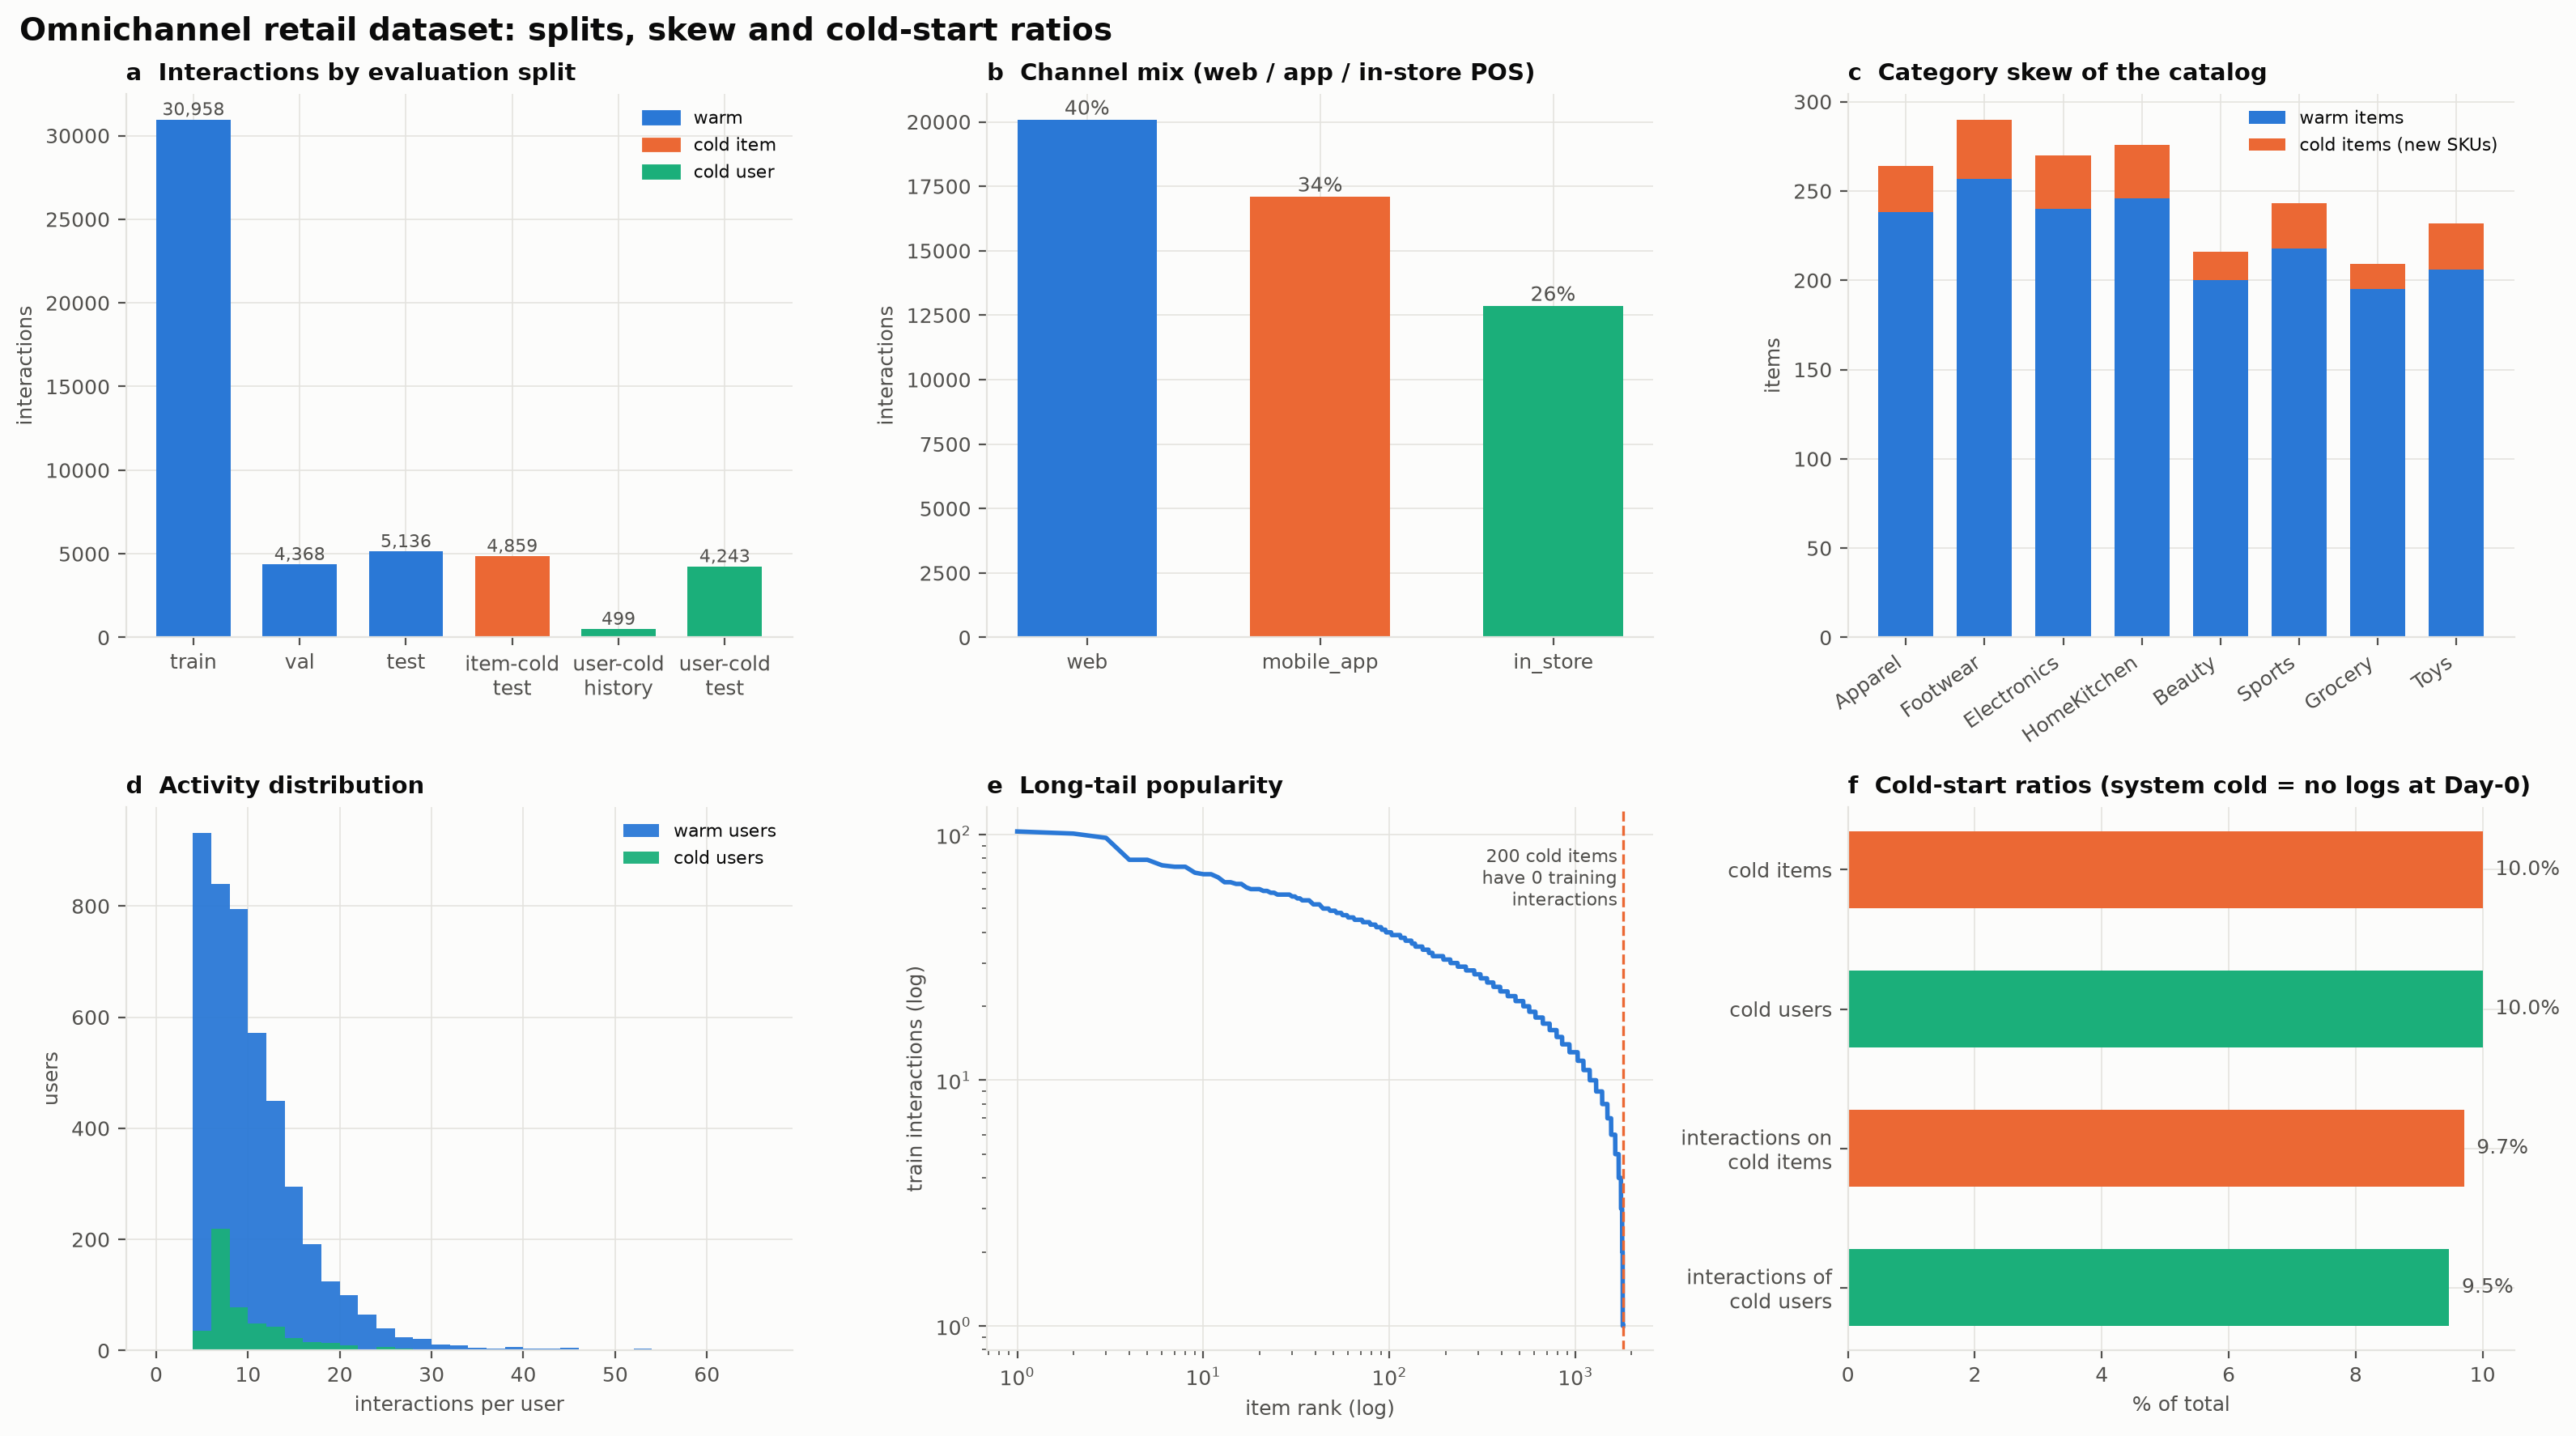

D:\Ramakrishna_D\Python\GitProjects\machinelearning\recommenders\cold-start_quantization_VAE\outputs\visualizations\02_feature_correlations.png


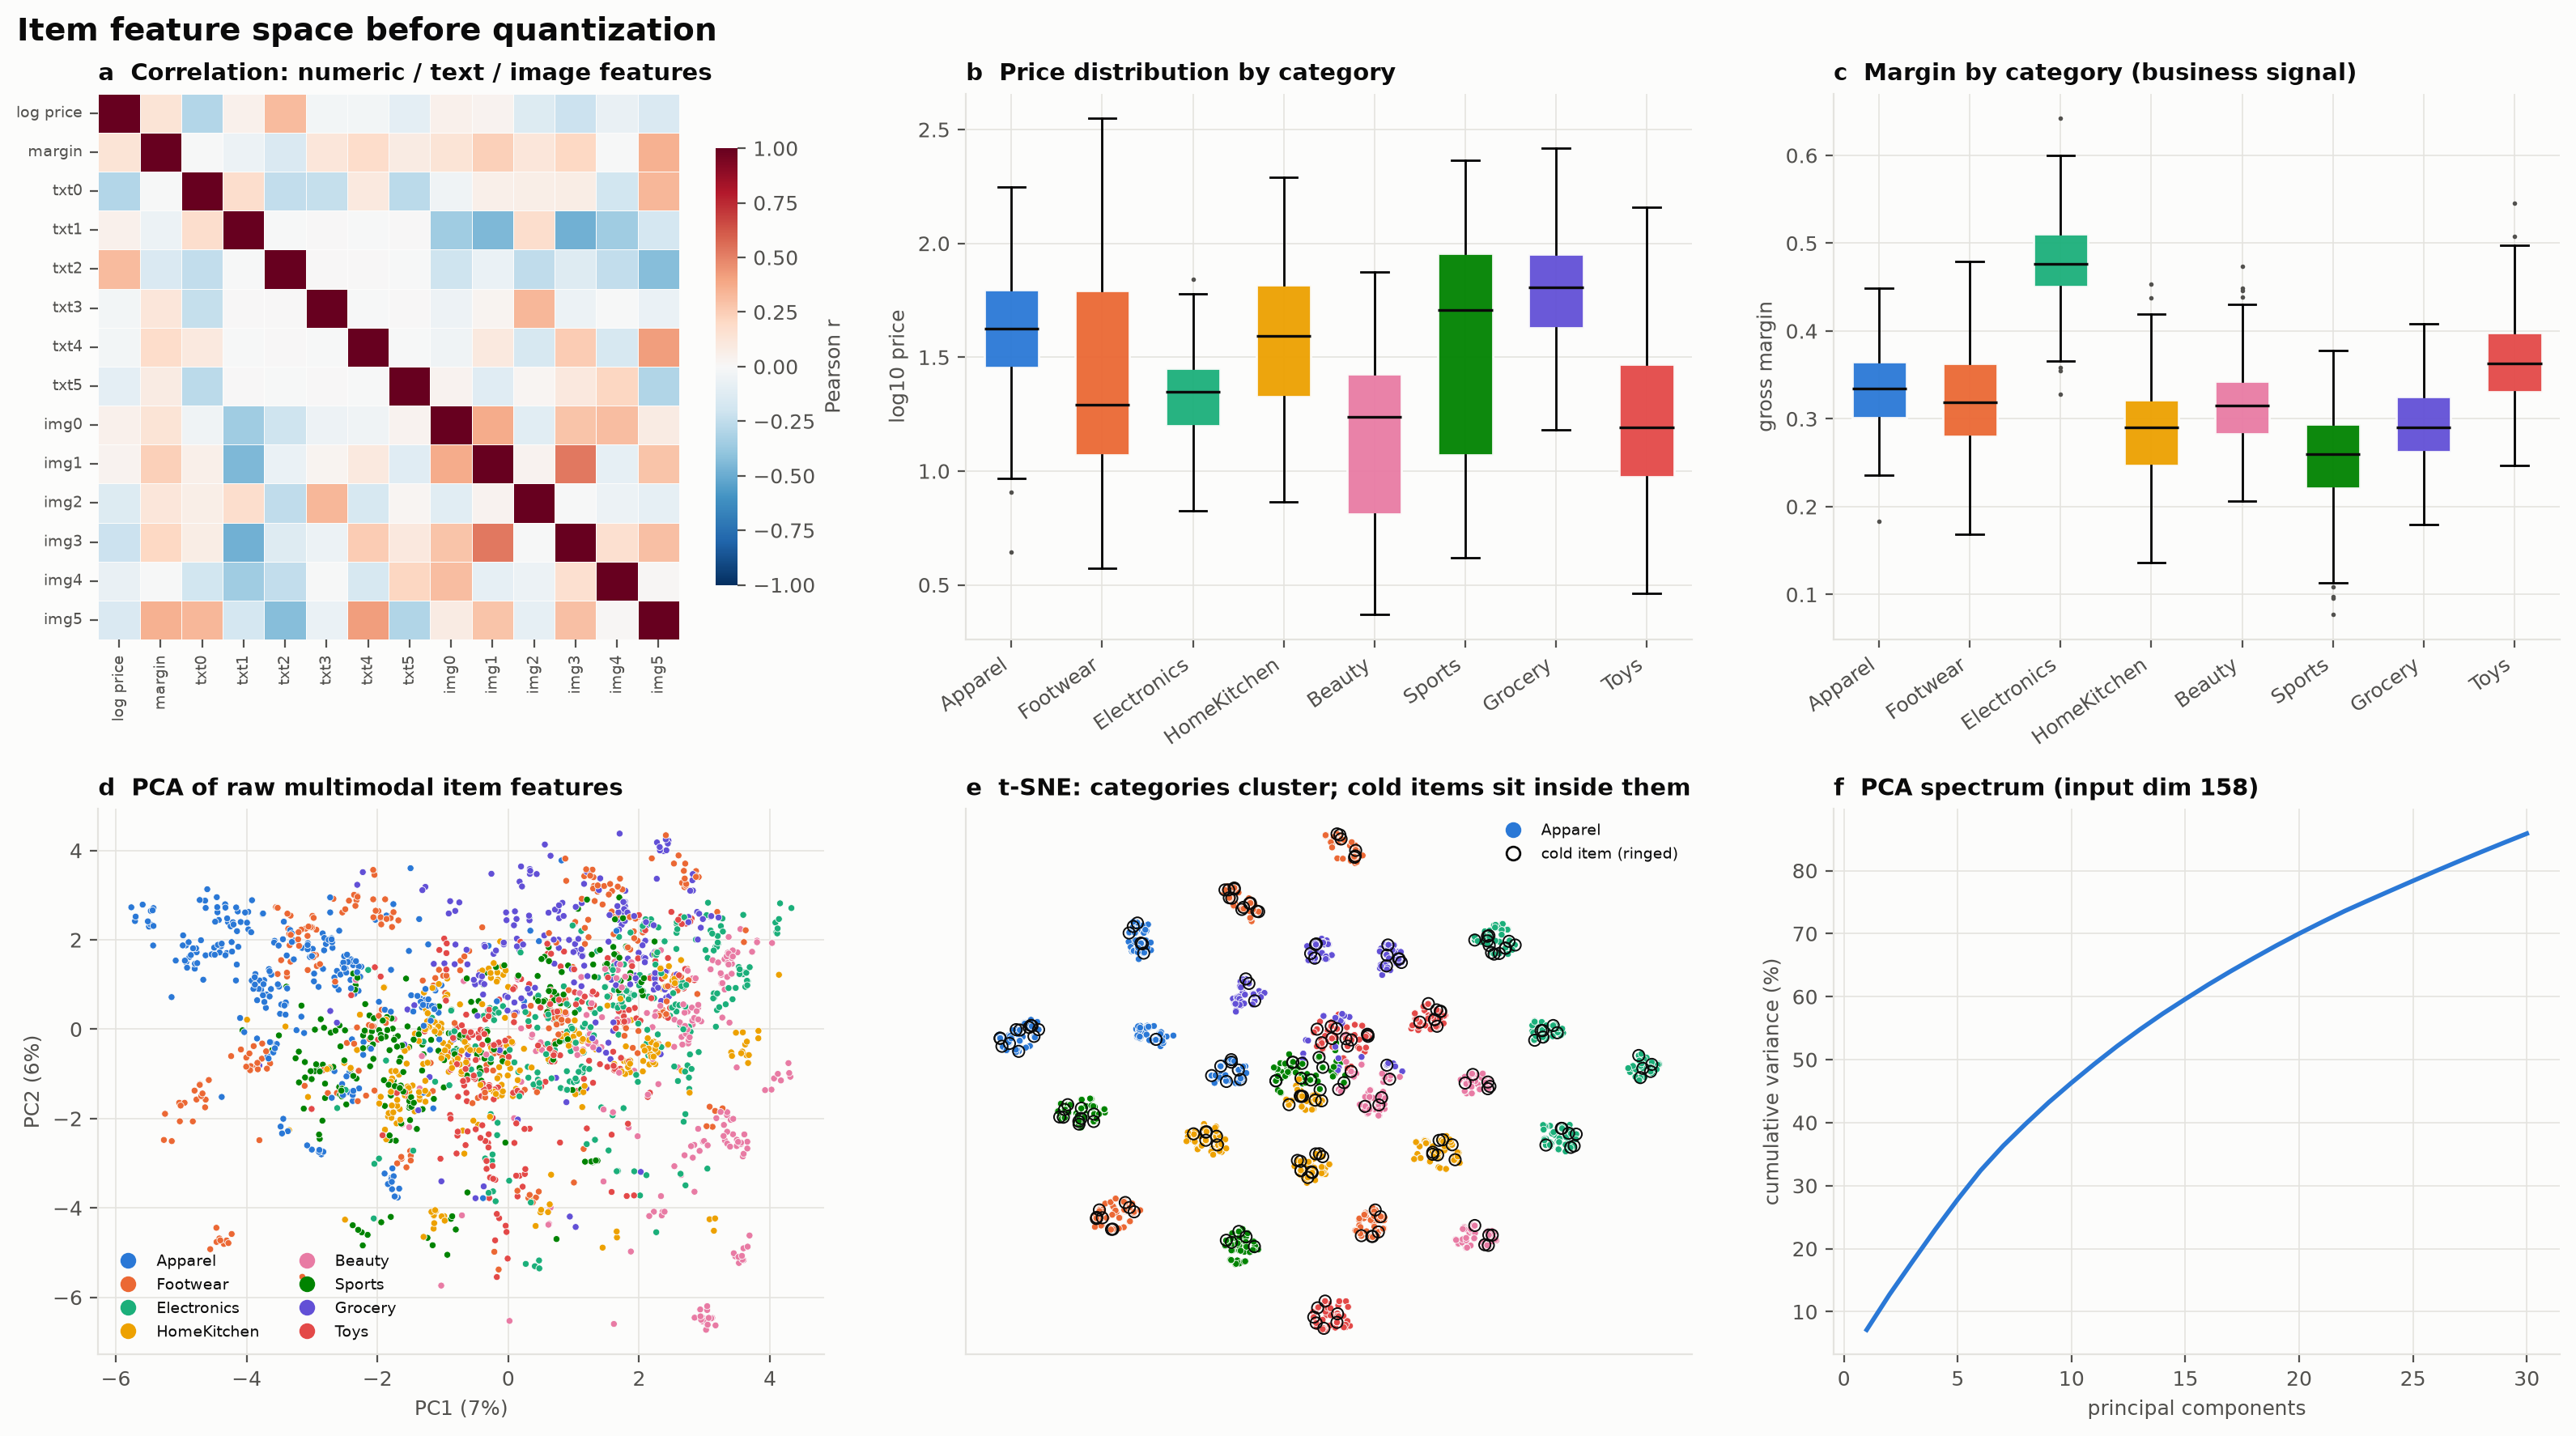

D:\Ramakrishna_D\Python\GitProjects\machinelearning\recommenders\cold-start_quantization_VAE\outputs\visualizations\03_vq_vs_rq_training_curves.png


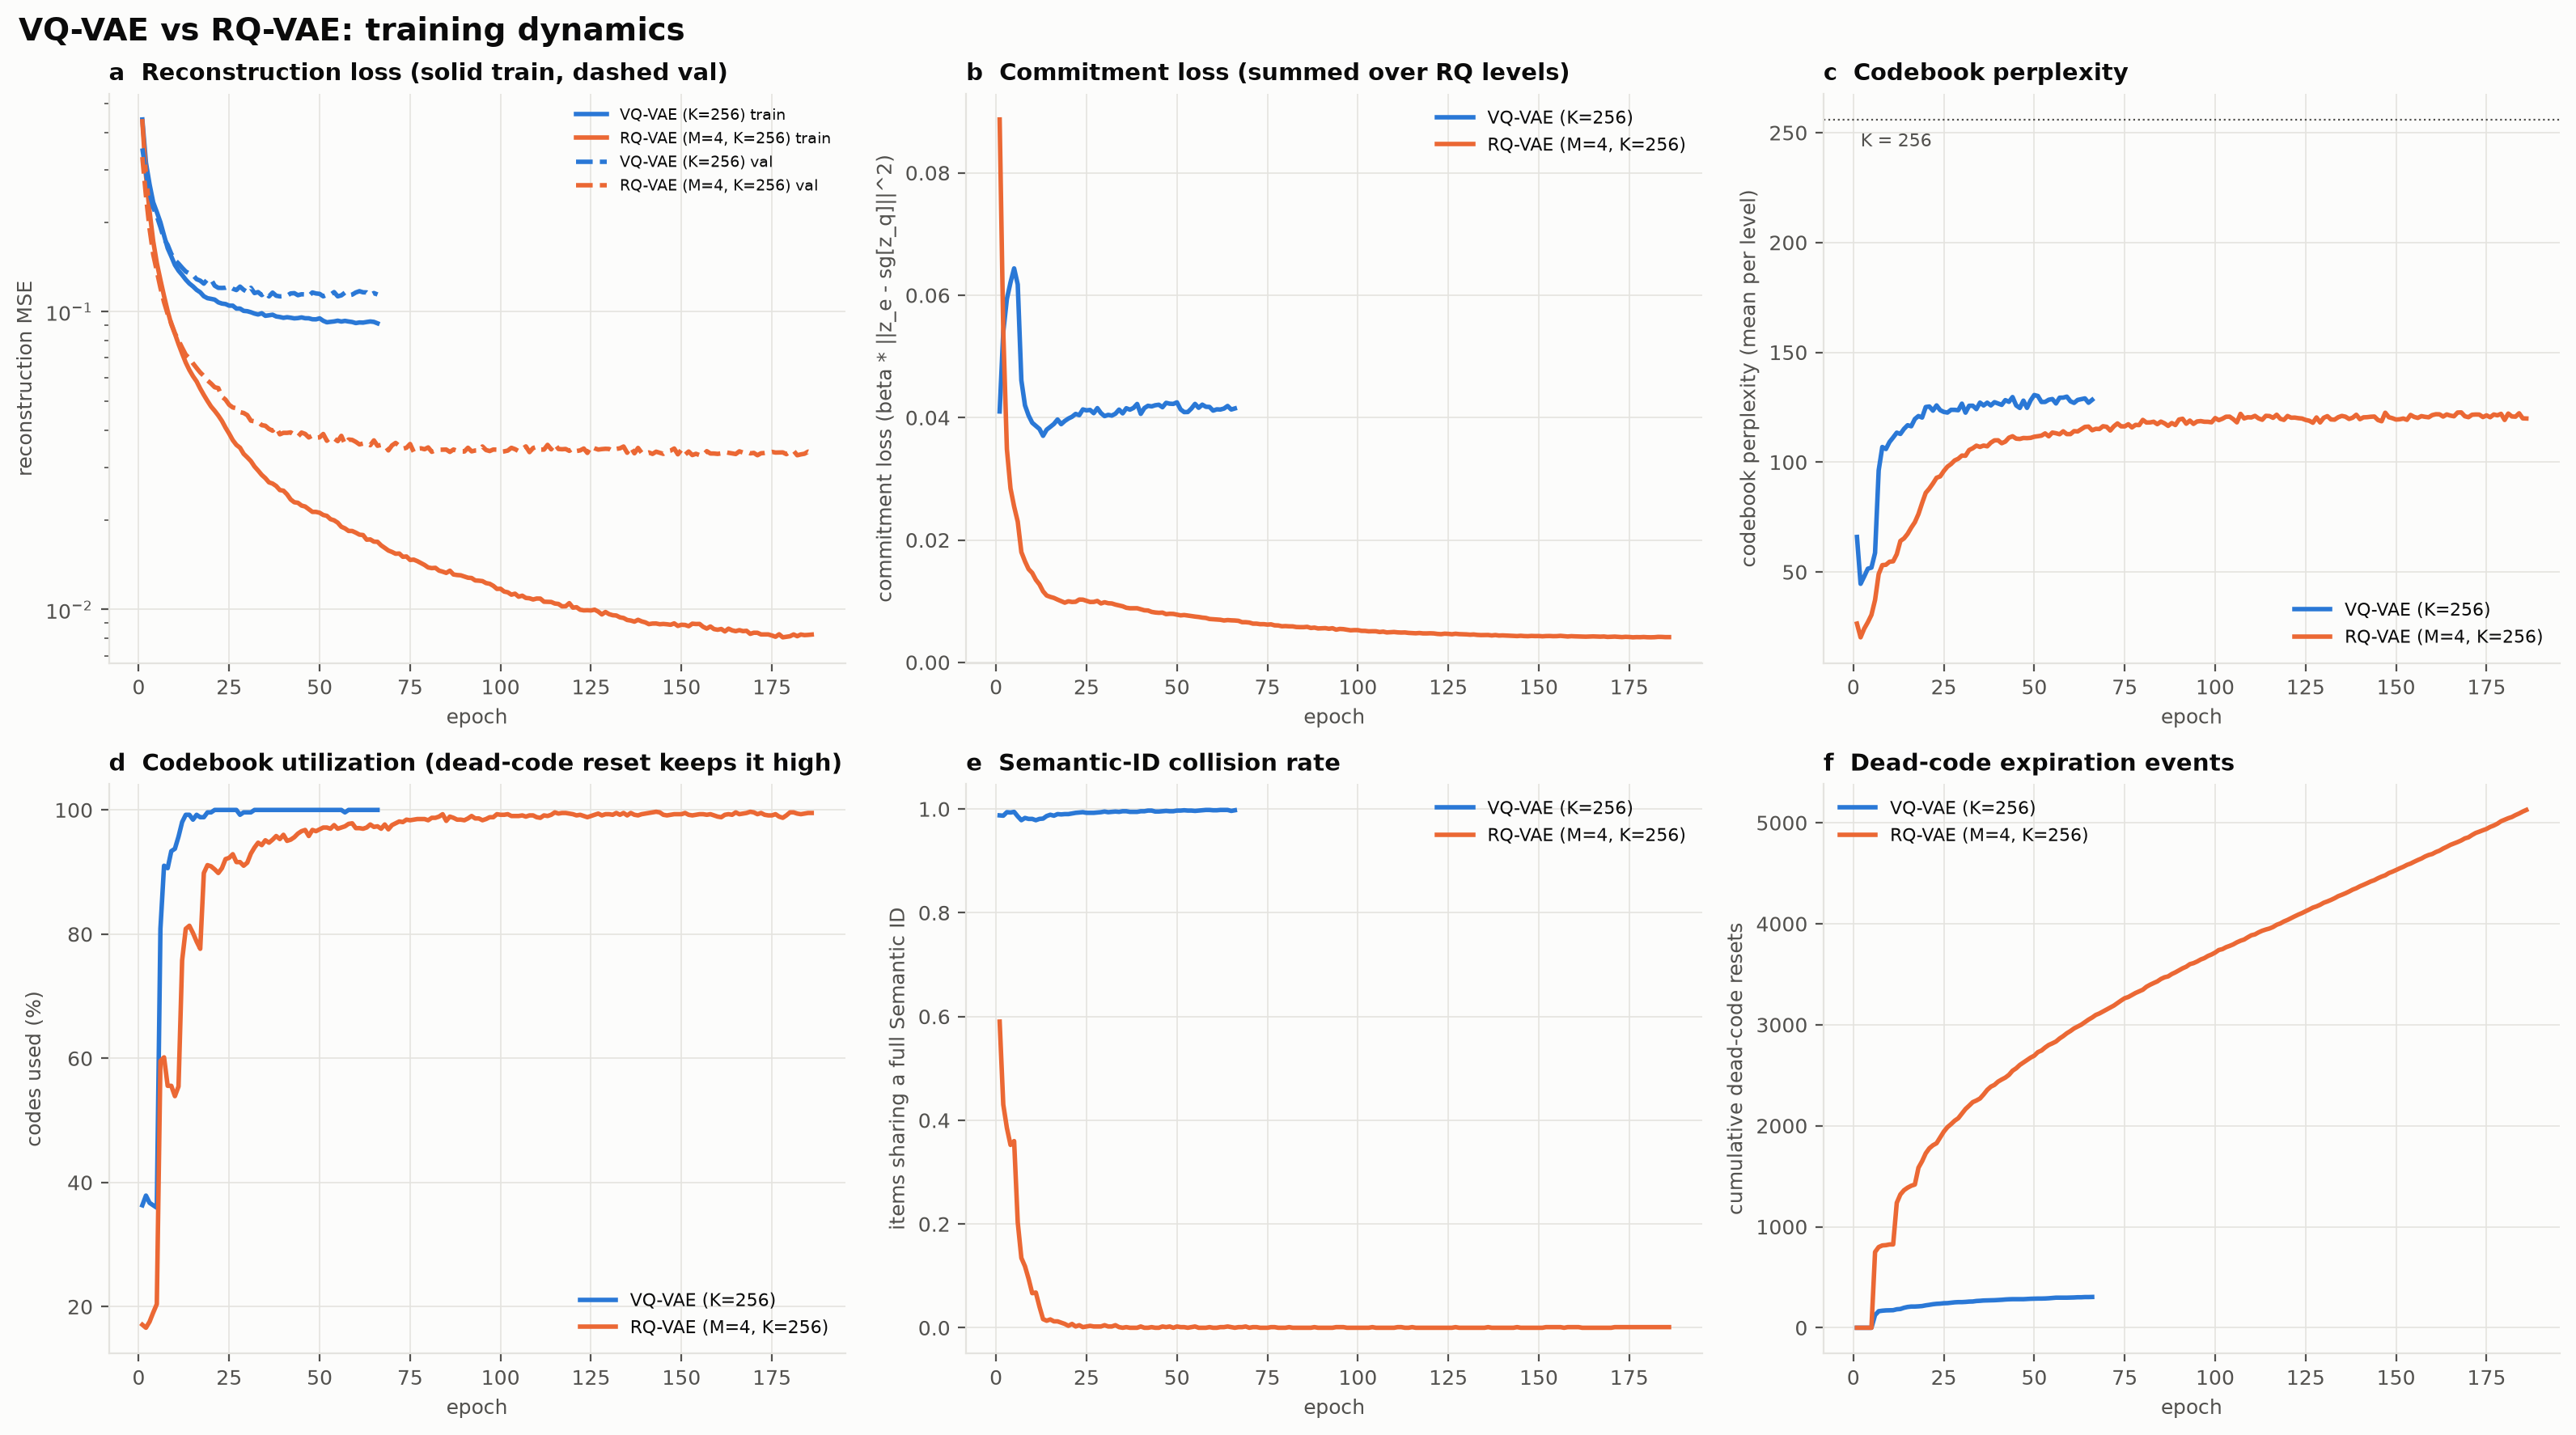

D:\Ramakrishna_D\Python\GitProjects\machinelearning\recommenders\cold-start_quantization_VAE\outputs\visualizations\04_codebook_utilization.png


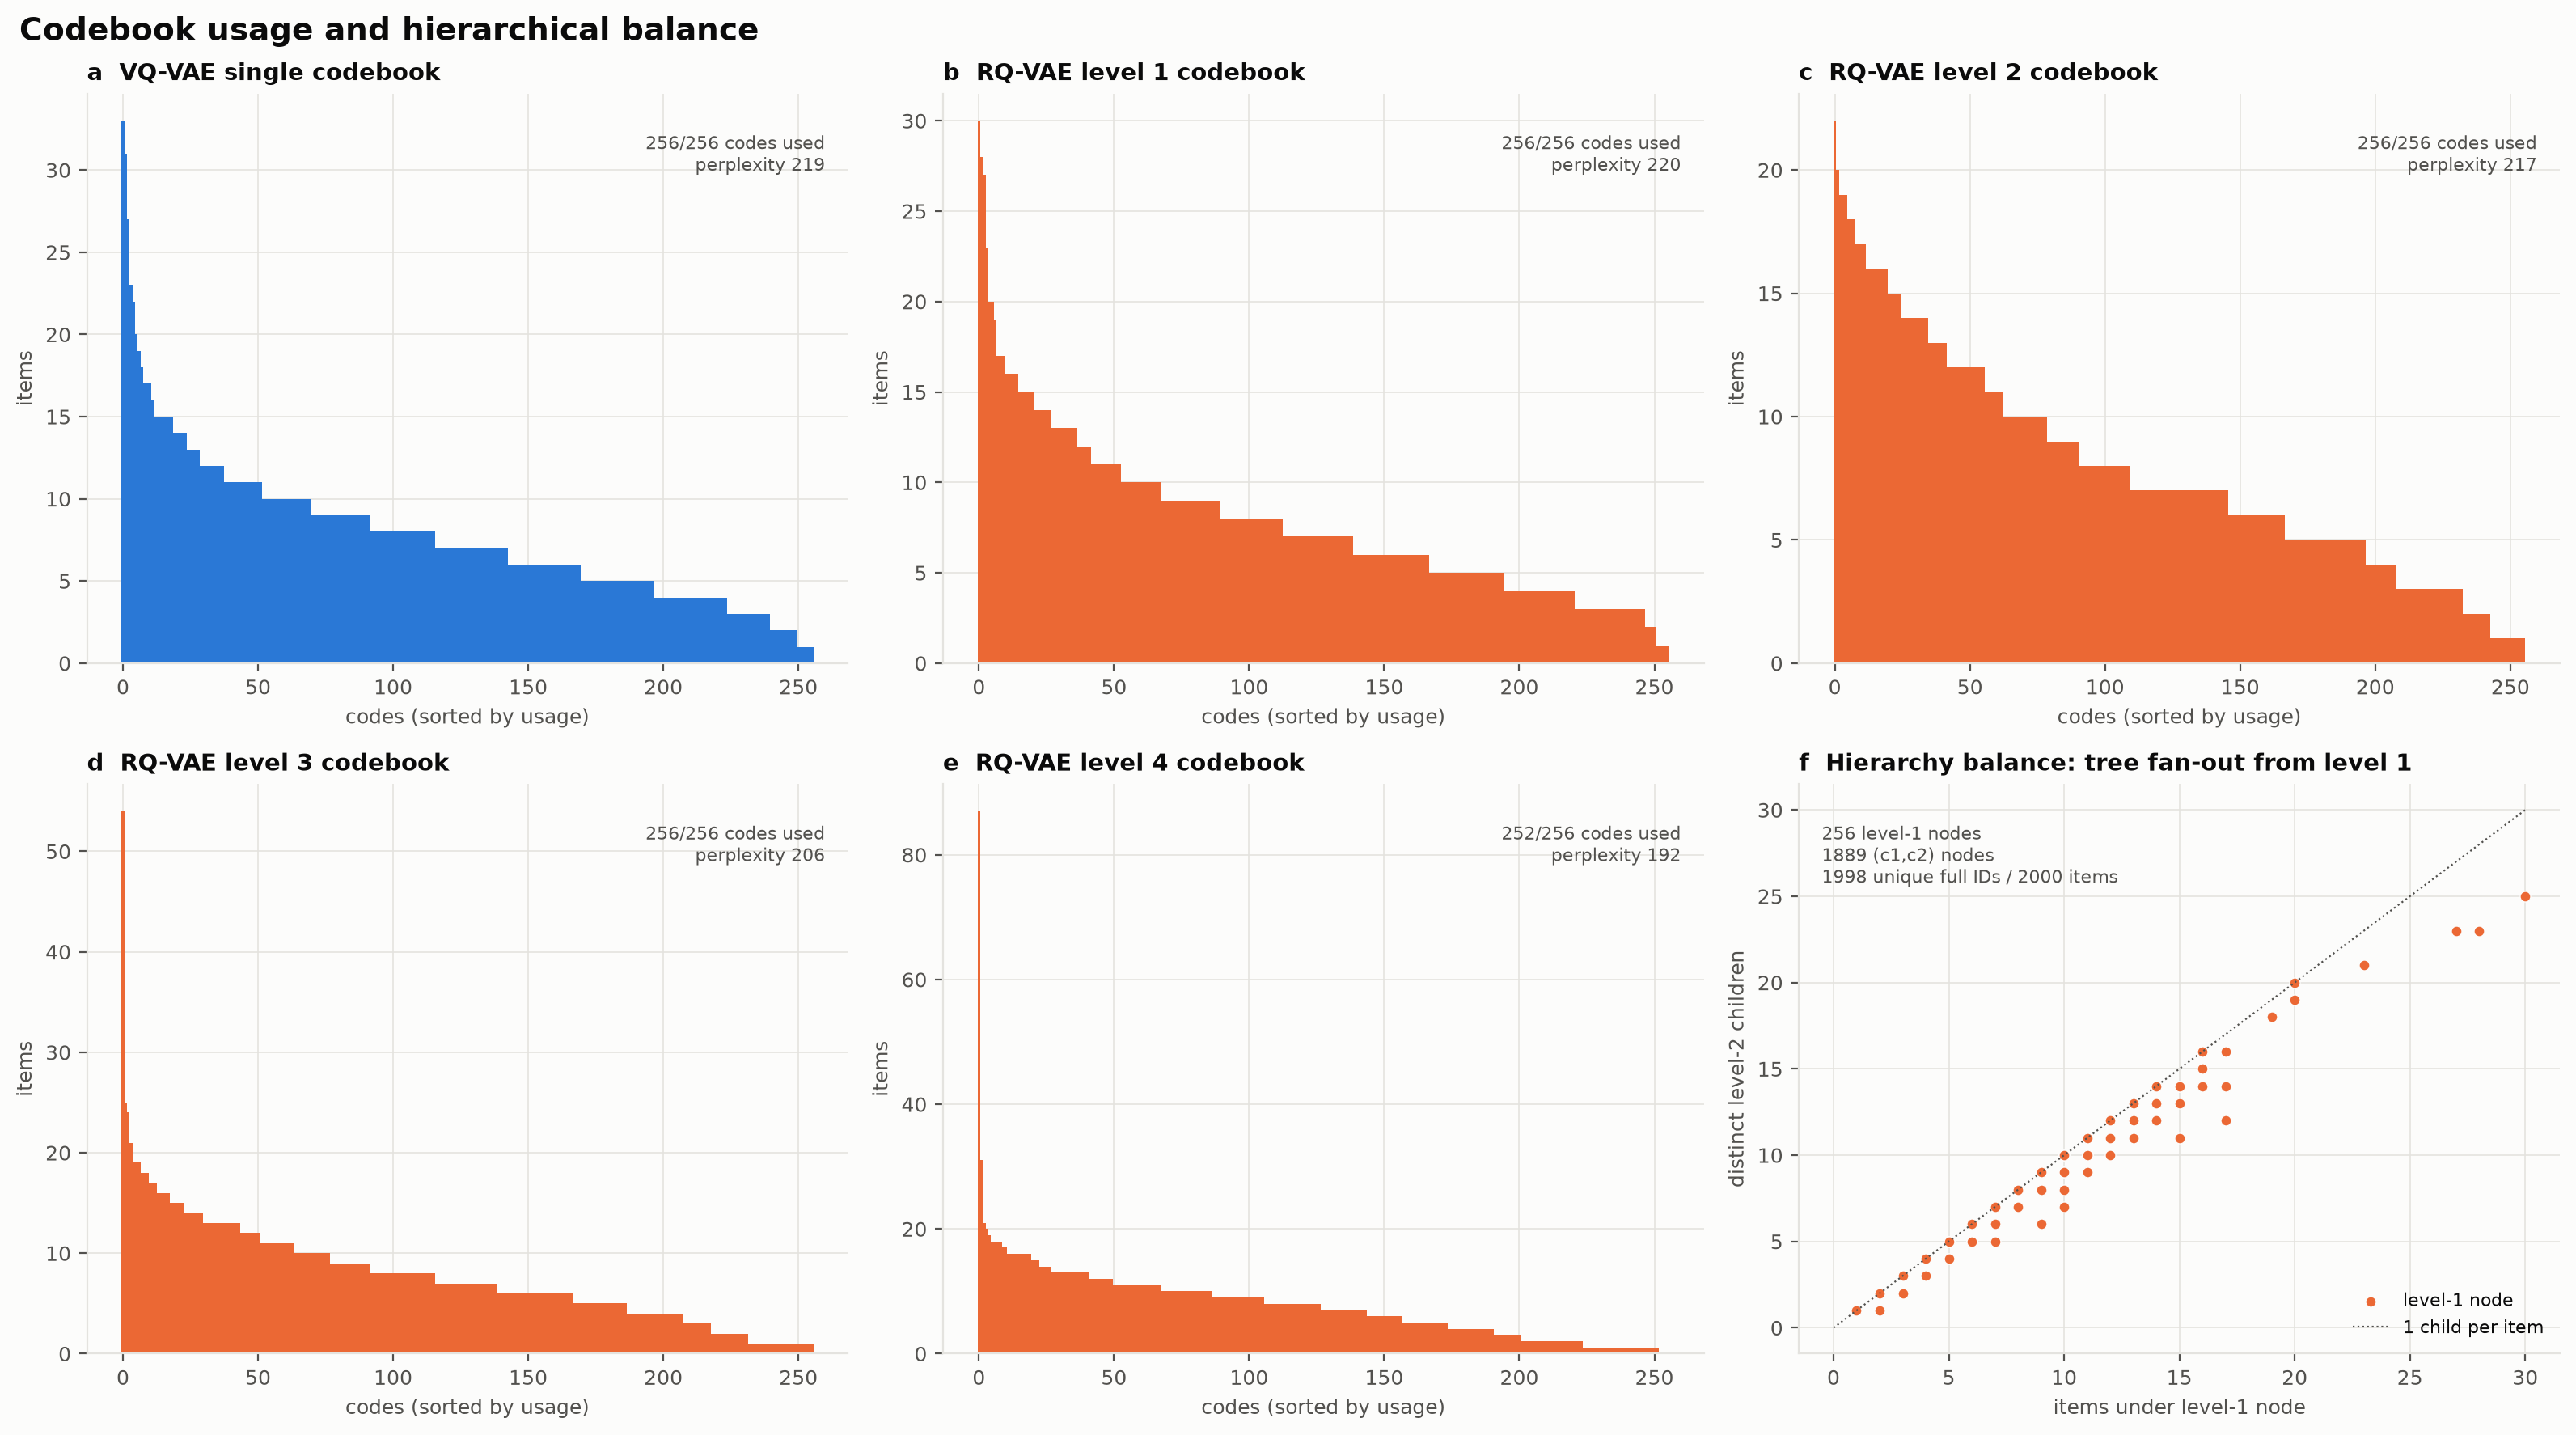

D:\Ramakrishna_D\Python\GitProjects\machinelearning\recommenders\cold-start_quantization_VAE\outputs\visualizations\05_semantic_id_clusters.png


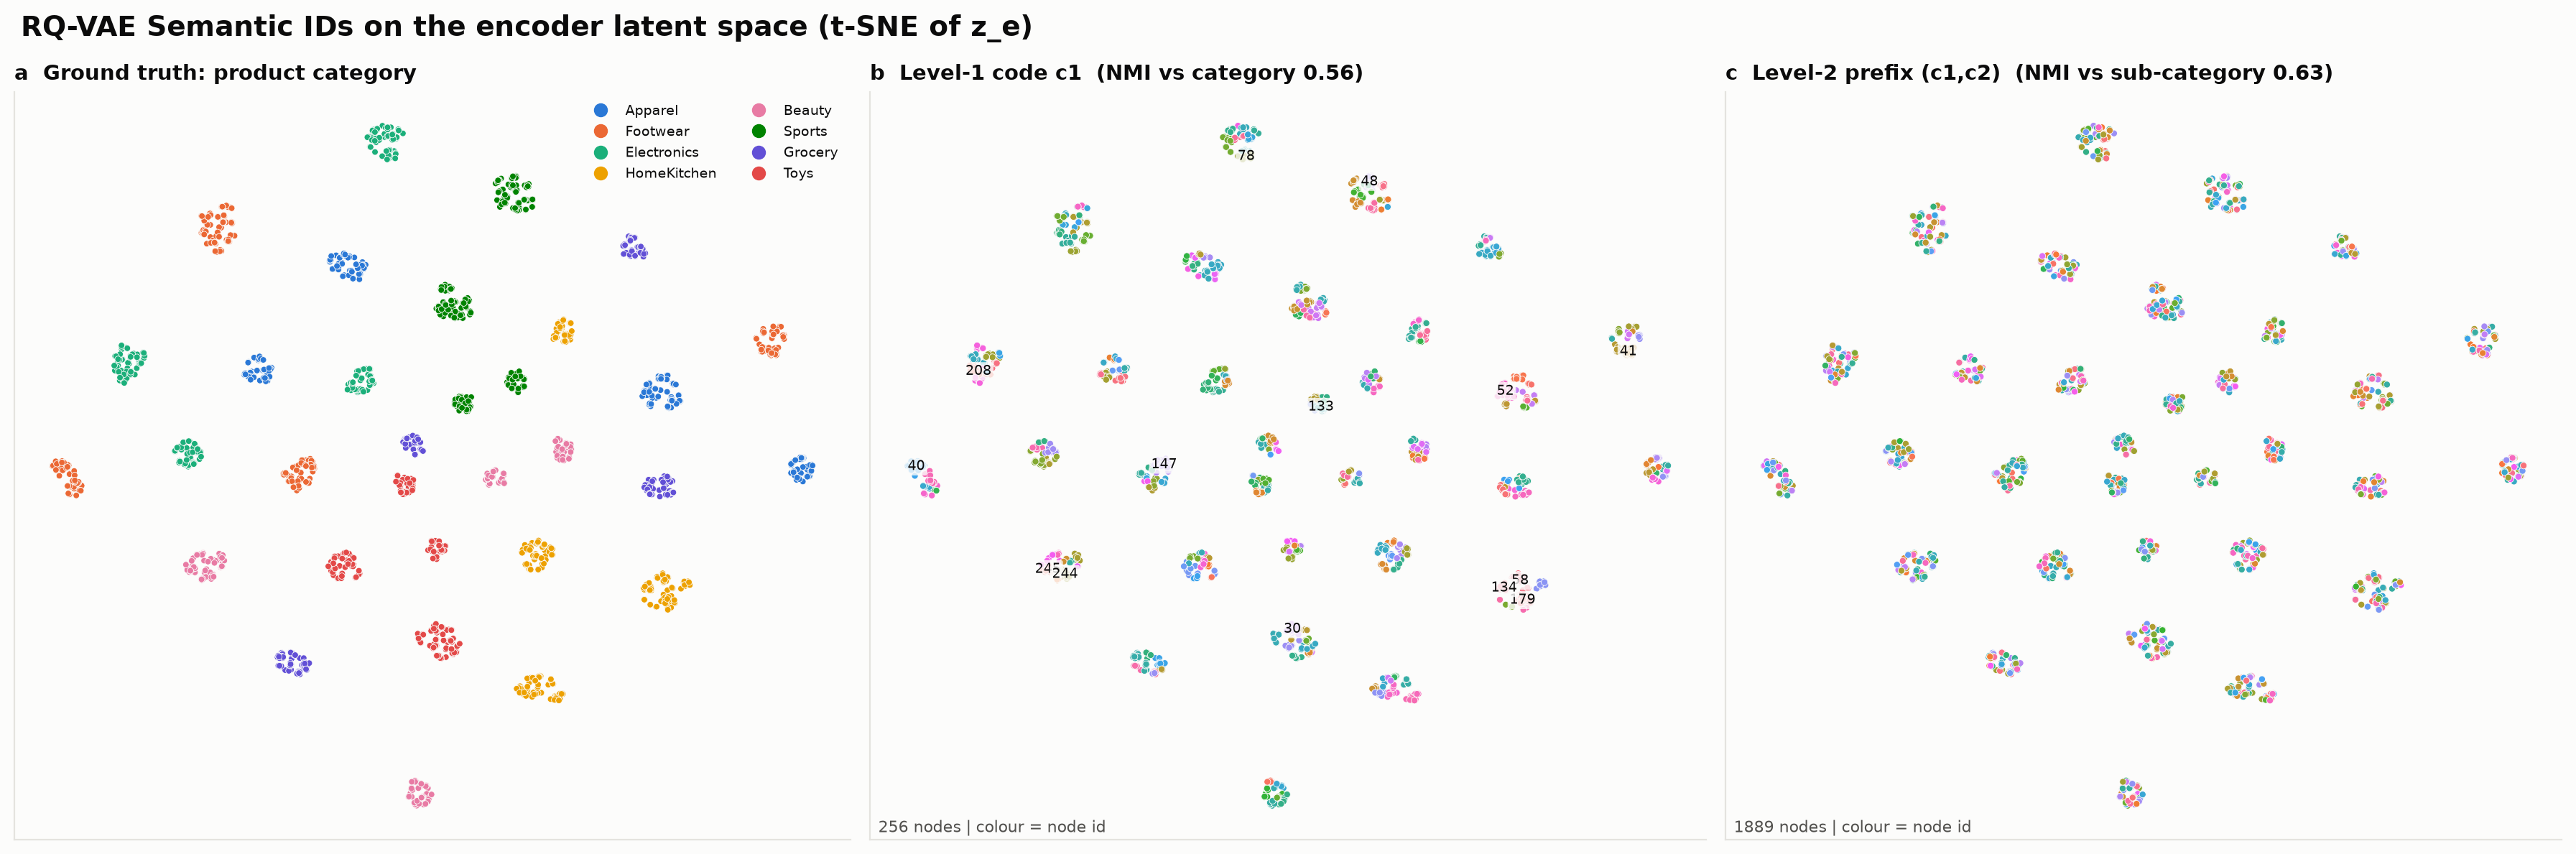

D:\Ramakrishna_D\Python\GitProjects\machinelearning\recommenders\cold-start_quantization_VAE\outputs\visualizations\06_model_comparison.png


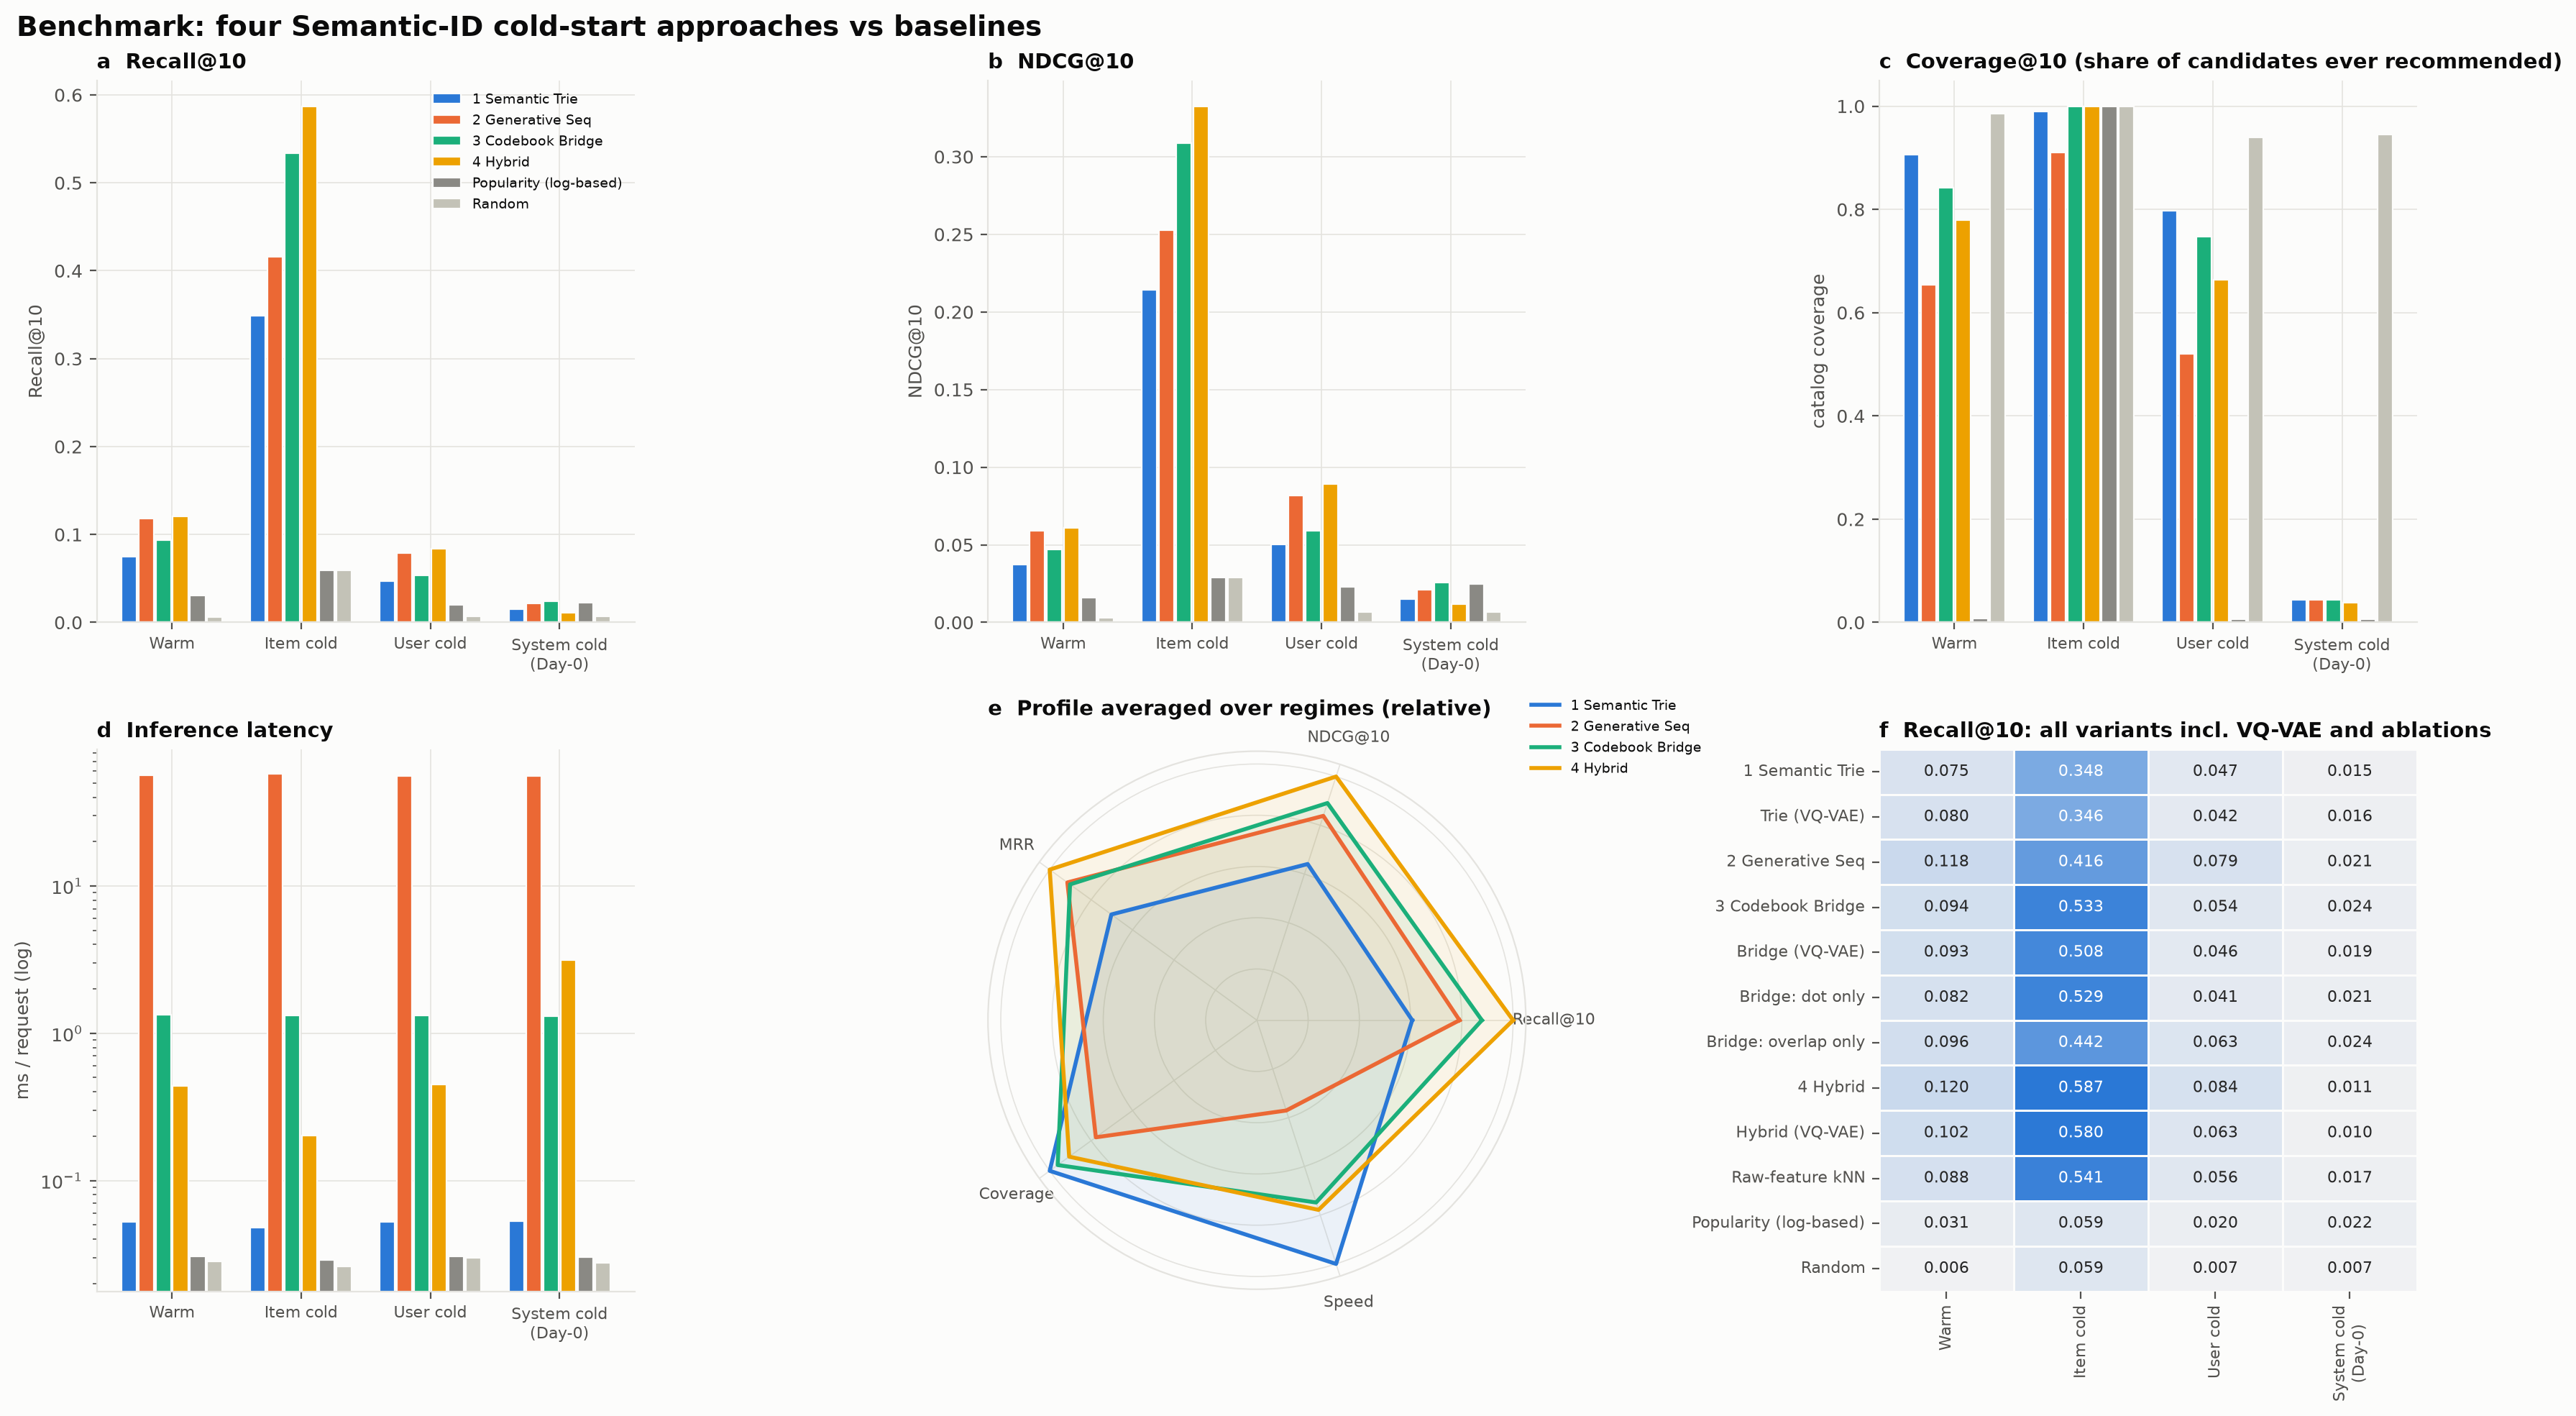

In [23]:
t0 = time.time()
paths = make_all(bundle, df)
print(f"{time.time() - t0:.0f}s")
for k, p in paths.items():
    print(p)
    display(Image(filename=p, width=1300))

## 7. Cold-start scenario demos (plain Python; same logic the serving layer would call)

In [24]:
import time
SEGMENTS = [(r, a, c) for r in REGIONS for a in AGE_BANDS for c in CATEGORIES]


def items_frame(b, scored, ctx=None):
    cat, rows = b.rq, []
    for i, sc in scored:
        r = cat.items.iloc[i]
        rec = {"item_id": int(i), "title": r["title"], "category": r["category"], "subcategory": r["subcategory"],
               "price": round(float(r["price"]), 2), "margin": round(float(r["margin"]), 2), "new": bool(r["is_cold"]),
               "semantic_id": cat.semantic_id_str(i), "score": round(float(sc), 4)}
        if ctx is not None:
            seed, depth = b.main["semantic_trie"].match_depth(i, ctx)
            rec["shared_prefix_depth"] = depth
            rec["matched_seed"] = cat.items.iloc[seed]["title"] if seed is not None and depth > 0 else ""
        rows.append(rec)
    return pd.DataFrame(rows)


def item_cold_start(b, rec, top_k_items=8, top_k_segments=5):
    """Brand-new SKU: encode with RQ-VAE on the fly -> Semantic ID, target segments, look-alikes."""
    cat, bridge, hybrid = b.rq, b.main["codebook_bridge"], b.main["hybrid"]
    X = b.dataset["featurizer"].transform_records([rec])
    codes, zq, _ = cat.encode_features(X)
    vq_code = b.vq.encode_features(X)[0][0][0]
    codes, zq = codes[0], zq[0]
    u, lps = bridge.user_forward([UserContext(region=r, age_band=a, intent_cat=c) for r, a, c in SEGMENTS])
    v = bridge.embed_new_items(zq[None])[0]
    dot = (u @ v).cpu().numpy()
    overlap = sum(bridge.level_w[l] * lps[l].cpu().numpy()[:, codes[l]] for l in range(cat.M))
    fused = bridge._zn(dot) + 0.5 * bridge._zn(np.asarray(overlap))
    seg = pd.DataFrame([{"region": SEGMENTS[j][0], "age_band": SEGMENTS[j][1], "intent_category": SEGMENTS[j][2],
                         "affinity_z": round(float(fused[j]), 3)} for j in np.argsort(-fused)[:top_k_segments]])
    sim = items_frame(b, hybrid.similar_items(zq, top_k_items))
    sim["shared_prefix_depth"] = [int(np.argmin(np.append(cat.codes[i] == codes, False))) for i in sim["item_id"]]
    sharing = {f"c1..c{d}": int((cat.codes[:, :d] == codes[:d]).all(1).sum()) for d in range(1, cat.M + 1)}
    return {"semantic_id": "-".join(map(str, codes)), "vq_vae_code": int(vq_code), "catalog_items_sharing_prefix": sharing,
            "target_segments": seg, "similar_items": sim}


def user_cold_start(b, approach="hybrid", k=10, **ctx_kwargs):
    ctx = UserContext(regime="user_cold", **ctx_kwargs)
    excl = set(ctx.history) | ({ctx.click_item} if ctx.click_item is not None else set())
    t0 = time.perf_counter()
    res = b.main[approach].recommend(ctx, k, None, excl)
    ms = (time.perf_counter() - t0) * 1000
    return items_frame(b, res, ctx), ms, b.main["codebook_bridge"].predicted_codes(ctx, 3)


def system_cold_start(b, landing_category=None, k=10):
    ctx = UserContext(intent_cat=landing_category, regime="system_cold")
    t0 = time.perf_counter()
    res = b.main["hybrid"].recommend(ctx, k, None, set())
    ms = (time.perf_counter() - t0) * 1000
    df_ = items_frame(b, res)
    df_["level1_code"] = [b.rq.codes[i, 0] for i in df_["item_id"]]
    return df_, ms


def compare_approaches(b, ctx, k=5, candidates=None):
    out = {}
    for name in ("semantic_trie", "generative_seq", "codebook_bridge", "hybrid"):
        t0 = time.perf_counter()
        res = b.main[name].recommend(ctx, k, candidates, set(ctx.history) | ({ctx.click_item} if ctx.click_item is not None else set()))
        out[name] = (items_frame(b, res), (time.perf_counter() - t0) * 1000)
    return out


def inspect_semantic_id(b, item_id, k=6):
    cat = b.rq
    codes, residual = cat.codes[item_id], cat.ze[item_id].copy()
    base, rows = float(np.linalg.norm(residual)), []
    for l in range(cat.M):
        node = np.where((cat.codes[:, :l + 1] == codes[:l + 1]).all(1))[0]
        residual = residual - cat.model.quantizers[l].embedding.detach().cpu().numpy()[codes[l]]
        vals, cnt = np.unique(cat.items["category"].values[node], return_counts=True)
        rows.append({"level": l + 1, "code": int(codes[l]), "node_size": len(node), "dominant_category": vals[np.argmax(cnt)],
                     "purity": round(float(cnt.max() / len(node)), 2),
                     "residual_%_of_latent": round(100 * float(np.linalg.norm(residual)) / base, 1)})
    return pd.DataFrame(rows), items_frame(bundle, bundle.main["hybrid"].similar_items(cat.zq[item_id], k, exclude={item_id}))


### 7.1 Item cold-start - a brand-new SKU with zero interactions

In [25]:
new_sku = {"category": "Footwear", "subcategory": None, "brand": "Nova", "price": 89.99, "color": "black", "material": "leather",
           "description": "Nova black leather chelsea ankle boot, waterproof, premium everyday boot"}
r = item_cold_start(bundle, new_sku)
print("Semantic ID (c1-c2-c3-c4):", r["semantic_id"], "| VQ-VAE single code:", r["vq_vae_code"])
print("catalog items sharing prefix:", r["catalog_items_sharing_prefix"])
display(r["target_segments"]); display(r["similar_items"])

Semantic ID (c1-c2-c3-c4): 147-89-254-209 | VQ-VAE single code: 223
catalog items sharing prefix: {'c1..c1': 27, 'c1..c2': 0, 'c1..c3': 0, 'c1..c4': 0}


,region,age_band,intent_category,affinity_z
0,north_america,35-44,Footwear,3.981
1,north_america,35-44,HomeKitchen,3.144
2,latam,18-24,Grocery,3.012
3,latam,35-44,Grocery,2.816
4,north_america,18-24,HomeKitchen,2.641


,item_id,title,category,subcategory,price,margin,new,semantic_id,score,shared_prefix_depth
0,1878,Aster Grey Boots,Footwear,Boots,16.44,0.34,False,147-173-46-155,0.8935,1
1,1529,Umbra Grey Boots,Footwear,Boots,7.39,0.25,False,147-109-36-249,0.8847,1
2,1576,Vertex Green Boots,Footwear,Boots,15.55,0.30,False,147-104-40-156,0.8833,1
3,367,Helio Grey Boots,Footwear,Boots,8.40,0.34,True,147-55-25-38,0.8811,1
4,1115,Ember Beige Boots,Footwear,Boots,10.89,0.28,False,147-47-103-74,0.8805,1
5,978,Quill Grey Boots,Footwear,Boots,10.16,0.25,False,147-173-140-91,0.8803,1
6,1336,Umbra Beige Boots,Footwear,Boots,13.19,0.29,False,147-47-22-252,0.8745,1
7,1559,Umbra Black Boots,Footwear,Boots,8.54,0.29,False,147-221-84-55,0.8713,1


### 7.2 User cold-start - a first-time visitor (context + initial click, 1 prior interaction)

In [26]:
items = bundle.rq.items
click = int(items[(~items.is_cold) & (items.subcategory == "Headphones")].item_id.iloc[0])
hist = [int(items[(~items.is_cold) & (items.subcategory == "Smartwatches")].item_id.iloc[0])]
visitor = dict(channel="mobile_app", device="ios", region="europe", age_band="25-34", intent_cat="Electronics",
               click_item=click, history=hist)
print("clicked:", items.title[click], "| history:", [items.title[h] for h in hist])
for approach in ("hybrid", "semantic_trie", "generative_seq", "codebook_bridge"):
    df_, ms, pred = user_cold_start(bundle, approach, 5, **visitor)
    print(f"\n--- {approach} ({ms:.1f} ms)")
    display(df_.drop(columns=["category", "price", "margin"]))
print("\nbridge-predicted top codes per level:", [[c for c, _ in lv] for lv in pred])

clicked: Vertex Navy Headphones | history: ['Crest Black Smartwatches']

--- hybrid (0.4 ms)


,item_id,title,subcategory,new,semantic_id,score,shared_prefix_depth,matched_seed
0,631,Zephyr Red Headphones,Headphones,False,130-235-30-226,0.6629,0,
1,850,Aster Red Headphones,Headphones,False,47-139-194-209,0.6411,0,
2,8,Ember Grey Headphones,Headphones,False,78-247-241-200,0.6390,1,Vertex Navy Headphones
3,1948,Quill Red Headphones,Headphones,False,130-67-25-226,0.6370,0,
4,445,Crest Navy Headphones,Headphones,False,167-62-73-112,0.6349,0,



--- semantic_trie (0.3 ms)


,item_id,title,subcategory,new,semantic_id,score,shared_prefix_depth,matched_seed
0,1231,Juno Black Smartwatches,Smartwatches,False,172-232-210-97,0.0873,2,Crest Black Smartwatches
1,8,Ember Grey Headphones,Headphones,False,78-247-241-200,0.0381,1,Vertex Navy Headphones
2,592,Gaia Brown Headphones,Headphones,False,78-141-170-43,0.0381,1,Vertex Navy Headphones
3,44,Nimbus Blue Headphones,Headphones,False,78-153-78-171,0.0381,1,Vertex Navy Headphones
4,1484,Gaia Blue Headphones,Headphones,False,78-231-169-197,0.0380,1,Vertex Navy Headphones



--- generative_seq (77.7 ms)

,item_id,title,subcategory,new,semantic_id,score,shared_prefix_depth,matched_seed
0,26,Lumen Brown Headphones,Headphones,False,167-100-197-193,-4.1373,0,
1,1957,Delta Brown Smartwatches,Smartwatches,False,172-200-12-77,-4.2056,1,Crest Black Smartwatches
2,1218,Nimbus Pink Smartwatches,Smartwatches,False,172-108-150-90,-4.3345,1,Crest Black Smartwatches
3,1740,Zephyr Brown Smartwatches,Smartwatches,False,172-8-89-144,-4.5728,1,Crest Black Smartwatches
4,669,Quill Pink Headphones,Headphones,False,167-146-186-10,-4.5904,0,



--- codebook_bridge (2.1 ms)


,item_id,title,subcategory,new,semantic_id,score,shared_prefix_depth,matched_seed
0,1204,Juno White Smartwatches,Smartwatches,False,227-169-254-69,3.0521,0,
1,1826,Nimbus Grey Smartphones,Smartphones,False,149-173-232-169,3.0349,0,
2,1567,Xenon White Smartwatches,Smartwatches,True,227-194-9-238,2.8978,0,
3,937,Nimbus Grey Smartwatches,Smartwatches,False,127-173-197-224,2.8478,0,
4,1035,Yonder White Organic,Organic,False,98-252-244-54,2.7753,0,



bridge-predicted top codes per level: [[40, 217, 149], [164, 102, 101], [26, 24, 139], [68, 211, 39]]


### 7.3 System cold-start - Day-0 anonymous session (no logs): diversified, high-margin cluster representatives

In [27]:
df_, ms = system_cold_start(bundle, "Sports", 8)
print(f"{ms:.1f} ms | mean margin {df_.margin.mean():.2f} (catalog mean {bundle.rq.margin.mean():.2f}) | distinct level-1 clusters: {df_.level1_code.nunique()}")
display(df_)
df_, ms = system_cold_start(bundle, None, 8)
print("no landing category at all (global representatives):"); display(df_[["title", "category", "margin", "semantic_id", "level1_code"]])

1.3 ms | mean margin 0.40 (catalog mean 0.33) | distinct level-1 clusters: 6

,item_id,title,category,subcategory,price,margin,new,semantic_id,score,level1_code
0,445,Crest Navy Headphones,Electronics,Headphones,20.15,0.55,False,167-62-73-112,0.7282,167
1,1667,Bloom Black Cycling,Sports,Cycling,19.88,0.27,False,99-89-40-148,0.6990,99
2,1608,Bloom Brown Cycling,Sports,Cycling,9.79,0.25,False,123-172-81-186,0.7103,123
3,338,Nimbus Blue Headphones,Electronics,Headphones,23.03,0.56,False,167-65-32-231,0.7076,167
4,730,Bloom Navy Cycling,Sports,Cycling,12.66,0.29,False,99-214-145-155,0.7022,99
5,1615,Juno Red Headphones,Electronics,Headphones,31.73,0.56,False,83-255-119-9,0.6916,83
6,432,Zephyr Pink Cycling,Sports,Cycling,5.05,0.27,False,198-179-195-15,0.6933,198
7,1335,Delta Red Headphones,Electronics,Headphones,16.62,0.48,True,47-53-49-110,0.6918,47


no landing category at all (global representatives):


,title,category,margin,semantic_id,level1_code
0,Zephyr Red Laptops,Electronics,0.57,4-58-61-174,4
1,Ember Grey Headphones,Electronics,0.57,78-247-241-200,78
2,Vertex Red Laptops,Electronics,0.55,4-84-176-44,4
3,Gaia Brown Laptops,Electronics,0.60,171-156-219-33,171
4,Flux Grey BuildingSets,Toys,0.44,95-179-168-20,95
5,Crest Navy Headphones,Electronics,0.55,167-62-73-112,167
6,Juno Red Headphones,Electronics,0.56,83-255-119-9,83
7,Lumen Red Smartphones,Electronics,0.64,217-113-59-152,217


### 7.4 Compare all four approaches side by side

In [28]:
ctx = UserContext(history=hist, click_item=click, channel="mobile_app", device="ios", region="europe", age_band="25-34",
                  intent_cat="Electronics", regime="user_cold")
for scenario, cands in (("full catalog", None), ("new launches only (item cold-start)", bundle.rq.cold_ids)):
    print(f"\n===== {scenario}")
    res = compare_approaches(bundle, ctx, 5, cands)
    for name, (d_, ms) in res.items():
        print(f"{name:16s} {ms:7.1f} ms  ->", " | ".join(d_.semantic_id))
    sets = {n: set(d_.item_id) for n, (d_, _) in res.items()}
    names = list(sets)
    print("Jaccard:", {f"{a[:4]}~{b_[:4]}": round(len(sets[a] & sets[b_]) / max(len(sets[a] | sets[b_]), 1), 2)
                       for i, a in enumerate(names) for b_ in names[i + 1:]})


===== full catalog


semantic_trie        0.8 ms  -> 172-232-210-97 | 78-247-241-200 | 78-141-170-43 | 78-153-78-171 | 78-231-169-197
generative_seq      76.7 ms  -> 167-100-197-193 | 172-200-12-77 | 172-108-150-90 | 172-8-89-144 | 167-146-186-10
codebook_bridge      3.9 ms  -> 227-169-254-69 | 149-173-232-169 | 227-194-9-238 | 127-173-197-224 | 98-252-244-54
hybrid               1.1 ms  -> 130-235-30-226 | 47-139-194-209 | 78-247-241-200 | 130-67-25-226 | 167-62-73-112
Jaccard: {'sema~gene': 0.0, 'sema~code': 0.0, 'sema~hybr': 0.11, 'gene~code': 0.0, 'gene~hybr': 0.0, 'code~hybr': 0.0}

===== new launches only (item cold-start)


semantic_trie        0.6 ms  ->

 78-109-240-94 | 78-99-105-185 | 78-24-129-54 | 78-195-53-4 | 172-89-240-185


generative_seq      85.5 ms  -> 172-89-240-185 | 167-17-152-139 | 40-126-22-73 | 48-245-125-145 | 217-135-149-152
codebook_bridge      3.1 ms  -> 227-194-9-238 | 172-89-240-185 | 88-24-238-169 | 172-3-220-16 | 227-155-175-126
hybrid               1.0 ms  -> 167-132-181-234 | 47-53-49-110 | 47-156-184-252 | 78-109-240-94 | 130-27-80-33
Jaccard: {'sema~gene': 0.11, 'sema~code': 0.11, 'sema~hybr': 0.11, 'gene~code': 0.11, 'gene~hybr': 0.0, 'code~hybr': 0.0}


### 7.5 Inspect hierarchical Semantic-ID tokens

In [29]:
item_id = int(items[(~items.is_cold) & (items.subcategory == "Sneakers")].item_id.iloc[0])
print(items.loc[item_id, ["title", "category", "subcategory"]].tolist(), "->", bundle.rq.semantic_id_str(item_id))
tree, look = inspect_semantic_id(bundle, item_id)
display(tree); display(look)

['Helio Grey Sneakers', 'Footwear', 'Sneakers'] -> 116-224-249-50


,level,code,node_size,dominant_category,purity,residual_%_of_latent
0,1,116,12,Footwear,1.0,25.1
1,2,224,1,Footwear,1.0,17.7
2,3,249,1,Footwear,1.0,15.6
3,4,50,1,Footwear,1.0,12.6


,item_id,title,category,subcategory,price,margin,new,semantic_id,score
0,162,Helio Grey Sneakers,Footwear,Sneakers,6.84,0.24,True,116-211-249-50,0.9712
1,1835,Umbra Grey Sneakers,Footwear,Sneakers,8.59,0.30,False,116-14-121-18,0.9561
2,1521,Umbra Grey Sneakers,Footwear,Sneakers,12.64,0.32,False,116-125-121-18,0.9542
3,1082,Xenon Grey Sneakers,Footwear,Sneakers,10.46,0.20,False,116-19-244-140,0.9511
4,820,Umbra Grey Sneakers,Footwear,Sneakers,10.37,0.21,False,116-88-121-103,0.9462
5,126,Xenon Grey Sneakers,Footwear,Sneakers,18.39,0.32,False,116-98-37-143,0.9459


## 8. Output manifest

In [30]:
for d in (MODELS_DIR, LOGS_DIR, VIZ_DIR):
    files = sorted(p for p in d.glob("*") if p.is_file())
    print(f"{d.name}/ ({len(files)} files)")
    for p in files:
        print(f"   {p.name:45s} {p.stat().st_size / 1024:9.1f} KB")

models/ (9 files)
   codebook_bridge_rq.pt                            1721.8 KB
   codebook_bridge_vq.pt                             949.0 KB
   dataset.pkl                                      4855.4 KB
   generative_seq.pt                                3426.1 KB
   rq_codebooks.npz                                  257.0 KB
   rq_vae.pt                                        3047.2 KB
   scalers.json                                        3.4 KB
   semantic_id_map.json                              505.0 KB
   vq_vae.pt                                        2656.1 KB
logs/ (7 files)
   dataset_summary.json                                0.3 KB
   evaluation_metrics.csv                              9.1 KB
   pipeline_timing.json                                0.1 KB
   recommender_training_logs.json                     18.7 KB
   tokenizer_epoch_metrics.csv                        28.6 KB
   training_logs.json                                 95.0 KB
   validation_logs.json             